<a href="https://colab.research.google.com/github/sania8/emnlp-graph/blob/main/GRAPHwithVLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!nvidia-smi

import torch
import os
import platform

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")

print("Python:", platform.python_version())

Tue Nov  3 23:48:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   35C    P0             56W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
import importlib.util

if importlib.util.find_spec("torch_geometric") is None:
    !pip install -q torch-geometric

import torch_geometric
from torch_geometric.nn import RGCNConv

print("PyTorch Geometric:", torch_geometric.__version__)
print("R-GCN layer imported successfully!")

PyTorch Geometric: 2.8.1
R-GCN layer imported successfully!


In [8]:
PROJECT_DIR = "/content/drive/MyDrive/KG_VLM_Research"

directories = [
    "data/raw",
    "data/processed",
    "graphs",
    "checkpoints",
    "logs",
    "results",
    "configs"
]

for directory in directories:
    os.makedirs(os.path.join(PROJECT_DIR, directory), exist_ok=True)

print("Project structure created:", PROJECT_DIR)

Project structure created: /content/drive/MyDrive/KG_VLM_Research


In [5]:
!pip install -q transformers accelerate datasets
!pip install -q torch-geometric
!pip install -q networkx pandas numpy scikit-learn
!pip install -q matplotlib seaborn tqdm pillow
!pip install -q peft bitsandbytes

Download GQA Scene graphs

In [9]:
import os
import zipfile
import requests

DATA_DIR = f"{PROJECT_DIR}/data/raw"

scene_graph_url = (
    "https://downloads.cs.stanford.edu/nlp/data/gqa/sceneGraphs.zip"
)

zip_path = f"{DATA_DIR}/sceneGraphs.zip"

if not os.path.exists(zip_path):
    response = requests.get(scene_graph_url, stream=True)
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024*1024):
            if chunk:
                f.write(chunk)

print("Scene graph archive downloaded.")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Archive contents:")
    print(zip_ref.namelist()[:20])
    zip_ref.extractall(DATA_DIR)

print("Extraction complete.")

Scene graph archive downloaded.
Archive contents:
['readme.txt', 'train_sceneGraphs.json', 'val_sceneGraphs.json']
Extraction complete.


In [10]:
import glob

json_files = glob.glob(
    f"{DATA_DIR}/**/*.json",
    recursive=True
)

print("JSON files found:")
for file in json_files:
    print(file)

JSON files found:
/content/drive/MyDrive/KG_VLM_Research/data/raw/train_sceneGraphs.json
/content/drive/MyDrive/KG_VLM_Research/data/raw/val_sceneGraphs.json


In [59]:
import json

TRAIN_GRAPH_PATH = "REPLACE_WITH_TRAIN_SCENEGRAPH_PATH"

with open(TRAIN_GRAPH_PATH, "r") as f:
    train_graphs = json.load(f)

print("Number of training images:", len(train_graphs))

first_image_id = next(iter(train_graphs))
sample_graph = train_graphs[first_image_id]

print("Image ID:", first_image_id)
print("Scene information:", {
    k: v for k, v in sample_graph.items()
    if k != "objects"
})

first_object_id = next(iter(sample_graph["objects"]))
print("Sample object:")
print(sample_graph["objects"][first_object_id])

FileNotFoundError: [Errno 2] No such file or directory: 'REPLACE_WITH_TRAIN_SCENEGRAPH_PATH'

In [ ]:
def convert_gqa_to_graph(scene):
    nodes = []
    edges = []

    objects = scene.get("objects", {})

    for object_id, obj in objects.items():

        nodes.append({
            "id": str(object_id),
            "name": obj.get("name", "unknown"),
            "attributes": obj.get("attributes", []),
            "bbox": [
                obj.get("x", 0),
                obj.get("y", 0),
                obj.get("w", 0),
                obj.get("h", 0)
            ]
        })

        relations = obj.get("relations", {})

        for relation in relations.values():
            edges.append({
                "source": str(object_id),
                "relation": relation.get("name", "unknown"),
                "target": str(relation.get("object", "unknown"))
            })

    return {
        "nodes": nodes,
        "edges": edges,
        "width": scene.get("width"),
        "height": scene.get("height")
    }

In [7]:
import glob
import os

json_files = glob.glob(
    f"{DATA_DIR}/**/*.json",
    recursive=True
)

print("JSON files found:", len(json_files))

for i, file in enumerate(json_files):
    print(i, os.path.basename(file))
    print("   ", file)

JSON files found: 2
0 train_sceneGraphs.json
    /content/drive/MyDrive/KG_VLM_Research/data/raw/train_sceneGraphs.json
1 val_sceneGraphs.json
    /content/drive/MyDrive/KG_VLM_Research/data/raw/val_sceneGraphs.json


In [8]:
import json

TRAIN_GRAPH_PATH = "/content/drive/MyDrive/KG_VLM_Research/data/raw/train_sceneGraphs.json"
VAL_GRAPH_PATH = "/content/drive/MyDrive/KG_VLM_Research/data/raw/val_sceneGraphs.json"

with open(TRAIN_GRAPH_PATH, "r") as f:
    train_graphs = json.load(f)

with open(VAL_GRAPH_PATH, "r") as f:
    val_graphs = json.load(f)

print("Training images:", len(train_graphs))
print("Validation images:", len(val_graphs))

Training images: 74942
Validation images: 10696


In [60]:
first_image_id = next(iter(train_graphs))
sample_graph = train_graphs[first_image_id]

print("Image ID:", first_image_id)
print("\nScene information:")

for key, value in sample_graph.items():
    if key != "objects":
        print(key, ":", value)

print("\nNumber of objects:", len(sample_graph["objects"]))

first_object_id = next(iter(sample_graph["objects"]))

print("\nSample object ID:", first_object_id)
print("Sample object details:")
print(json.dumps(sample_graph["objects"][first_object_id], indent=4))

Image ID: 2386621

Scene information:
width : 500
height : 375

Number of objects: 16

Sample object ID: 681267
Sample object details:
{
    "name": "banana",
    "h": 34,
    "relations": [
        {
            "object": "681262",
            "name": "to the left of"
        }
    ],
    "w": 64,
    "attributes": [
        "small",
        "yellow"
    ],
    "y": 55,
    "x": 248
}


In [10]:
import os
import glob

IMAGE_DIR = f"{PROJECT_DIR}/data/raw"

image_files = glob.glob(
    f"{IMAGE_DIR}/**/2386621.*",
    recursive=True
)

print("Matching images:", image_files)

Matching images: []


In [11]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = image_files[0]

img = Image.open(image_path)

plt.figure(figsize=(10, 7))
plt.imshow(img)
plt.axis("off")
plt.title("GQA Image: 2386621")
plt.show()

IndexError: list index out of range

In [12]:
print("Files in raw data directory:")
print(os.listdir(IMAGE_DIR))

Files in raw data directory:
['sceneGraphs.zip', 'readme.txt', 'train_sceneGraphs.json', 'val_sceneGraphs.json']


In [13]:
readme_path = f"{DATA_DIR}/readme.txt"

with open(readme_path, "r") as f:
    print(f.read())

Scene graphs for the GQA dataset, for train and valiadation sets. 
Each image is associated with a scene graph the provides information about the objects, attributes and relations in the image.
Please visit gqadataset.org for all information about the dataset, including examples, visualizations, paper and slides. 



In [14]:
import requests

image_url = "https://cs.stanford.edu/people/dorarad/gqa/images/2386621.jpg"

response = requests.get(image_url)

print("Status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print("Downloaded size:", len(response.content), "bytes")

Status: 404
Content type: text/html; charset=iso-8859-1
Downloaded size: 235 bytes


In [15]:
import requests

image_zip_url = "https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip"

response = requests.get(image_zip_url, stream=True)

print("Status:", response.status_code)
print("Content length (GB):",
      round(int(response.headers.get("Content-Length", 0)) / 1e9, 2))

Status: 200
Content length (GB): 21.82


In [16]:
from huggingface_hub import HfApi

api = HfApi()

results = api.list_datasets(search="GQA", limit=10)

for dataset in results:
    print(dataset.id)

open-llm-leaderboard-old/details_saarvajanik__facebook-opt-6.7b-gqa-ub-16-best-for-KV-cache
echarlaix/gqa-lxmert
echarlaix/gqa
gligen/gqa_tsv
wisenut-nlp-team/korquad_v1.0_multiple_gqa
abyildirim/gqa-inpaint
wisenut-nlp-team/korquad_v1.0_gqa_ab_context
open-llm-leaderboard-old/details_BEE-spoke-data__smol_llama-101M-GQA
open-llm-leaderboard-old/details_BEE-spoke-data__NanoLlama-GQA-L10-A32_KV8-v13-KI
open-llm-leaderboard-old/details_BEE-spoke-data__smol_llama-220M-GQA


In [17]:
!pip install -q datasets

from datasets import get_dataset_config_names

repo_id = "alexwww94/GQA"

configs = get_dataset_config_names(repo_id)

print("Available configurations:")
for config in configs:
    print(config)

README.md:   0%|          | 0.00/16.8k [00:00<?, ?B/s]

Available configurations:
challenge_all_images
challenge_all_instructions
challenge_balanced_images
challenge_balanced_instructions
submission_all_images
submission_all_instructions
test_all_images
test_all_instructions
test_balanced_images
test_balanced_instructions
testdev_all_images
testdev_all_instructions
testdev_balanced_images
testdev_balanced_instructions
train_all_images
train_all_instructions
train_all_scene_graphs
train_balanced_images
train_balanced_instructions
val_all_images
val_all_instructions
val_all_scene_graphs
val_balanced_images
val_balanced_instructions


In [19]:
from datasets import load_dataset
import matplotlib.pyplot as plt

ds = load_dataset(
    "alexwww94/GQA",
    "train_all_images",
    split="train",
    streaming=True
)

samples = list(ds.take(5))

print("Images retrieved:", len(samples))
print("Available fields:", samples[0].keys())

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Images retrieved: 5
Available fields: dict_keys(['id', 'image'])


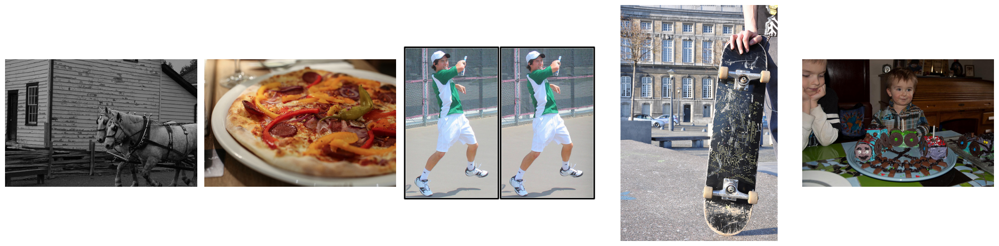

In [20]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, sample in zip(axes, samples):
    img = sample.get("image")

    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
print(samples[0].keys())
print("\nFirst sample:")
print(samples[0])

dict_keys(['id', 'image'])

First sample:
{'id': '2375429', 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x333 at 0x78A1C4368D70>}


/tmp/ipykernel_1796/1072140421.py:61: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


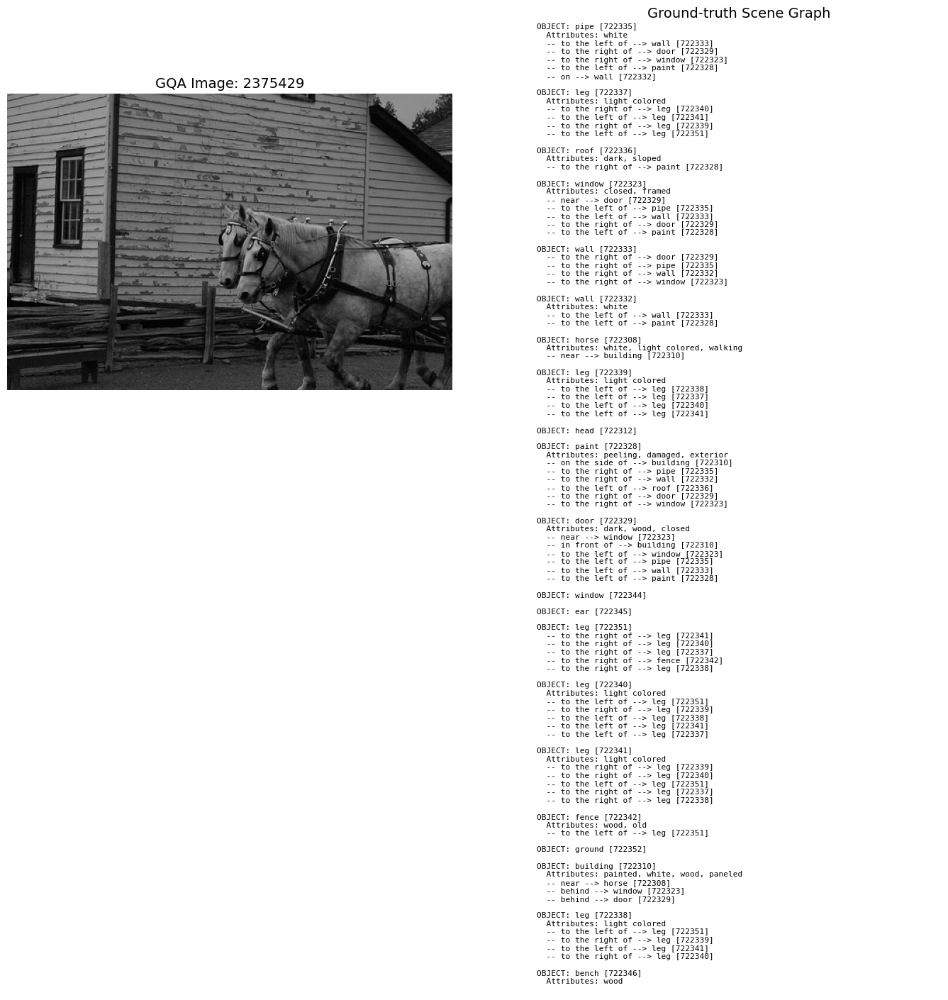

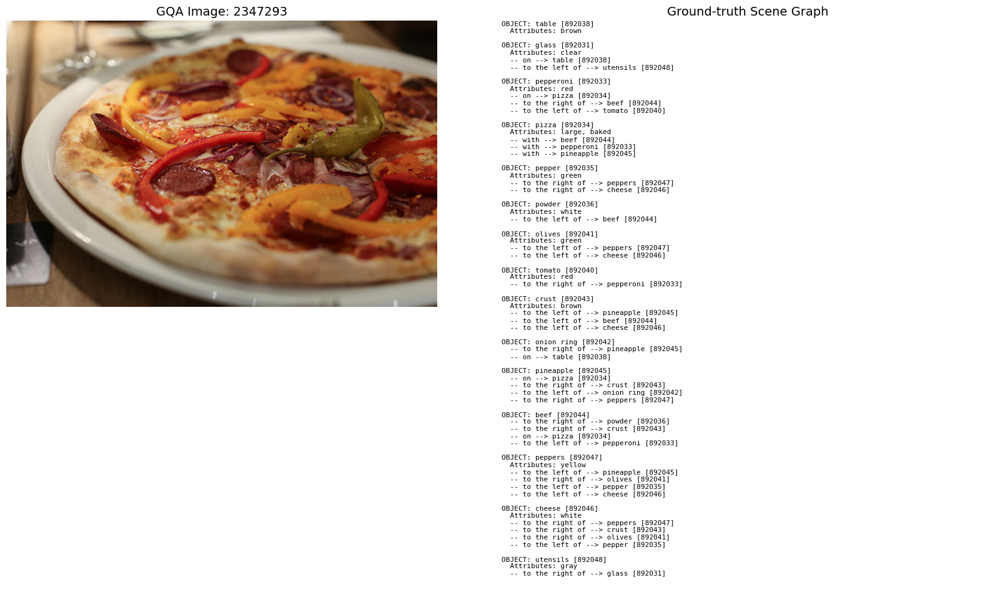

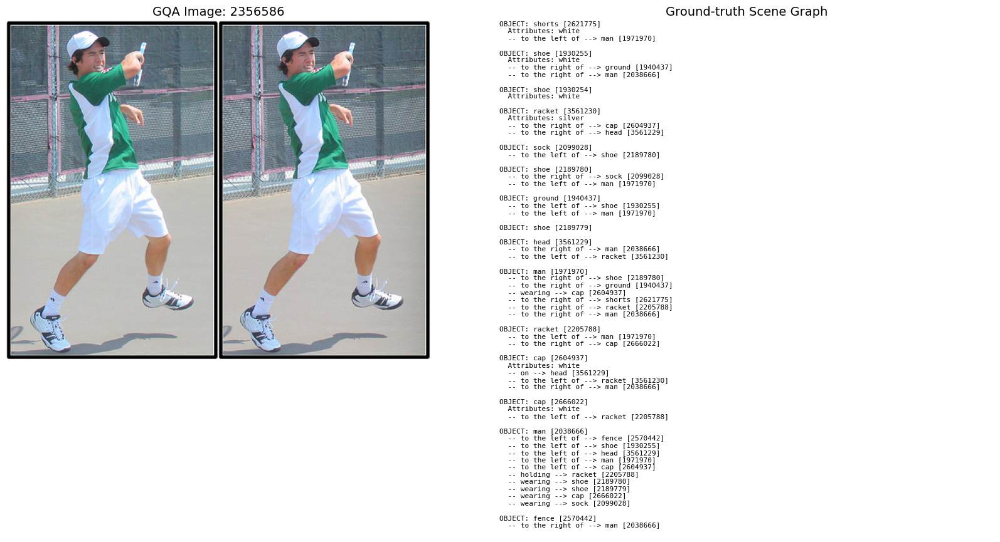

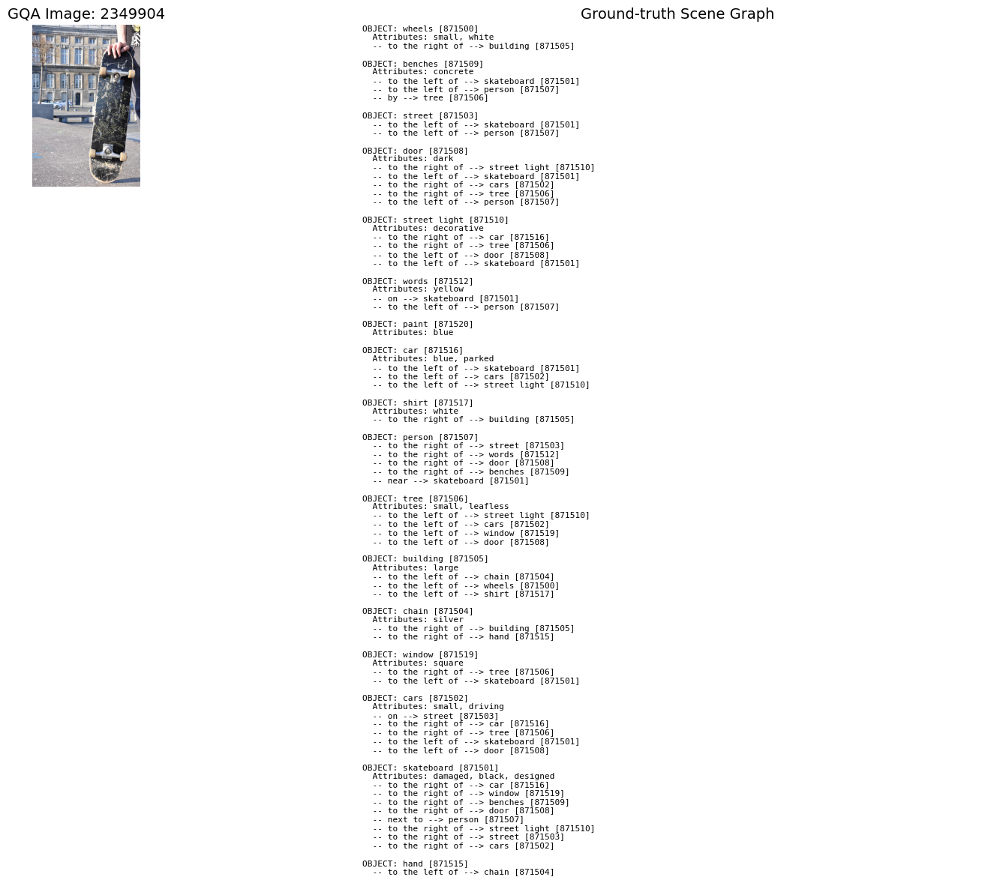

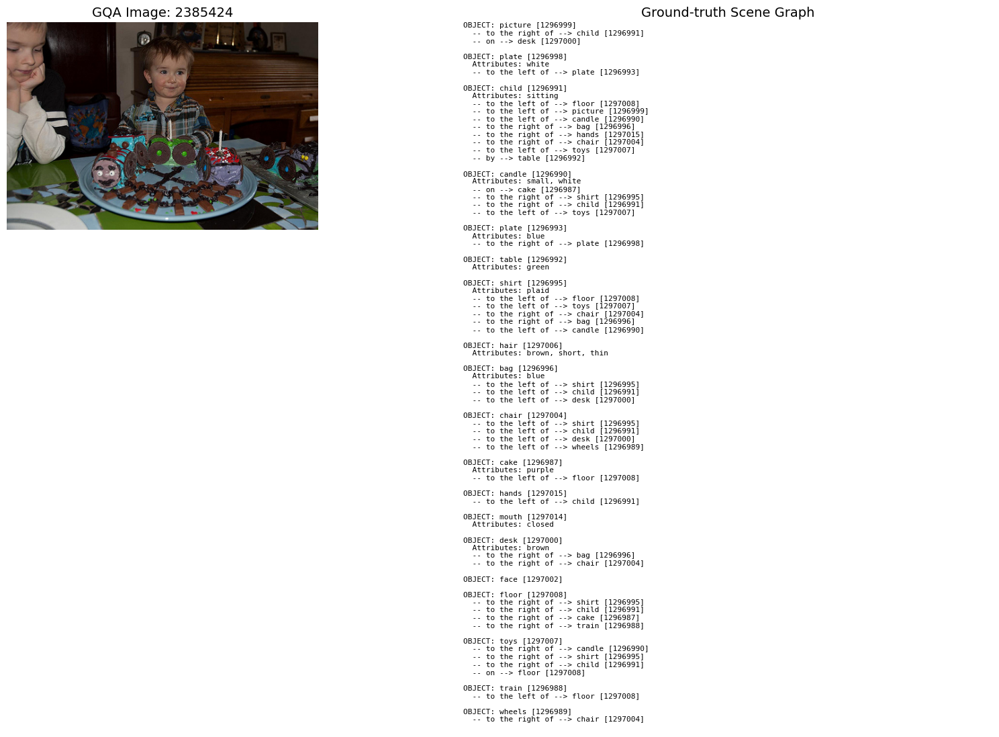

In [22]:
import matplotlib.pyplot as plt
import textwrap

def show_image_and_graph(image_id, image, train_graphs):

    image_id = str(image_id)

    if image_id not in train_graphs:
        print(f"Scene graph not found for image {image_id}")
        return

    graph = train_graphs[image_id]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(17, 8),
        gridspec_kw={"width_ratios": [1.1, 1]}
    )

    # Left: actual image
    axes[0].imshow(image)
    axes[0].set_title(f"GQA Image: {image_id}", fontsize=14)
    axes[0].axis("off")

    # Right: scene graph
    lines = []

    for obj_id, obj in graph["objects"].items():

        lines.append(f"OBJECT: {obj['name']} [{obj_id}]")

        attrs = obj.get("attributes", [])
        if attrs:
            lines.append(f"  Attributes: {', '.join(attrs)}")

        for rel in obj.get("relations", []):
            target_id = str(rel["object"])
            target_obj = graph["objects"].get(target_id, {})
            target_name = target_obj.get("name", "unknown")

            lines.append(
                f"  -- {rel['name']} --> {target_name} [{target_id}]"
            )

        lines.append("")

    graph_text = "\n".join(lines)

    axes[1].text(
        0, 1,
        graph_text,
        fontsize=8,
        verticalalignment="top",
        family="monospace",
        wrap=True
    )

    axes[1].set_title("Ground-truth Scene Graph", fontsize=14)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


# Display five matched images and graphs
for sample in samples:
    show_image_and_graph(
        sample["id"],
        sample["image"],
        train_graphs
    )

In [53]:
def convert_gqa_to_kg(image_id, scene):
    nodes = []
    edges = []

    objects = scene.get("objects", {})

    # Create object nodes
    for object_id, obj in objects.items():

        nodes.append({
            "id": str(object_id),
            "type": "object",
            "name": obj.get("name", "unknown"),
            "attributes": obj.get("attributes", []),
            "bbox": {
                "x": obj.get("x", 0),
                "y": obj.get("y", 0),
                "width": obj.get("w", 0),
                "height": obj.get("h", 0)
            }
        })

        # Create relationship edges
        for relation in obj.get("relations", []):

            target_id = str(relation.get("object"))

            if target_id in objects:
                edges.append({
                    "source": str(object_id),
                    "relation": relation.get("name", "unknown"),
                    "target": target_id
                })

    return {
        "image_id": str(image_id),
        "image_width": scene.get("width"),
        "image_height": scene.get("height"),
        "nodes": nodes,
        "edges": edges
    }

In [61]:
sample_kg = convert_gqa_to_kg(
    first_image_id,
    sample_graph
)

print("Image ID:", sample_kg["image_id"])
print("Number of object nodes:", len(sample_kg["nodes"]))
print("Number of relationship edges:", len(sample_kg["edges"]))

print("\nFirst 3 nodes:")
for node in sample_kg["nodes"][:3]:
    print(node)

print("\nFirst 5 edges:")
for edge in sample_kg["edges"][:5]:
    print(edge)

Image ID: 2386621
Number of object nodes: 16
Number of relationship edges: 31

First 3 nodes:
{'id': '681267', 'type': 'object', 'name': 'banana', 'attributes': ['small', 'yellow'], 'bbox': {'x': 248, 'y': 55, 'width': 64, 'height': 34}}
{'id': '681265', 'type': 'object', 'name': 'spots', 'attributes': [], 'bbox': {'x': 245, 'y': 92, 'width': 26, 'height': 16}}
{'id': '681264', 'type': 'object', 'name': 'bananas', 'attributes': ['small', 'yellow'], 'bbox': {'x': 268, 'y': 32, 'width': 49, 'height': 50}}

First 5 edges:
{'source': '681267', 'relation': 'to the left of', 'target': '681262'}
{'source': '681264', 'relation': 'to the left of', 'target': '681259'}
{'source': '681262', 'relation': 'to the right of', 'target': '681268'}
{'source': '681262', 'relation': 'to the right of', 'target': '681267'}
{'source': '681262', 'relation': 'to the right of', 'target': '681253'}


In [25]:
import json
import os

PROCESSED_DIR = f"{PROJECT_DIR}/data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

def save_kg_dataset(graph_data, output_path):
    count = 0

    with open(output_path, "w") as f:
        for image_id, scene in graph_data.items():
            kg = convert_gqa_to_kg(image_id, scene)
            f.write(json.dumps(kg) + "\n")
            count += 1

    print(f"Saved {count} graphs: {output_path}")

save_kg_dataset(
    train_graphs,
    f"{PROCESSED_DIR}/train_kg.jsonl"
)

save_kg_dataset(
    val_graphs,
    f"{PROCESSED_DIR}/val_kg.jsonl"
)

Saved 74942 graphs: /content/drive/MyDrive/KG_VLM_Research/data/processed/train_kg.jsonl
Saved 10696 graphs: /content/drive/MyDrive/KG_VLM_Research/data/processed/val_kg.jsonl


In [57]:
object_names = set()
relation_names = set()
attribute_names = set()

for image_id, scene in train_graphs.items():
    for obj in scene.get("objects", {}).values():

        object_names.add(obj.get("name", "unknown"))

        for attr in obj.get("attributes", []):
            attribute_names.add(attr)

        for rel in obj.get("relations", []):
            relation_names.add(rel.get("name", "unknown"))

object_vocab = {
    name: i + 1
    for i, name in enumerate(sorted(object_names))
}

relation_vocab = {
    name: i + 1
    for i, name in enumerate(sorted(relation_names))
}

attribute_vocab = {
    name: i + 1
    for i, name in enumerate(sorted(attribute_names))
}

print("Unique object categories:", len(object_vocab))
print("Unique relation types:", len(relation_vocab))
print("Unique attributes:", len(attribute_vocab))

print("\nExample object vocabulary:")
print(list(object_vocab.items())[:15])

print("\nExample relation vocabulary:")
print(list(relation_vocab.items())[:15])

Unique object categories: 1702
Unique relation types: 310
Unique attributes: 617

Example object vocabulary:
[('accessory', 1), ('action figure', 2), ('air', 3), ('air conditioner', 4), ('aircraft', 5), ('airplane', 6), ('airplanes', 7), ('airport', 8), ('alarm clock', 9), ('alcohol', 10), ('alien', 11), ('alligator', 12), ('almond', 13), ('almonds', 14), ('ambulance', 15)]

Example relation vocabulary:
[('about to hit', 1), ('above', 2), ('adjusting', 3), ('approaching', 4), ('around', 5), ('at', 6), ('attached to', 7), ('balancing on', 8), ('behind', 9), ('below', 10), ('beneath', 11), ('beside', 12), ('between', 13), ('bigger than', 14), ('biting', 15)]


In [58]:
vocab_path = f"{PROJECT_DIR}/configs/graph_vocab.json"

with open(vocab_path, "w") as f:
    json.dump({
        "objects": object_vocab,
        "relations": relation_vocab,
        "attributes": attribute_vocab
    }, f, indent=2)

print("Vocabulary saved:", vocab_path)

Vocabulary saved: /content/drive/MyDrive/KG_VLM_Research/configs/graph_vocab.json


RGCN

In [52]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import RGCNConv

class VisualGraphEncoder(nn.Module):

    def __init__(
        self,
        num_objects,
        num_attributes,
        num_relations,
        embedding_dim=256,
        num_bases=30
    ):
        super().__init__()

        self.object_embedding = nn.Embedding(
            num_objects + 1,
            embedding_dim,
            padding_idx=0
        )

        self.attribute_embedding = nn.Embedding(
            num_attributes + 1,
            embedding_dim,
            padding_idx=0
        )

        self.rgcn1 = RGCNConv(
            embedding_dim,
            embedding_dim,
            num_relations,
            num_bases=num_bases
        )

        self.rgcn2 = RGCNConv(
            embedding_dim,
            embedding_dim,
            num_relations,
            num_bases=num_bases
        )

        self.dropout = nn.Dropout(0.2)

    def forward(self, object_ids, attribute_ids, edge_index, edge_type):

        object_features = self.object_embedding(object_ids)
        attr_features = self.attribute_embedding(attribute_ids)

        mask = (attribute_ids != 0).unsqueeze(-1)

        attr_features = (
            (attr_features * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        x = object_features + attr_features

        x = self.rgcn1(x, edge_index, edge_type)
        x = F.relu(x)
        x = self.dropout(x)

        x = self.rgcn2(x, edge_index, edge_type)
        x = F.relu(x)

        graph_embedding = x.mean(dim=0)

        return x, graph_embedding

In [62]:
def kg_to_tensors(kg):

    nodes = kg["nodes"]
    edges = kg["edges"]

    object_ids = [
        object_vocab.get(node["name"], 0)
        for node in nodes
    ]

    attribute_ids = [
        [attribute_vocab.get(a, 0) for a in node["attributes"]]
        for node in nodes
    ]

    max_attrs = max(1, max(map(len, attribute_ids)))

    attribute_ids = [
        attrs + [0] * (max_attrs - len(attrs))
        for attrs in attribute_ids
    ]

    edge_index = []
    edge_type = []

    node_lookup = {
        node["id"]: i
        for i, node in enumerate(nodes)
    }

    for edge in edges:
        source = node_lookup[edge["source"]]
        target = node_lookup[edge["target"]]

        edge_index.append([source, target])
        edge_type.append(
            relation_vocab.get(edge["relation"], 0)
        )

    if edge_index:
        edge_index = torch.tensor(
            edge_index, dtype=torch.long
        ).t().contiguous()
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)

    return {
        "object_ids": torch.tensor(object_ids, dtype=torch.long),
        "attribute_ids": torch.tensor(attribute_ids, dtype=torch.long),
        "edge_index": edge_index,
        "edge_type": torch.tensor(edge_type, dtype=torch.long)
    }


graph_tensors = kg_to_tensors(sample_kg)

for name, tensor in graph_tensors.items():
    print(name, tensor.shape)

object_ids torch.Size([16])
attribute_ids torch.Size([16, 3])
edge_index torch.Size([2, 31])
edge_type torch.Size([31])


In [55]:
encoder = VisualGraphEncoder(
    num_objects=len(object_vocab),
    num_attributes=len(attribute_vocab),
    num_relations=len(relation_vocab) + 1,
    embedding_dim=EMBED_DIM
).to(DEVICE)

graph_tensors = {
    key: value.to(DEVICE)
    for key, value in graph_tensors.items()
}

node_embeddings, graph_embedding = encoder(
    graph_tensors["object_ids"],
    graph_tensors["attribute_ids"],
    graph_tensors["edge_index"],
    graph_tensors["edge_type"]
)

print("Node embeddings:", node_embeddings.shape)
print("Graph embedding:", graph_embedding.shape)
print("GPU:", DEVICE)
print("Trainable parameters:",
      sum(p.numel() for p in encoder.parameters() if p.requires_grad))

NameError: name 'object_vocab' is not defined

In [54]:
print("Object vocabulary:", len(object_vocab))
print("Attribute vocabulary:", len(attribute_vocab))
print("Relation vocabulary:", len(relation_vocab))

print("\nParameter breakdown:")

for name, parameter in encoder.named_parameters():
    print(
        f"{name:35s}",
        f"{parameter.numel():,}"
    )

NameError: name 'object_vocab' is not defined

Recreating and testing the small encoder

In [34]:
encoder = VisualGraphEncoder(
    num_objects=len(object_vocab),
    num_attributes=len(attribute_vocab),
    num_relations=len(relation_vocab) + 1,
    embedding_dim=256,
    num_bases=30
).to(DEVICE)

node_embeddings, graph_embedding = encoder(
    graph_tensors["object_ids"],
    graph_tensors["attribute_ids"],
    graph_tensors["edge_index"],
    graph_tensors["edge_type"]
)

total_params = sum(
    p.numel() for p in encoder.parameters()
    if p.requires_grad
)

print("Node embeddings:", node_embeddings.shape)
print("Graph embedding:", graph_embedding.shape)
print("Trainable parameters:", f"{total_params:,}")

Node embeddings: torch.Size([16, 256])
Graph embedding: torch.Size([256])
Trainable parameters: 4,676,580


In [35]:
from datasets import load_dataset

qa_dataset = load_dataset(
    "alexwww94/GQA",
    "train_all_instructions",
    split="train",
    streaming=True
)

qa_samples = list(qa_dataset.take(3))

for i, sample in enumerate(qa_samples):
    print(f"\nSAMPLE {i+1}")
    print(sample)


SAMPLE 1
{'id': '07333408', 'imageId': '2375429', 'question': 'What is on the white wall?', 'answer': 'pipe', 'fullAnswer': 'The pipe is on the wall.', 'isBalanced': True, 'groups': {'global': '', 'local': '14-wall_on,s'}, 'entailed': '[]', 'equivalent': "['07333408']", 'types': {'structural': 'query', 'semantic': 'rel', 'detailed': 'relS'}, 'annotations': {'question': [{'objectId': '4:6', 'value': '722332'}], 'answer': [{'objectId': '0', 'value': '722335'}], 'fullAnswer': [{'objectId': '1', 'value': '722335'}, {'objectId': '5', 'value': '722332'}]}, 'semantic': [{'operation': 'select', 'argument': 'wall (722332)', 'dependencies': []}, {'operation': 'filter color', 'argument': 'white', 'dependencies': [0]}, {'operation': 'relate', 'argument': '_,on,s (722335)', 'dependencies': [1]}, {'operation': 'query', 'argument': 'name', 'dependencies': [2]}], 'semanticStr': 'select: wall (722332)->filter color: white [0]->relate: _,on,s (722335) [1]->query: name [2]'}

SAMPLE 2
{'id': '07333409',

In [36]:
from datasets import load_dataset

qa_dataset = load_dataset(
    "alexwww94/GQA",
    "train_all_instructions",
    split="train",
    streaming=True
)

qa_records = []

for record in qa_dataset:
    if record["isBalanced"] and str(record["imageId"]) in train_graphs:
        qa_records.append(record)

    if len(qa_records) >= 2000:
        break

print("Questions collected:", len(qa_records))
print("Unique images:", len(set(r["imageId"] for r in qa_records)))

print("\nFirst connected example:")
print("Image ID:", qa_records[0]["imageId"])
print("Question:", qa_records[0]["question"])
print("Answer:", qa_records[0]["answer"])
print("Graph exists:", qa_records[0]["imageId"] in train_graphs)

Questions collected: 2000
Unique images: 1510

First connected example:
Image ID: 2375429
Question: What is on the white wall?
Answer: pipe
Graph exists: True


In [37]:
def inspect_qa_graph(record):

    image_id = str(record["imageId"])
    scene = train_graphs[image_id]

    print("=" * 65)
    print("IMAGE ID:", image_id)
    print("QUESTION:", record["question"])
    print("EXPECTED ANSWER:", record["answer"])

    print("\nOBJECTS AND ATTRIBUTES:")

    for obj_id, obj in scene["objects"].items():
        print(
            f"{obj['name']} | "
            f"Attributes: {obj.get('attributes', [])} | "
            f"ID: {obj_id}"
        )

    print("\nRELATIONSHIPS:")

    for obj_id, obj in scene["objects"].items():
        for rel in obj.get("relations", []):
            target = scene["objects"].get(
                str(rel["object"]), {}
            )
            print(
                f"{obj['name']} --{rel['name']}--> "
                f"{target.get('name', 'unknown')}"
            )


inspect_qa_graph(qa_records[0])

IMAGE ID: 2375429
QUESTION: What is on the white wall?
EXPECTED ANSWER: pipe

OBJECTS AND ATTRIBUTES:
pipe | Attributes: ['white'] | ID: 722335
leg | Attributes: ['light colored'] | ID: 722337
roof | Attributes: ['dark', 'sloped'] | ID: 722336
window | Attributes: ['closed', 'framed'] | ID: 722323
wall | Attributes: [] | ID: 722333
wall | Attributes: ['white'] | ID: 722332
horse | Attributes: ['white', 'light colored', 'walking'] | ID: 722308
leg | Attributes: ['light colored'] | ID: 722339
head | Attributes: [] | ID: 722312
paint | Attributes: ['peeling', 'damaged', 'exterior'] | ID: 722328
door | Attributes: ['dark', 'wood', 'closed'] | ID: 722329
window | Attributes: [] | ID: 722344
ear | Attributes: [] | ID: 722345
leg | Attributes: [] | ID: 722351
leg | Attributes: ['light colored'] | ID: 722340
leg | Attributes: ['light colored'] | ID: 722341
fence | Attributes: ['wood', 'old'] | ID: 722342
ground | Attributes: [] | ID: 722352
building | Attributes: ['painted', 'white', 'wood', '

In [38]:
from collections import Counter

answer_counts = Counter(
    r["answer"].lower().strip()
    for r in qa_records
)

print("Unique answers:", len(answer_counts))
print("\nMost frequent answers:")
for answer, count in answer_counts.most_common(20):
    print(f"{answer}: {count}")

Unique answers: 368

Most frequent answers:
no: 381
yes: 336
left: 109
right: 88
man: 35
boy: 23
black: 22
bottom: 22
brown: 21
top: 21
white: 19
car: 17
blue: 16
table: 16
girl: 15
red: 14
gray: 14
dog: 14
chair: 14
cat: 14


In [39]:
from collections import Counter

answer_counts = Counter(
    r["answer"].lower().strip()
    for r in qa_records
)

MIN_ANSWER_COUNT = 3

answer_vocab = {
    answer: idx
    for idx, (answer, count) in enumerate(
        (item for item in sorted(answer_counts.items())
         if item[1] >= MIN_ANSWER_COUNT)
    )
}

answer_vocab["other"] = len(answer_vocab)

print("Answer classes:", len(answer_vocab))
print("Other class ID:", answer_vocab["other"])

Answer classes: 116
Other class ID: 115


Split by image

In [40]:
import random

random.seed(42)

image_ids = list(set(
    str(r["imageId"]) for r in qa_records
))

random.shuffle(image_ids)

split_index = int(0.8 * len(image_ids))

train_image_ids = set(image_ids[:split_index])
val_image_ids = set(image_ids[split_index:])

train_qa = [
    r for r in qa_records
    if str(r["imageId"]) in train_image_ids
]

val_qa = [
    r for r in qa_records
    if str(r["imageId"]) in val_image_ids
]

print("Training questions:", len(train_qa))
print("Validation questions:", len(val_qa))
print("Training images:", len(train_image_ids))
print("Validation images:", len(val_image_ids))
print("Image overlap:", len(train_image_ids & val_image_ids))

Training questions: 1601
Validation questions: 399
Training images: 1208
Validation images: 302
Image overlap: 0


We'll use DistilBERT to turn each question into a 768-dimensional representation. Freeze it initially to keep the experiment manageable.

In [47]:
!pip -q install transformers

In [48]:
from transformers import AutoTokenizer, AutoModel

QUESTION_MODEL = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(QUESTION_MODEL)

question_encoder = AutoModel.from_pretrained(
    QUESTION_MODEL
).to(DEVICE)

question_encoder.eval()

for param in question_encoder.parameters():
    param.requires_grad = False

print("Question encoder ready.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NameError: name 'DEVICE' is not defined

Check the answer mapping

In [43]:
def encode_answer(answer):
    answer = answer.lower().strip()
    return answer_vocab.get(answer, answer_vocab["other"])

print("Sample training examples:")

for r in train_qa[:5]:
    print({
        "image": r["imageId"],
        "question": r["question"],
        "answer": r["answer"],
        "answer_id": encode_answer(r["answer"])
    })

Sample training examples:
{'image': '2375429', 'question': 'What is on the white wall?', 'answer': 'pipe', 'answer_id': 115}
{'image': '2375429', 'question': 'Is that pipe red?', 'answer': 'no', 'answer_id': 66}
{'image': '2414494', 'question': 'Are the toothbrushes on the right?', 'answer': 'yes', 'answer_id': 113}
{'image': '2368974', 'question': 'Which side is the man on?', 'answer': 'right', 'answer_id': 81}
{'image': '2404431', 'question': 'Which side of the photo is the pizza on?', 'answer': 'right', 'answer_id': 81}


In [44]:
from tqdm.auto import tqdm

def encode_questions(records, batch_size=32):
    all_embeddings = []

    for start in tqdm(range(0, len(records), batch_size)):
        batch = records[start:start + batch_size]
        texts = [r["question"] for r in batch]

        inputs = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():
            outputs = question_encoder(**inputs)

            mask = inputs["attention_mask"].unsqueeze(-1)
            embedding = (
                outputs.last_hidden_state * mask
            ).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

        all_embeddings.append(embedding.cpu())

    return torch.cat(all_embeddings, dim=0)


train_question_embeddings = encode_questions(train_qa)
val_question_embeddings = encode_questions(val_qa)

print("Train embeddings:", train_question_embeddings.shape)
print("Validation embeddings:", val_question_embeddings.shape)

  0%|          | 0/51 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

Train embeddings: torch.Size([1601, 768])
Validation embeddings: torch.Size([399, 768])


In [45]:
from tqdm.auto import tqdm

def encode_questions(records, batch_size=32):
    all_embeddings = []

    for start in tqdm(range(0, len(records), batch_size)):
        batch = records[start:start + batch_size]
        texts = [r["question"] for r in batch]

        inputs = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():
            outputs = question_encoder(**inputs)

            mask = inputs["attention_mask"].unsqueeze(-1)
            embedding = (
                outputs.last_hidden_state * mask
            ).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

        all_embeddings.append(embedding.cpu())

    return torch.cat(all_embeddings, dim=0)


train_question_embeddings = encode_questions(train_qa)
val_question_embeddings = encode_questions(val_qa)

print("Train embeddings:", train_question_embeddings.shape)
print("Validation embeddings:", val_question_embeddings.shape)

  0%|          | 0/51 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

Train embeddings: torch.Size([1601, 768])
Validation embeddings: torch.Size([399, 768])


In [65]:
graph_cache = {}

def get_graph_tensors(image_id):
    image_id = str(image_id)

    if image_id not in graph_cache:

        if image_id in train_graphs:
            scene = train_graphs[image_id]
        elif image_id in val_graphs:
            scene = val_graphs[image_id]
        else:
            raise KeyError(f"Graph not found for image {image_id}")

        kg = convert_gqa_to_kg(image_id, scene)
        tensors = kg_to_tensors(kg)

        graph_cache[image_id] = {
            key: value.to(DEVICE)
            for key, value in tensors.items()
        }

    return graph_cache[image_id]


print("Graph cache function ready.")

Graph cache function ready.


In [63]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class GraphQuestionAttention(nn.Module):

    def __init__(self, graph_dim=256, question_dim=768):
        super().__init__()

        self.question_projection = nn.Linear(question_dim, graph_dim)
        self.query_projection = nn.Linear(graph_dim, graph_dim)
        self.key_projection = nn.Linear(graph_dim, graph_dim)
        self.value_projection = nn.Linear(graph_dim, graph_dim)

        self.scale = graph_dim ** 0.5

    def forward(self, node_embeddings, question_embedding):

        q = self.query_projection(
            self.question_projection(question_embedding)
        )

        k = self.key_projection(node_embeddings)
        v = self.value_projection(node_embeddings)

        scores = torch.matmul(k, q) / self.scale
        weights = torch.softmax(scores, dim=0)

        attended_graph = torch.sum(
            weights.unsqueeze(-1) * v, dim=0
        )

        return attended_graph, weights


class GraphQuestionAnswering(nn.Module):

    def __init__(self, graph_encoder, num_answers,
                 graph_dim=256, question_dim=768):

        super().__init__()

        self.graph_encoder = graph_encoder

        self.attention = GraphQuestionAttention(
            graph_dim, question_dim
        )

        self.classifier = nn.Sequential(
            nn.Linear(graph_dim + question_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_answers)
        )

    def forward(self, graph_tensors, question_embedding):

        node_embeddings, _ = self.graph_encoder(
            graph_tensors["object_ids"],
            graph_tensors["attribute_ids"],
            graph_tensors["edge_index"],
            graph_tensors["edge_type"]
        )

        attended_graph, attention_weights = self.attention(
            node_embeddings, question_embedding
        )

        combined = torch.cat(
            [attended_graph, question_embedding], dim=-1
        )

        logits = self.classifier(combined)

        return logits, attention_weights

In [48]:
num_answers = len(answer_vocab)

model = GraphQuestionAnswering(
    graph_encoder=encoder,
    num_answers=num_answers
).to(DEVICE)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{trainable_params:,}")

Trainable parameters: 5,655,128


one single forward pass to test

In [64]:
sample = train_qa[0]

sample_index = 0
question_embedding = train_question_embeddings[
    sample_index
].to(DEVICE)

graph = get_graph_tensors(sample["imageId"])

model.eval()

with torch.no_grad():
    logits, attention = model(graph, question_embedding)

print("Question:", sample["question"])
print("Expected answer:", sample["answer"])
print("Logits shape:", logits.shape)
print("Attention shape:", attention.shape)
print("Attention sum:", attention.sum().item())

NameError: name 'train_qa' is not defined

In [52]:
required_objects = [
    "graph_encoder",
    "model",
    "train_qa",
    "val_qa",
    "train_question_embeddings",
    "val_question_embeddings",
    "answer_vocab",
    "get_graph_tensors",
    "DEVICE"
]

for name in required_objects:
    print(f"{name}: {'Available' if name in globals() else 'MISSING'}")

graph_encoder: MISSING
model: Available
train_qa: Available
val_qa: Available
train_question_embeddings: Available
val_question_embeddings: Available
answer_vocab: Available
get_graph_tensors: Available
DEVICE: Available


In [53]:
print("Model architecture:")
print(model)

print("\nGraph encoder available inside model:",
      hasattr(model, "graph_encoder"))

if hasattr(model, "graph_encoder"):
    graph_encoder = model.graph_encoder
    print("\nGraph encoder recovered successfully!")
    print(graph_encoder)
else:
    print("\nGraph encoder is not attached to model.")

Model architecture:
GraphQuestionAnswering(
  (graph_encoder): VisualGraphEncoder(
    (object_embedding): Embedding(1703, 256, padding_idx=0)
    (attribute_embedding): Embedding(618, 256, padding_idx=0)
    (rgcn1): RGCNConv(256, 256, num_relations=311)
    (rgcn2): RGCNConv(256, 256, num_relations=311)
    (dropout): Dropout(p=0.2, inplace=False)
  )
  (attention): GraphQuestionAttention(
    (question_projection): Linear(in_features=768, out_features=256, bias=True)
    (query_projection): Linear(in_features=256, out_features=256, bias=True)
    (key_projection): Linear(in_features=256, out_features=256, bias=True)
    (value_projection): Linear(in_features=256, out_features=256, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=1024, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=116, bias=True)
  )
)

Graph encoder available inside model: True

Graph encoder recovered successfu

In [54]:
import torch
from collections import Counter

graph_encoder = model.graph_encoder

print("Training questions:", len(train_qa))
print("Validation questions:", len(val_qa))

print("\nTrainable parameters:",
      f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

print("\nModel device:", next(model.parameters()).device)

# Check answer distribution
train_answers = [r["answer"] for r in train_qa]
answer_counts = Counter(train_answers)

majority_answer, majority_count = answer_counts.most_common(1)[0]

print("\nMost frequent answer:", majority_answer)
print("Majority-answer baseline:",
      f"{100 * majority_count / len(train_qa):.2f}%")

print("\nTop 10 answers:")
for answer, count in answer_counts.most_common(10):
    print(f"{answer}: {count}")

Training questions: 1601
Validation questions: 399

Trainable parameters: 5,655,128

Model device: cuda:0

Most frequent answer: no
Majority-answer baseline: 19.11%

Top 10 answers:
no: 306
yes: 270
left: 90
right: 73
man: 24
boy: 20
black: 16
white: 16
brown: 16
top: 15


In [55]:
import torch
from torch.utils.data import Dataset, DataLoader

class GQADataset(Dataset):
    def __init__(self, records, question_embeddings, answer_vocab):
        self.records = records
        self.question_embeddings = question_embeddings
        self.answer_vocab = answer_vocab

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        return {
            "image_id": str(record["imageId"]),
            "question_embedding": self.question_embeddings[idx],
            "answer_id": self.answer_vocab.get(
                record["answer"], self.answer_vocab.get("other", 0)
            )
        }

train_dataset = GQADataset(
    train_qa, train_question_embeddings, answer_vocab
)

val_dataset = GQADataset(
    val_qa, val_question_embeddings, answer_vocab
)

train_loader = DataLoader(
    train_dataset, batch_size=1, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

sample = next(iter(train_loader))
print("\nSample image:", sample["image_id"][0])
print("Question embedding:", sample["question_embedding"].shape)
print("Answer ID:", sample["answer_id"].item())

Training batches: 1601
Validation batches: 399

Sample image: 2370172
Question embedding: torch.Size([1, 768])
Answer ID: 113


In [61]:
import torch.nn as nn
import torch.optim as optim

# Ensure model is on GPU
model = model.to(DEVICE)

# Optimiser
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Classification loss
criterion = nn.CrossEntropyLoss()

# Training configuration
EPOCHS = 5
MAX_GRAD_NORM = 1.0

print("Training configuration ready")
print("Epochs:", EPOCHS)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Optimiser: AdamW")
print("Loss: CrossEntropyLoss")
print("Device:", DEVICE)

Training configuration ready
Epochs: 5
Learning rate: 0.0001
Optimiser: AdamW
Loss: CrossEntropyLoss
Device: cuda


In [62]:
import time
import copy
from tqdm.auto import tqdm

history = []
best_val_accuracy = 0.0
best_model_state = None

def run_epoch(loader, training=True):
    model.train() if training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(loader, leave=False)

    for batch in progress:
        image_id = batch["image_id"][0]
        question_embedding = batch["question_embedding"].squeeze(0).to(DEVICE)
        answer_id = batch["answer_id"].to(DEVICE)

        graph_tensors = get_graph_tensors(image_id)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits, attention_weights = model(
                graph_tensors,
                question_embedding
            )

            loss = criterion(logits.unsqueeze(0), answer_id)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), MAX_GRAD_NORM
                )

                optimizer.step()

        total_loss += loss.item()
        predictions = logits.argmax(dim=-1)
        correct += (predictions == answer_id).sum().item()
        total += answer_id.size(0)

        progress.set_postfix(loss=f"{loss.item():.3f}")

    return total_loss / total, correct / total


for epoch in range(EPOCHS):
    start_time = time.time()

    train_loss, train_accuracy = run_epoch(
        train_loader, training=True
    )

    val_loss, val_accuracy = run_epoch(
        val_loader, training=False
    )

    epoch_time = time.time() - start_time

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "time_seconds": epoch_time
    })

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Train accuracy: {train_accuracy:.2%}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_accuracy:.2%}")
    print(f"Time: {epoch_time:.1f} seconds")

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
    {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_accuracy,
        "history": history
    },
    f"{PROJECT_DIR}/checkpoints/graph_qa_epoch_{epoch+1}.pt"
)

        print("Best model checkpoint saved.")

print("\nTraining completed.")
print("Best validation accuracy:", f"{best_val_accuracy:.2%}")

  0%|          | 0/1601 [00:00<?, ?it/s]

  0%|          | 0/399 [00:00<?, ?it/s]


Epoch 1/5
Train loss: 3.0064
Train accuracy: 31.86%
Validation loss: 3.7433
Validation accuracy: 32.58%
Time: 722.3 seconds
Best model checkpoint saved.


  0%|          | 0/1601 [00:00<?, ?it/s]

  0%|          | 0/399 [00:00<?, ?it/s]


Epoch 2/5
Train loss: 2.6055
Train accuracy: 39.54%
Validation loss: 4.2059
Validation accuracy: 32.08%
Time: 724.4 seconds


... (5 outputs left out)


Epoch 4/5
Train loss: 1.9550
Train accuracy: 54.15%
Validation loss: 3.9886
Validation accuracy: 34.34%
Time: 724.1 seconds
Best model checkpoint saved.


  0%|          | 0/1601 [00:00<?, ?it/s]

  0%|          | 0/399 [00:00<?, ?it/s]


Epoch 5/5
Train loss: 1.6075
Train accuracy: 62.34%
Validation loss: 5.1201
Validation accuracy: 33.33%
Time: 725.1 seconds

Training completed.
Best validation accuracy: 34.34%


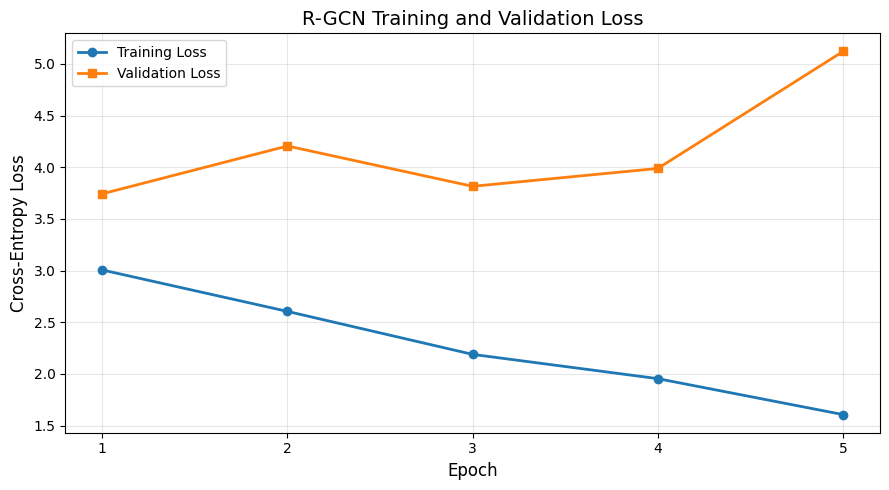

In [63]:
import matplotlib.pyplot as plt

epochs = [item["epoch"] for item in history]
train_losses = [item["train_loss"] for item in history]
val_losses = [item["val_loss"] for item in history]

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs, val_losses,
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.title("R-GCN Training and Validation Loss", fontsize=14)

plt.xticks(epochs)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{PROJECT_DIR}/results/rgcn_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
import pandas as pd

results = pd.DataFrame(history)

display(
    results[
        [
            "epoch",
            "train_loss",
            "train_accuracy",
            "val_loss",
            "val_accuracy",
            "time_seconds"
        ]
    ].round(4)
)

best_epoch = results["val_accuracy"].idxmax()

print("\nBest epoch:", int(results.loc[best_epoch, "epoch"]))
print("Best validation accuracy:",
      f"{results.loc[best_epoch, 'val_accuracy']:.2%}")
print("Best validation loss:",
      f"{results['val_loss'].min():.4f}")

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,time_seconds
0,1,3.0064,0.3186,3.7433,0.3258,722.2584
1,2,2.6055,0.3954,4.2059,0.3208,724.3530
2,3,2.1898,0.4391,3.8156,0.3383,720.9328
3,4,1.9550,0.5415,3.9886,0.3434,724.1154
4,5,1.6075,0.6234,5.1201,0.3333,725.1132



Best epoch: 4
Best validation accuracy: 34.34%
Best validation loss: 3.7433


In [67]:
import os

checkpoint_dir = f"{PROJECT_DIR}/checkpoints"

print("Project directory exists:", os.path.exists(PROJECT_DIR))
print("Checkpoint directory exists:", os.path.exists(checkpoint_dir))

if os.path.exists(checkpoint_dir):
    print("\nCheckpoint files:")
    print(os.listdir(checkpoint_dir))

print("\nBest model state in RAM:",
      best_model_state is not None)

Project directory exists: True
Checkpoint directory exists: True

Checkpoint files:
['graph_qa_epoch_1.pt', 'graph_qa_epoch_3.pt', 'graph_qa_epoch_4.pt']

Best model state in RAM: True


In [68]:
# Restore best validation model from RAM
model.load_state_dict(best_model_state)
model.eval()

print("Best model restored successfully!")
print("Selected epoch: 4")
print("Validation accuracy: 34.34%")

Best model restored successfully!
Selected epoch: 4
Validation accuracy: 34.34%


In [69]:
best_path = (
    f"{PROJECT_DIR}/checkpoints/best_graph_qa_model.pt"
)

torch.save(model.state_dict(), best_path)

print("Saved:", best_path)

Saved: /content/drive/MyDrive/KG_VLM_Research/checkpoints/best_graph_qa_model.pt


In [70]:
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch in val_loader:
        image_id = batch["image_id"][0]
        question_embedding = batch["question_embedding"].squeeze(0).to(DEVICE)
        answer_id = batch["answer_id"].item()

        graph_tensors = get_graph_tensors(image_id)

        logits, _ = model(graph_tensors, question_embedding)
        prediction = logits.argmax(dim=-1).item()

        y_true.append(answer_id)
        y_pred.append(prediction)

# Reverse answer vocabulary
id_to_answer = {v: k for k, v in answer_vocab.items()}

print("Validation accuracy:", f"{accuracy_score(y_true, y_pred):.2%}")
print("Macro F1:", f"{f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print("Weighted F1:", f"{f1_score(y_true, y_pred, average='weighted', zero_division=0):.4f}")

print("\nPer-answer performance:")
print(classification_report(
    y_true,
    y_pred,
    labels=sorted(set(y_true)),
    target_names=[
        id_to_answer.get(i, str(i))
        for i in sorted(set(y_true))
    ],
    zero_division=0
))

Validation accuracy: 34.34%
Macro F1: 0.0436
Weighted F1: 0.2500

Per-answer performance:
               precision    recall  f1-score   support

          bag       0.00      0.00      0.00         1
       banana       0.00      0.00      0.00         1
        beans       0.00      0.00      0.00         2
        black       0.10      0.17      0.12         6
        blond       0.00      0.00      0.00         1
         blue       0.00      0.00      0.00         4
       bottom       0.00      0.00      0.00         8
          boy       0.25      0.67      0.36         3
        bread       0.00      0.00      0.00         1
        brown       1.00      0.60      0.75         5
          bus       0.00      0.00      0.00         1
          car       0.00      0.00      0.00         3
          cat       0.00      0.00      0.00         1
        chair       0.00      0.00      0.00         2
        child       0.00      0.00      0.00         2
         coat       0.00     

In [71]:
from collections import Counter

predicted_answers = [
    id_to_answer.get(p, "unknown")
    for p in y_pred
]

actual_answers = [
    id_to_answer.get(y, "unknown")
    for y in y_true
]

print("TOP 15 PREDICTED ANSWERS")
for answer, count in Counter(predicted_answers).most_common(15):
    print(f"{answer:15s} {count:4d} ({count/len(y_pred):.1%})")

print("\nTOP 15 ACTUAL ANSWERS")
for answer, count in Counter(actual_answers).most_common(15):
    print(f"{answer:15s} {count:4d} ({count/len(y_true):.1%})")

TOP 15 PREDICTED ANSWERS
other            139 (34.8%)
no               119 (29.8%)
left              53 (13.3%)
right             23 (5.8%)
man               21 (5.3%)
yes               18 (4.5%)
black             10 (2.5%)
boy                8 (2.0%)
brown              3 (0.8%)
cat                2 (0.5%)
cars               1 (0.3%)
car                1 (0.3%)
skateboarder       1 (0.3%)

TOP 15 ACTUAL ANSWERS
no                75 (18.8%)
yes               66 (16.5%)
other             53 (13.3%)
left              19 (4.8%)
right             15 (3.8%)
man               11 (2.8%)
girl               8 (2.0%)
bottom             8 (2.0%)
black              6 (1.5%)
table              6 (1.5%)
top                6 (1.5%)
brown              5 (1.3%)
horse              5 (1.3%)
blue               4 (1.0%)
squash             4 (1.0%)


In [72]:
from collections import Counter

train_answer_counts = Counter(
    record["answer"] for record in train_qa
)

print("Answer vocabulary size:", len(answer_vocab))
print("Other class ID:", answer_vocab.get("other"))

print("\nMost frequent training answers:")
for answer, count in train_answer_counts.most_common(20):
    print(f"{answer:20s} {count:4d}")

print("\nRare training answers (1-3 examples):")
rare = {
    answer: count
    for answer, count in train_answer_counts.items()
    if count <= 3
}

print("Number of rare answers:", len(rare))
print("Examples:", list(rare.items())[:20])

Answer vocabulary size: 116
Other class ID: 115

Most frequent training answers:
no                    306
yes                   270
left                   90
right                  73
man                    24
boy                    20
black                  16
white                  16
brown                  16
top                    15
car                    14
bottom                 14
cat                    13
truck                  12
gray                   12
blue                   12
chair                  12
red                    11
dog                    11
woman                  10

Rare training answers (1-3 examples):
Number of rare answers: 265
Examples: [('pipe', 1), ('lady', 1), ('herd', 1), ('end table', 1), ('carrots', 3), ('blond', 2), ('snow', 3), ('seat', 3), ('monitor', 2), ('glasses', 2), ('vase', 1), ('balcony', 1), ('wood', 3), ('mannequin', 1), ('window', 2), ('dark', 2), ('helmet', 2), ('low', 1), ('chairs', 1), ('bushes', 2)]


Improving accuracy - Experiment 2

Load scene graph

In [12]:
import json
import os

TRAIN_GRAPH_PATH = (
    f"{DATA_DIR}/train_sceneGraphs.json"
)

VAL_GRAPH_PATH = (
    f"{DATA_DIR}/val_sceneGraphs.json"
)

with open(TRAIN_GRAPH_PATH, "r") as f:
    train_graphs = json.load(f)

with open(VAL_GRAPH_PATH, "r") as f:
    val_graphs = json.load(f)

print("Training images:", len(train_graphs))
print("Validation images:", len(val_graphs))

print("\nSample training image ID:")
print(next(iter(train_graphs)))

Training images: 74942
Validation images: 10696

Sample training image ID:
2386621


Load GQA questions

In [13]:
from datasets import load_dataset
from tqdm.auto import tqdm

qa_dataset = load_dataset(
    "alexwww94/GQA",
    "train_all_instructions",
    split="train",
    streaming=True
)

qa_records = []

for record in tqdm(qa_dataset):

    if not record["isBalanced"]:
        continue

    image_id = str(record["imageId"])

    if image_id not in train_graphs:
        continue

    qa_records.append(record)

    if len(qa_records) >= 2000:
        break

print("Questions collected:", len(qa_records))
print(
    "Unique images:",
    len(set(str(r["imageId"]) for r in qa_records))
)

0it [00:00, ?it/s]

Questions collected: 2000
Unique images: 1510


In [14]:
print("Record fields:", qa_records[0].keys())
print("\nSample record:")
print(qa_records[0])

Record fields: dict_keys(['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed', 'equivalent', 'types', 'annotations', 'semantic', 'semanticStr'])

Sample record:
{'id': '07333408', 'imageId': '2375429', 'question': 'What is on the white wall?', 'answer': 'pipe', 'fullAnswer': 'The pipe is on the wall.', 'isBalanced': True, 'groups': {'global': '', 'local': '14-wall_on,s'}, 'entailed': '[]', 'equivalent': "['07333408']", 'types': {'structural': 'query', 'semantic': 'rel', 'detailed': 'relS'}, 'annotations': {'question': [{'objectId': '4:6', 'value': '722332'}], 'answer': [{'objectId': '0', 'value': '722335'}], 'fullAnswer': [{'objectId': '1', 'value': '722335'}, {'objectId': '5', 'value': '722332'}]}, 'semantic': [{'operation': 'select', 'argument': 'wall (722332)', 'dependencies': []}, {'operation': 'filter color', 'argument': 'white', 'dependencies': [0]}, {'operation': 'relate', 'argument': '_,on,s (722335)', 'dependencies': [1]}, {'operation': 'que

In [15]:
from collections import Counter

answer_counts = Counter(record["answer"].strip().lower() for record in qa_records)

print("Total questions:", len(qa_records))
print("Unique answer classes:", len(answer_counts))
print("Most common answers:")
for answer, count in answer_counts.most_common(20):
    print(f"{answer!r}: {count} ({count / len(qa_records):.1%})")

print("\nQuestions in classes with only 1 example:",
      sum(count for count in answer_counts.values() if count == 1))
print("Classes with only 1 example:",
      sum(count == 1 for count in answer_counts.values()))

Total questions: 2000
Unique answer classes: 368
Most common answers:
'no': 381 (19.1%)
'yes': 336 (16.8%)
'left': 109 (5.5%)
'right': 88 (4.4%)
'man': 35 (1.8%)
'boy': 23 (1.1%)
'black': 22 (1.1%)
'bottom': 22 (1.1%)
'brown': 21 (1.1%)
'top': 21 (1.1%)
'white': 19 (0.9%)
'car': 17 (0.9%)
'blue': 16 (0.8%)
'table': 16 (0.8%)
'girl': 15 (0.8%)
'red': 14 (0.7%)
'gray': 14 (0.7%)
'dog': 14 (0.7%)
'chair': 14 (0.7%)
'cat': 14 (0.7%)

Questions in classes with only 1 example: 170
Classes with only 1 example: 170


Huge class imbalance: This confirms the sample is strongly imbalanced: “no” and “yes” make up about 35.9% of the questions, while 170 of 368 answer classes appear only once. A random train/validation split could leave many rare answers absent from training or validation.

In [17]:
missing_graphs = [
    str(record["imageId"])
    for record in qa_records
    if str(record["imageId"]) not in train_graphs
]

print("Questions:", len(qa_records))
print("Questions without a matching training graph:", len(missing_graphs))

Questions: 2000
Questions without a matching training graph: 0


In [18]:
sample_image_id = str(qa_records[0]["imageId"])
sample_graph = train_graphs[sample_image_id]

print("Image ID:", sample_image_id)
print("Graph type:", type(sample_graph))
print("Top-level keys:", sample_graph.keys() if isinstance(sample_graph, dict) else "not a dict")
print("\nSample graph:")
print(sample_graph)

Image ID: 2375429
Graph type: <class 'dict'>
Top-level keys: dict_keys(['width', 'objects', 'height'])

Sample graph:
{'width': 500, 'objects': {'722335': {'name': 'pipe', 'h': 167, 'relations': [{'object': '722333', 'name': 'to the left of'}, {'object': '722329', 'name': 'to the right of'}, {'object': '722323', 'name': 'to the right of'}, {'object': '722328', 'name': 'to the left of'}, {'object': '722332', 'name': 'on'}], 'w': 17, 'attributes': ['white'], 'y': 1, 'x': 104}, '722337': {'name': 'leg', 'h': 82, 'relations': [{'object': '722340', 'name': 'to the right of'}, {'object': '722341', 'name': 'to the left of'}, {'object': '722339', 'name': 'to the right of'}, {'object': '722351', 'name': 'to the left of'}], 'w': 58, 'attributes': ['light colored'], 'y': 250, 'x': 352}, '722336': {'name': 'roof', 'h': 88, 'relations': [{'object': '722328', 'name': 'to the right of'}], 'w': 95, 'attributes': ['dark', 'sloped'], 'y': 11, 'x': 405}, '722323': {'name': 'window', 'h': 115, 'relations'

In [19]:
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter

# Keep each image entirely in one split
groups = [str(record["imageId"]) for record in qa_records]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(qa_records, groups=groups)
)

train_records = [qa_records[i] for i in train_idx]
val_records = [qa_records[i] for i in val_idx]

train_images = {str(r["imageId"]) for r in train_records}
val_images = {str(r["imageId"]) for r in val_records}

print("Train questions:", len(train_records))
print("Validation questions:", len(val_records))
print("Train images:", len(train_images))
print("Validation images:", len(val_images))
print("Image overlap:", len(train_images & val_images))

print("\nTrain top answers:", Counter(
    r["answer"].strip().lower() for r in train_records
).most_common(10))

print("\nValidation top answers:", Counter(
    r["answer"].strip().lower() for r in val_records
).most_common(10))

Train questions: 1587
Validation questions: 413
Train images: 1208
Validation images: 302
Image overlap: 0

Train top answers: [('no', 304), ('yes', 267), ('left', 87), ('right', 67), ('man', 26), ('brown', 20), ('boy', 20), ('black', 18), ('top', 17), ('blue', 16)]

Validation top answers: [('no', 77), ('yes', 69), ('left', 22), ('right', 21), ('man', 9), ('skateboarder', 7), ('bottom', 6), ('white', 4), ('color', 4), ('street sign', 4)]


In [20]:
from collections import Counter

train_answers = Counter(
    r["answer"].strip().lower() for r in train_records
)
val_answers = Counter(
    r["answer"].strip().lower() for r in val_records
)

unseen_val_answers = {
    answer: count
    for answer, count in val_answers.items()
    if answer not in train_answers
}

print("Answer classes in train:", len(train_answers))
print("Answer classes in validation:", len(val_answers))
print("Validation classes unseen in train:", len(unseen_val_answers))
print("Validation questions with unseen answers:",
      sum(unseen_val_answers.values()))
print("Unseen validation answers:", unseen_val_answers)

Answer classes in train: 317
Answer classes in validation: 134
Validation classes unseen in train: 51
Validation questions with unseen answers: 73
Unseen validation answers: {'end table': 1, 'checkered': 1, 'low': 1, 'basket': 2, 'light brown': 1, 'street sign': 4, 'squash': 4, 'lying': 2, 'american flag': 2, 'taxi': 1, 'silver': 2, 'grapes': 1, 'material': 1, 'hamburger': 2, 'peas': 3, 'horses': 2, 'catcher': 2, 'steak': 3, 'outfit': 1, 'skinny': 1, 'symbol': 1, 'potato': 2, 'tofu': 2, 'broth': 1, 'parking meter': 2, 'curtains': 1, 'wall': 1, 'old': 1, 'cap': 1, 'logo': 1, 'garage': 1, 'lemon': 1, 'grilled': 1, 'onions': 1, 'microphone': 1, 'cactus': 1, 'toddler': 1, 'skate park': 1, 'store': 1, 'meat': 1, 'trees': 1, 'cream cheese': 1, 'antelope': 1, 'berries': 2, 'sidewalk': 1, 'lamb': 2, 'nightstand': 1, 'children': 1, 'tent': 1, 'stainless steel': 1, 'cabinet': 1}


In [21]:
from collections import Counter

TOP_K = 50

train_answer_counts = Counter(
    r["answer"].strip().lower() for r in train_records
)

answer_vocab = {
    answer
    for answer, _ in train_answer_counts.most_common(TOP_K)
}
answer_vocab.add("<other>")

def map_answer(answer):
    answer = answer.strip().lower()
    return answer if answer in answer_vocab else "<other>"

train_records_mapped = [
    {**r, "label": map_answer(r["answer"])}
    for r in train_records
]

val_records_mapped = [
    {**r, "label": map_answer(r["answer"])}
    for r in val_records
]

print("Output classes:", len(answer_vocab))
print("Train examples mapped to <other>:",
      sum(r["label"] == "<other>" for r in train_records_mapped))
print("Validation examples mapped to <other>:",
      sum(r["label"] == "<other>" for r in val_records_mapped))
print("Train label counts:", Counter(r["label"] for r in train_records_mapped).most_common(10))
print("Validation label counts:", Counter(r["label"] for r in val_records_mapped).most_common(10))

Output classes: 51
Train examples mapped to <other>: 425
Validation examples mapped to <other>: 150
Train label counts: [('<other>', 425), ('no', 304), ('yes', 267), ('left', 87), ('right', 67), ('man', 26), ('brown', 20), ('boy', 20), ('black', 18), ('top', 17)]
Validation label counts: [('<other>', 150), ('no', 77), ('yes', 69), ('left', 22), ('right', 21), ('man', 9), ('bottom', 6), ('white', 4), ('table', 4), ('top', 4)]


In [24]:
# Keep the original answer labels; do not map rare answers to "<other>"
train_records_mapped = train_records.copy()
val_records_mapped = val_records.copy()

print("Train examples:", len(train_records_mapped))
print("Validation examples:", len(val_records_mapped))
print("Train answers:", len(set(r["answer"] for r in train_records_mapped)))
print("Validation answers:", len(set(r["answer"] for r in val_records_mapped)))

Train examples: 1587
Validation examples: 413
Train answers: 317
Validation answers: 134


Lets select balanced 2000 samples from the entire dataset

In [26]:
# Show notebook variables that may contain GQA records or datasets
for name, value in sorted(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(value, (list, tuple)):
        if value and isinstance(value[0], dict):
            print(f"{name}: {type(value).__name__}, {len(value)} records; sample keys={list(value[0].keys())[:8]}")
    elif hasattr(value, "column_names") and hasattr(value, "__len__"):
        print(f"{name}: dataset, {len(value)} rows; columns={getattr(value, 'column_names', None)}")

qa_records: list, 2000 records; sample keys=['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed']
train_records: list, 1587 records; sample keys=['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed']
train_records_mapped: list, 1587 records; sample keys=['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed']
val_records: list, 413 records; sample keys=['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed']
val_records_mapped: list, 413 records; sample keys=['id', 'imageId', 'question', 'answer', 'fullAnswer', 'isBalanced', 'groups', 'entailed']


In [27]:
for name, value in sorted(globals().items()):
    if name.startswith("_"):
        continue

    if hasattr(value, "column_names") and hasattr(value, "__len__"):
        print(
            f"{name}: {type(value).__name__}, {len(value)} rows; "
            f"columns={getattr(value, 'column_names', None)}"
        )

In [29]:
import random
from collections import defaultdict, Counter

rng = random.Random(42)
by_answer = defaultdict(list)

for record in qa_records:
    answer = str(record["answer"]).strip().lower()
    by_answer[answer].append(record)

balanced_records = []
for answer, records in by_answer.items():
    rng.shuffle(records)
    balanced_records.extend(records[:20])

rng.shuffle(balanced_records)

print("Selected examples:", len(balanced_records))
print("Unique answers:", len({str(r["answer"]).strip().lower() for r in balanced_records}))
print("Largest class:", max(Counter(str(r["answer"]).strip().lower() for r in balanced_records).values()))
print("Smallest class:", min(Counter(str(r["answer"]).strip().lower() for r in balanced_records).values()))

Selected examples: 1142
Unique answers: 368
Largest class: 20
Smallest class: 1


In [30]:
from collections import Counter

counts = Counter(str(r["answer"]).strip().lower() for r in balanced_records)

for minimum in [5, 10, 15, 20]:
    eligible = {answer: n for answer, n in counts.items() if n >= minimum}
    print(
        f"At least {minimum} per answer: "
        f"{len(eligible)} answers, "
        f"{sum(eligible.values())} examples"
    )

At least 5 per answer: 55 answers, 603 examples
At least 10 per answer: 27 answers, 435 examples
At least 15 per answer: 15 answers, 283 examples
At least 20 per answer: 10 answers, 200 examples


Since the dataset is highly imbalanced so lets wait.

In [31]:
from datasets import load_dataset

scan_stream = load_dataset(
    "alexwww94/GQA",
    "train_all_instructions",
    split="train",
    streaming=True
)

scan_records = []
for i, record in enumerate(scan_stream):
    if i >= 5000:
        break

    image_id = str(record.get("imageId", ""))
    if image_id in train_graphs:
        scan_records.append(record)

print("Records scanned:", min(i + 1, 5000))
print("Records with matching scene graphs:", len(scan_records))
print("Unique answers:", len({str(r["answer"]).strip().lower() for r in scan_records}))

Records scanned: 5000
Records with matching scene graphs: 5000
Unique answers: 210


In [32]:
from collections import Counter

answer_counts_5k = Counter(
    str(record["answer"]).strip().lower()
    for record in scan_records
)

print("Most common answers:", answer_counts_5k.most_common(20))
print("Answers with 1 example:", sum(n == 1 for n in answer_counts_5k.values()))

for cap in [5, 10, 15, 20, 25, 30]:
    possible = sum(min(n, cap) for n in answer_counts_5k.values())
    print(f"Cap {cap} per answer -> {possible} examples")

Most common answers: [('no', 2199), ('yes', 1666), ('left', 95), ('right', 77), ('white', 61), ('blue', 41), ('black', 33), ('table', 32), ('brown', 25), ('man', 22), ('green', 22), ('large', 21), ('gray', 20), ('top', 15), ('shelf', 15), ('zebra', 15), ('bottom', 14), ('long', 13), ('small', 13), ('red', 12)]
Answers with 1 example: 56
Cap 5 per answer -> 612 examples
Cap 10 per answer -> 784 examples
Cap 15 per answer -> 881 examples
Cap 20 per answer -> 946 examples
Cap 25 per answer -> 996 examples
Cap 30 per answer -> 1036 examples


In [33]:
import random
from collections import defaultdict, Counter

MIN_PER_ANSWER = 5
MAX_PER_ANSWER = 10
rng = random.Random(42)

records_by_answer = defaultdict(list)
for record in scan_records:
    answer = str(record["answer"]).strip().lower()
    records_by_answer[answer].append(record)

eligible_answers = {
    answer
    for answer, records in records_by_answer.items()
    if len(records) >= MIN_PER_ANSWER
}

candidate_records = []
for answer in sorted(eligible_answers):
    records = records_by_answer[answer].copy()
    rng.shuffle(records)
    candidate_records.extend(records[:MAX_PER_ANSWER])

rng.shuffle(candidate_records)

candidate_counts = Counter(
    str(record["answer"]).strip().lower()
    for record in candidate_records
)

print("Candidate examples:", len(candidate_records))
print("Answer classes:", len(candidate_counts))
print("Per-answer count range:", min(candidate_counts.values()), "to", max(candidate_counts.values()))
print("Largest classes:", candidate_counts.most_common(10))

Candidate examples: 477
Answer classes: 61
Per-answer count range: 5 to 10
Largest classes: [('right', 10), ('car', 10), ('no', 10), ('large', 10), ('gray', 10), ('chair', 10), ('yes', 10), ('small', 10), ('blue', 10), ('dog', 10)]


In [34]:
from collections import Counter, defaultdict

# Count questions per image and answers per class
image_counts = Counter(str(r["imageId"]) for r in candidate_records)
answer_counts = Counter(str(r["answer"]).strip().lower() for r in candidate_records)

print("Unique images:", len(image_counts))
print("Images with multiple questions:", sum(n > 1 for n in image_counts.values()))
print("Largest questions-per-image count:", max(image_counts.values()))
print("Answer classes:", len(answer_counts))
print("Examples:", len(candidate_records))

Unique images: 254
Images with multiple questions: 106
Largest questions-per-image count: 8
Answer classes: 61
Examples: 477


Checking with 10,000 now lets see what happens

In [35]:
from itertools import islice
from datasets import load_dataset

scan_stream_10k = load_dataset(
    "alexwww94/GQA",
    "train_all_instructions",
    split="train",
    streaming=True
)

# Skip the first 5,000; collect the next 5,000
next_5000 = list(islice(scan_stream_10k, 5000, 10000))

scan_records_10k = scan_records + [
    record for record in next_5000
    if str(record.get("imageId", "")) in train_graphs
]

print("New records read:", len(next_5000))
print("Total eligible records:", len(scan_records_10k))
print("Unique answers:", len({
    str(r["answer"]).strip().lower()
    for r in scan_records_10k
}))

New records read: 5000
Total eligible records: 10000
Unique answers: 296


In [36]:
from collections import Counter

answer_counts_10k = Counter(
    str(record["answer"]).strip().lower()
    for record in scan_records_10k
)

print("Most common answers:", answer_counts_10k.most_common(20))
print("Answers with 1 example:", sum(n == 1 for n in answer_counts_10k.values()))

for cap in [5, 10, 15, 20, 25, 30, 40, 50]:
    possible = sum(min(n, cap) for n in answer_counts_10k.values())
    print(f"Cap {cap} per answer -> {possible} examples")

Most common answers: [('no', 4391), ('yes', 3386), ('left', 210), ('right', 183), ('white', 120), ('black', 75), ('blue', 66), ('table', 63), ('green', 42), ('brown', 38), ('bottom', 37), ('man', 36), ('gray', 32), ('car', 31), ('top', 27), ('bus', 27), ('small', 27), ('large', 25), ('color', 23), ('dog', 23)]
Answers with 1 example: 72
Cap 5 per answer -> 916 examples
Cap 10 per answer -> 1216 examples
Cap 15 per answer -> 1406 examples
Cap 20 per answer -> 1533 examples
Cap 25 per answer -> 1634 examples
Cap 30 per answer -> 1710 examples
Cap 40 per answer -> 1824 examples
Cap 50 per answer -> 1906 examples


In [37]:
import random
from collections import defaultdict, Counter

MIN_PER_ANSWER = 5
MAX_PER_ANSWER = 20
rng = random.Random(42)

records_by_answer = defaultdict(list)
for record in scan_records_10k:
    answer = str(record["answer"]).strip().lower()
    records_by_answer[answer].append(record)

candidate_records_10k = []
for answer, records in sorted(records_by_answer.items()):
    if len(records) < MIN_PER_ANSWER:
        continue
    records = records.copy()
    rng.shuffle(records)
    candidate_records_10k.extend(records[:MAX_PER_ANSWER])

rng.shuffle(candidate_records_10k)

counts = Counter(
    str(record["answer"]).strip().lower()
    for record in candidate_records_10k
)

print("Candidate examples:", len(candidate_records_10k))
print("Answer classes:", len(counts))
print("Per-answer count range:", min(counts.values()), "to", max(counts.values()))
print("Largest classes:", counts.most_common(10))

Candidate examples: 1112
Answer classes: 99
Per-answer count range: 5 to 20
Largest classes: [('black', 20), ('yes', 20), ('large', 20), ('shirt', 20), ('gray', 20), ('top', 20), ('red', 20), ('white', 20), ('pizza', 20), ('color', 20)]


In [38]:
from sklearn.model_selection import GroupShuffleSplit

groups = [str(r["imageId"]) for r in candidate_records_10k]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(candidate_records_10k, groups=groups)
)

candidate_train_10k = [candidate_records_10k[i] for i in train_idx]
candidate_val_10k = [candidate_records_10k[i] for i in val_idx]

train_images = {str(r["imageId"]) for r in candidate_train_10k}
val_images = {str(r["imageId"]) for r in candidate_val_10k}

train_answers = {str(r["answer"]).strip().lower() for r in candidate_train_10k}
val_answers = {str(r["answer"]).strip().lower() for r in candidate_val_10k}
unseen_val_answers = val_answers - train_answers

print("Train examples:", len(candidate_train_10k))
print("Validation examples:", len(candidate_val_10k))
print("Train images:", len(train_images))
print("Validation images:", len(val_images))
print("Image overlap:", len(train_images & val_images))
print("Train answer classes:", len(train_answers))
print("Validation answer classes:", len(val_answers))
print("Validation classes unseen in train:", len(unseen_val_answers))
print("Validation examples with unseen answers:",
      sum(str(r["answer"]).strip().lower() in unseen_val_answers
          for r in candidate_val_10k))

Train examples: 871
Validation examples: 241
Train images: 448
Validation images: 112
Image overlap: 0
Train answer classes: 96
Validation answer classes: 65
Validation classes unseen in train: 3
Validation examples with unseen answers: 16


In [39]:
from collections import Counter

train_counts = Counter(
    str(r["answer"]).strip().lower()
    for r in candidate_train_10k
)

val_counts = Counter(
    str(r["answer"]).strip().lower()
    for r in candidate_val_10k
)

print("Train classes with fewer than 5 examples:",
      sum(n < 5 for n in train_counts.values()))
print("Smallest training classes:", train_counts.most_common()[-10:])
print("Validation classes unseen in train:",
      sorted(set(val_counts) - set(train_counts)))

Train classes with fewer than 5 examples: 14
Smallest training classes: [('plastic', 3), ('concrete', 3), ('boy', 3), ('wooden', 3), ('sweater', 3), ('truck', 2), ('building', 2), ('van', 2), ('cucumber', 1), ('banana', 1)]
Validation classes unseen in train: ['mixer', 'sour cream', 'steak']


Trying to select a subset from the 10,000 samples in such a manner that we have balanced subset as well as the validation sample classes are not absent from the training and thus acurayc can be increased.

In [40]:
import random
from collections import defaultdict, Counter
from sklearn.model_selection import GroupShuffleSplit

rng = random.Random(42)

# Group records by a normalized answer label
records_by_answer = defaultdict(list)
for record in scan_records_10k:
    label = str(record["answer"]).strip().lower()
    records_by_answer[label].append(record)

# Prefer classes with enough examples to support both train and validation
eligible = [
    label for label, records in records_by_answer.items()
    if len(records) >= 40
]
eligible.sort()

print("Answers with at least 40 source examples:", len(eligible))

# Choose up to 20 classes, then take exactly 20 examples per class
rng.shuffle(eligible)
chosen_answers = eligible[:20]

if len(chosen_answers) < 2:
    raise ValueError("Not enough answer classes have 40+ examples for this plan.")

balanced_subset = []
for label in chosen_answers:
    records = records_by_answer[label].copy()
    rng.shuffle(records)
    balanced_subset.extend(records[:20])

print("Subset examples:", len(balanced_subset))
print("Subset classes:", len(chosen_answers))

# Search image-grouped splits; never allow the same image in both sets
groups = [str(r["imageId"]) for r in balanced_subset]
found = None

for seed in range(500):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=seed
    )
    train_idx, val_idx = next(
        splitter.split(balanced_subset, groups=groups)
    )

    trial_train = [balanced_subset[i] for i in train_idx]
    trial_val = [balanced_subset[i] for i in val_idx]

    train_labels = {
        str(r["answer"]).strip().lower() for r in trial_train
    }
    val_labels = {
        str(r["answer"]).strip().lower() for r in trial_val
    }

    if val_labels.issubset(train_labels):
        found = (trial_train, trial_val, seed)
        break

if found is None:
    print("No split with full validation label coverage found in 500 tries.")
    print("Do not train on this split; we should adjust the subset.")
else:
    balanced_train, balanced_val, split_seed = found
    train_images = {str(r["imageId"]) for r in balanced_train}
    val_images = {str(r["imageId"]) for r in balanced_val}

    print("Split seed:", split_seed)
    print("Train examples:", len(balanced_train))
    print("Validation examples:", len(balanced_val))
    print("Image overlap:", len(train_images & val_images))
    print("Train answer classes:",
          len({str(r["answer"]).strip().lower() for r in balanced_train}))
    print("Validation answer classes:",
          len({str(r["answer"]).strip().lower() for r in balanced_val}))
    print("Validation answers unseen in train:",
          len({
              str(r["answer"]).strip().lower() for r in balanced_val
          } - {
              str(r["answer"]).strip().lower() for r in balanced_train
          }))

Answers with at least 40 source examples: 9
Subset examples: 180
Subset classes: 9
Split seed: 0
Train examples: 144
Validation examples: 36
Image overlap: 0
Train answer classes: 9
Validation answer classes: 9
Validation answers unseen in train: 0


In [41]:
from collections import Counter

print("Selected answers and counts:")
print(Counter(str(r["answer"]).strip().lower() for r in balanced_subset))

print("\nTrain counts:")
print(Counter(str(r["answer"]).strip().lower() for r in balanced_train))

print("\nValidation counts:")
print(Counter(str(r["answer"]).strip().lower() for r in balanced_val))

Selected answers and counts:
Counter({'left': 20, 'table': 20, 'white': 20, 'no': 20, 'yes': 20, 'green': 20, 'right': 20, 'black': 20, 'blue': 20})

Train counts:
Counter({'no': 18, 'left': 17, 'table': 17, 'black': 17, 'white': 16, 'right': 16, 'yes': 15, 'green': 15, 'blue': 13})

Validation counts:
Counter({'blue': 7, 'yes': 5, 'green': 5, 'white': 4, 'right': 4, 'left': 3, 'table': 3, 'black': 3, 'no': 2})


Extending it to 20,000 as 180 was too less out of 10,000

In [42]:
from datasets import load_dataset
from collections import Counter
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import random

# ---- Settings ----
SCAN_LIMIT = 20_000       # eligible records, not images
EXAMPLES_PER_CLASS = 100
MAX_CLASSES = 40
VAL_SIZE = 0.20
SEED = 42

# ---- Stream from the start and collect 20,000 eligible records ----
stream = load_dataset(
    "alexwww94/GQA",
    "train_all_instructions",
    split="train",
    streaming=True
)

def first_present(record, possible_keys):
    for key in possible_keys:
        if key in record and record[key] is not None:
            return record[key]
    return None

scan_records_20k = []
for record in stream:
    answer = first_present(record, ["answer", "target", "label"])
    image_id = first_present(record, ["imageId", "image_id", "image"])

    # Keep the same balanced-record condition used in the earlier scan.
    is_balanced = record.get("isBalanced", True)

    if not is_balanced or answer is None or image_id is None:
        continue

    # Keep only records whose scene graph is available.
    image_id = str(image_id)
    if image_id not in train_graphs:
        continue

    scan_records_20k.append(record)

    if len(scan_records_20k) >= SCAN_LIMIT:
        break

print("Eligible records scanned:", len(scan_records_20k))

# ---- Count answers and select up to 40 classes with at least 100 records ----
def get_answer(record):
    return str(first_present(record, ["answer", "target", "label"])).strip().lower()

def get_image_id(record):
    return str(first_present(record, ["imageId", "image_id", "image"]))

answer_counts = Counter(get_answer(r) for r in scan_records_20k)
eligible_classes = [
    answer for answer, count in answer_counts.items()
    if count >= EXAMPLES_PER_CLASS
]
eligible_classes = sorted(
    eligible_classes,
    key=lambda answer: (-answer_counts[answer], answer)
)

selected_classes = eligible_classes[:MAX_CLASSES]

if not selected_classes:
    raise ValueError(
        f"No answer classes have at least {EXAMPLES_PER_CLASS} records. "
        "Lower EXAMPLES_PER_CLASS or scan more records."
    )

# Select exactly 100 examples per class (or fewer classes if needed).
rng = random.Random(SEED)
balanced_subset = []

for answer in selected_classes:
    class_records = [r for r in scan_records_20k if get_answer(r) == answer]
    rng.shuffle(class_records)
    balanced_subset.extend(class_records[:EXAMPLES_PER_CLASS])

print("Selected classes:", len(selected_classes))
print("Selected examples:", len(balanced_subset))
print("Examples per selected class:", Counter(get_answer(r) for r in balanced_subset))

# ---- Split by image; retry until every class occurs in both splits ----
df = pd.DataFrame(balanced_subset)
df["_answer"] = df.apply(lambda row: get_answer(row.to_dict()), axis=1)
df["_image_id"] = df.apply(lambda row: get_image_id(row.to_dict()), axis=1)

balanced_train = balanced_val = None

for split_seed in range(100):
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=VAL_SIZE,
        random_state=split_seed
    )
    train_idx, val_idx = next(
        splitter.split(df, groups=df["_image_id"])
    )

    train_df = df.iloc[train_idx].copy()
    val_df = df.iloc[val_idx].copy()

    train_answers = set(train_df["_answer"])
    val_answers = set(val_df["_answer"])

    if train_answers == set(selected_classes) and val_answers == set(selected_classes):
        balanced_train = train_df.drop(columns=["_answer", "_image_id"]).to_dict("records")
        balanced_val = val_df.drop(columns=["_answer", "_image_id"]).to_dict("records")
        break

if balanced_train is None:
    raise RuntimeError(
        "Could not find an image-level split with every selected answer "
        "in both train and validation. Reduce MAX_CLASSES or increase "
        "EXAMPLES_PER_CLASS, then rerun."
    )

train_image_ids = {get_image_id(r) for r in balanced_train}
val_image_ids = {get_image_id(r) for r in balanced_val}

print(f"Final train: {len(balanced_train)}")
print(f"Final validation: {len(balanced_val)}")
print("Train answer classes:", len({get_answer(r) for r in balanced_train}))
print("Validation answer classes:", len({get_answer(r) for r in balanced_val}))
print("Image overlap:", len(train_image_ids & val_image_ids))
print("Train class counts:", Counter(get_answer(r) for r in balanced_train))
print("Validation class counts:", Counter(get_answer(r) for r in balanced_val))

Eligible records scanned: 20000
Selected classes: 23
Selected examples: 2300
Examples per selected class: Counter({'yes': 100, 'no': 100, 'left': 100, 'right': 100, 'man': 100, 'white': 100, 'black': 100, 'blue': 100, 'bottom': 100, 'chair': 100, 'top': 100, 'brown': 100, 'woman': 100, 'table': 100, 'dog': 100, 'boy': 100, 'gray': 100, 'green': 100, 'cat': 100, 'bed': 100, 'girl': 100, 'red': 100, 'horse': 100})
Final train: 1839
Final validation: 461
Train answer classes: 23
Validation answer classes: 23
Image overlap: 0
Train class counts: Counter({'man': 88, 'black': 87, 'woman': 85, 'green': 85, 'red': 84, 'no': 83, 'bottom': 83, 'yes': 80, 'dog': 80, 'horse': 80, 'right': 79, 'white': 79, 'top': 79, 'brown': 79, 'left': 78, 'blue': 78, 'cat': 78, 'bed': 78, 'girl': 78, 'table': 76, 'chair': 75, 'boy': 74, 'gray': 73})
Validation class counts: Counter({'gray': 27, 'boy': 26, 'chair': 25, 'table': 24, 'left': 22, 'blue': 22, 'cat': 22, 'bed': 22, 'girl': 22, 'right': 21, 'white': 21

Scanned eligible records: 20,000
Selected: 2,300 (23 answer classes)
Train: 1,839
Validation: 461
Shared images: 0
Check passed: every selected answer class appears in both splits.


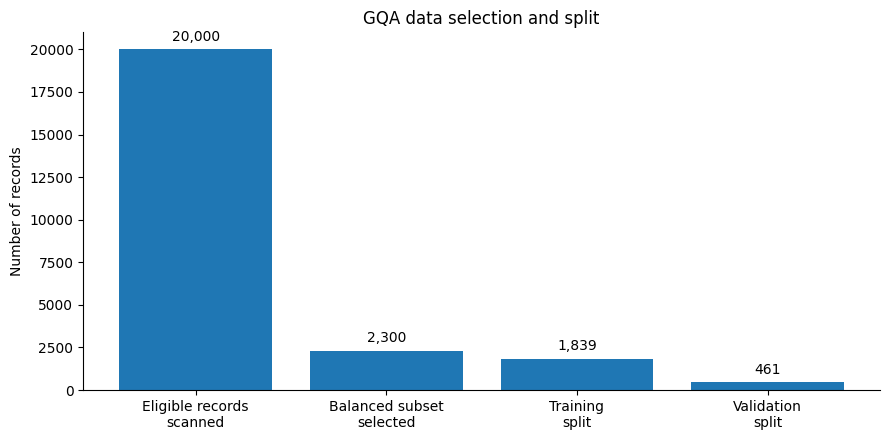

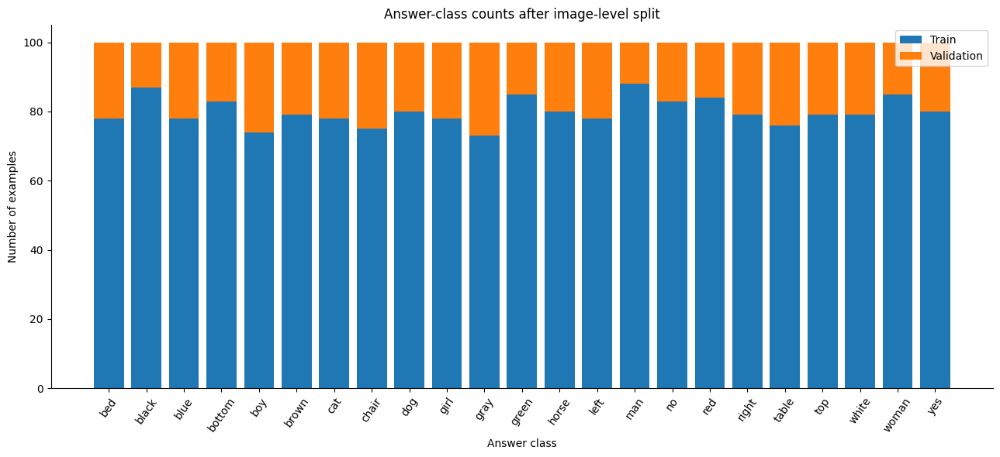

In [43]:
import matplotlib.pyplot as plt
from collections import Counter

# Recheck the existing split
def answer_of(record):
    for key in ("answer", "target", "label"):
        if key in record and record[key] is not None:
            return str(record[key]).strip().lower()
    return None

def image_of(record):
    for key in ("imageId", "image_id", "image"):
        if key in record and record[key] is not None:
            return str(record[key])
    return None

selected_answers = {answer_of(r) for r in balanced_subset}
train_answers = {answer_of(r) for r in balanced_train}
val_answers = {answer_of(r) for r in balanced_val}

train_images = {image_of(r) for r in balanced_train}
val_images = {image_of(r) for r in balanced_val}

assert len(train_images & val_images) == 0, "Train/validation image overlap found."
assert selected_answers == train_answers == val_answers, "An answer class is missing from a split."

print(f"Scanned eligible records: {len(scan_records_20k):,}")
print(f"Selected: {len(balanced_subset):,} ({len(selected_answers)} answer classes)")
print(f"Train: {len(balanced_train):,}")
print(f"Validation: {len(balanced_val):,}")
print(f"Shared images: {len(train_images & val_images)}")
print("Check passed: every selected answer class appears in both splits.")

# Plot 1: known data-selection and split stages
stage_names = [
    "Eligible records\nscanned",
    "Balanced subset\nselected",
    "Training\nsplit",
    "Validation\nsplit"
]
stage_counts = [
    len(scan_records_20k),
    len(balanced_subset),
    len(balanced_train),
    len(balanced_val)
]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(stage_names, stage_counts)
ax.set_title("GQA data selection and split")
ax.set_ylabel("Number of records")
ax.bar_label(bars, labels=[f"{n:,}" for n in stage_counts], padding=4)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Plot 2: selected examples per answer class, split into train and validation
train_counts = Counter(answer_of(r) for r in balanced_train)
val_counts = Counter(answer_of(r) for r in balanced_val)
classes = sorted(selected_answers)

train_values = [train_counts[c] for c in classes]
val_values = [val_counts[c] for c in classes]

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(classes, train_values, label="Train")
ax.bar(classes, val_values, bottom=train_values, label="Validation")
ax.set_title("Answer-class counts after image-level split")
ax.set_ylabel("Number of examples")
ax.set_xlabel("Answer class")
ax.tick_params(axis="x", rotation=55)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

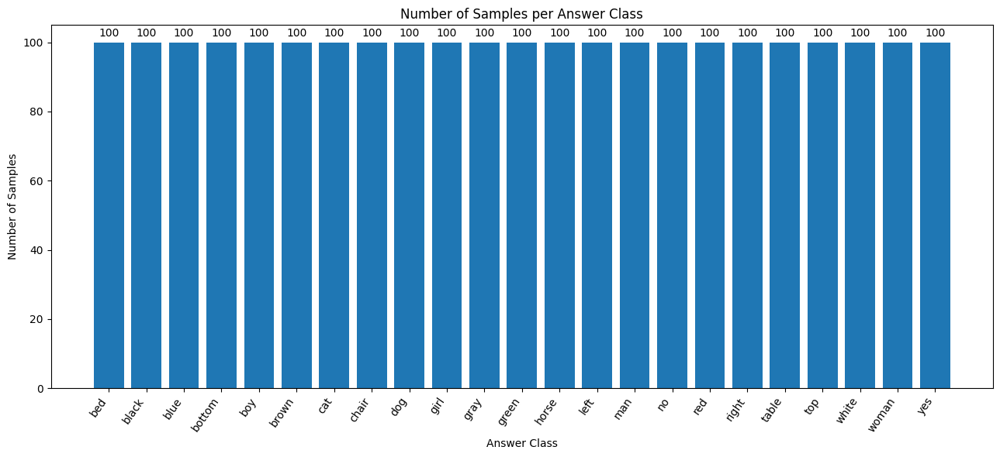

In [44]:
import matplotlib.pyplot as plt
from collections import Counter

# Count examples per answer class in the selected dataset
class_counts = Counter(
    str(record["answer"]).strip().lower()
    for record in balanced_subset
)

classes = sorted(class_counts)
counts = [class_counts[c] for c in classes]

plt.figure(figsize=(13, 6))
bars = plt.bar(classes, counts)

plt.title("Number of Samples per Answer Class")
plt.xlabel("Answer Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=55, ha="right")
plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

# Important graph for data cleaning stage and accuracy comparision

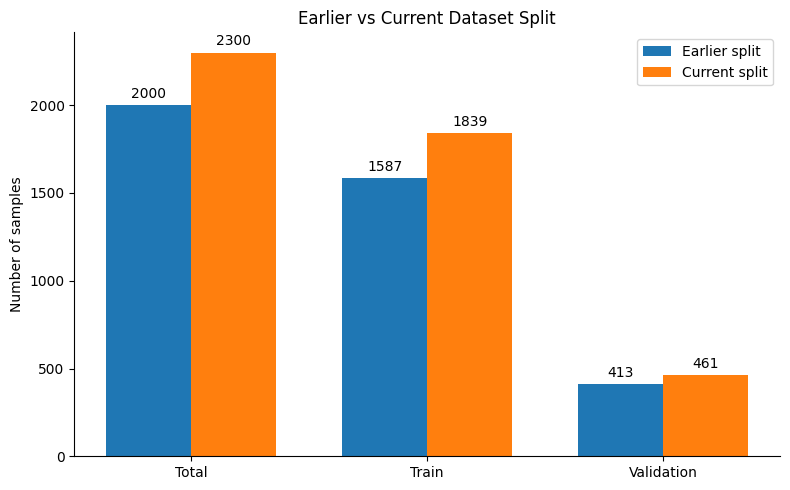

Accuracy not plotted. Set EARLIER_ACCURACY to its percentage value.


In [45]:
import matplotlib.pyplot as plt
import numpy as np

# Earlier split
EARLIER_TOTAL = 2000
EARLIER_TRAIN = 1587
EARLIER_VAL = 413

# Current split
CURRENT_TOTAL = len(balanced_subset)
CURRENT_TRAIN = len(balanced_train)
CURRENT_VAL = len(balanced_val)

# Enter the earlier accuracy as a percentage (e.g. 62.5).
# Leave as None if you don't have it.
EARLIER_ACCURACY = None

# Compare sample counts
labels = ["Total", "Train", "Validation"]
earlier_counts = [EARLIER_TOTAL, EARLIER_TRAIN, EARLIER_VAL]
current_counts = [CURRENT_TOTAL, CURRENT_TRAIN, CURRENT_VAL]

x = np.arange(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width / 2, earlier_counts, width, label="Earlier split")
bars2 = ax.bar(x + width / 2, current_counts, width, label="Current split")

ax.set_title("Earlier vs Current Dataset Split")
ax.set_ylabel("Number of samples")
ax.set_xticks(x, labels)
ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Plot earlier accuracy if provided
if EARLIER_ACCURACY is not None:
    fig, ax = plt.subplots(figsize=(5, 4))
    bars = ax.bar(["Earlier model"], [EARLIER_ACCURACY])

    ax.set_title("Earlier Model Accuracy")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 100)
    ax.bar_label(bars, fmt="%.2f%%", padding=3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()
else:
    print("Accuracy not plotted. Set EARLIER_ACCURACY to its percentage value.")

rebuilding vocab

In [69]:
import torch
if "DEVICE" not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

required = ["DEVICE", "train_graphs", "val_graphs", "object_vocab", "relation_vocab",
            "attribute_vocab", "convert_gqa_to_kg", "kg_to_tensors", "VisualGraphEncoder",
            "GraphQuestionAnswering", "get_graph_tensors", "tokenizer", "question_encoder",
            "balanced_train", "balanced_val"]
for n in required:
    print(f"{n}: {'OK' if n in globals() else 'MISSING'}")

DEVICE: OK
train_graphs: OK
val_graphs: OK
object_vocab: OK
relation_vocab: OK
attribute_vocab: OK
convert_gqa_to_kg: OK
kg_to_tensors: OK
VisualGraphEncoder: OK
GraphQuestionAnswering: OK
get_graph_tensors: OK
tokenizer: OK
question_encoder: OK
balanced_train: OK
balanced_val: OK


Question encoder function

In [50]:
from tqdm.auto import tqdm

def encode_questions(records, batch_size=32):
    all_embeddings = []
    for start in tqdm(range(0, len(records), batch_size)):
        batch = records[start:start + batch_size]
        texts = [r["question"] for r in batch]
        inputs = tokenizer(texts, padding=True, truncation=True,
                           max_length=64, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            outputs = question_encoder(**inputs)
            mask = inputs["attention_mask"].unsqueeze(-1)
            emb = (outputs.last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embeddings.append(emb.cpu())
    return torch.cat(all_embeddings, dim=0)

In [66]:
torch.manual_seed(42)
encoder = VisualGraphEncoder(
    num_objects=len(object_vocab),
    num_attributes=len(attribute_vocab),
    num_relations=len(relation_vocab) + 1,
    embedding_dim=256,
    num_bases=30
).to(DEVICE)
print("Fresh encoder ready. Params:", f"{sum(p.numel() for p in encoder.parameters()):,}")

Fresh encoder ready. Params: 4,676,580


In [68]:
from transformers import AutoTokenizer, AutoModel

QUESTION_MODEL = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(QUESTION_MODEL)

question_encoder = AutoModel.from_pretrained(
    QUESTION_MODEL
).to(DEVICE)

question_encoder.eval()

for param in question_encoder.parameters():
    param.requires_grad = False

print("Question encoder ready.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Question encoder ready.


Fresh graph encoder

In [70]:
import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

encoder = VisualGraphEncoder(
    num_objects=len(object_vocab),
    num_attributes=len(attribute_vocab),
    num_relations=len(relation_vocab) + 1,
    embedding_dim=256,
    num_bases=30
).to(DEVICE)
print("Fresh encoder ready. Params:", f"{sum(p.numel() for p in encoder.parameters()):,}")

Fresh encoder ready. Params: 4,676,580


answer vocab, training loaders

In [71]:
from torch.utils.data import Dataset, DataLoader
from collections import Counter

def normalize_answer(a):
    return str(a).lower().strip()

train_answers = {normalize_answer(r["answer"]) for r in balanced_train}
val_answers = {normalize_answer(r["answer"]) for r in balanced_val}
assert val_answers <= train_answers, f"Unseen val answers: {val_answers - train_answers}"

answer_vocab = {a: i for i, a in enumerate(sorted(train_answers))}
id_to_answer = {i: a for a, i in answer_vocab.items()}
num_answers = len(answer_vocab)

train_question_embeddings = encode_questions(balanced_train)
val_question_embeddings = encode_questions(balanced_val)

class GQADataset(Dataset):
    def __init__(self, records, embs, vocab):
        self.records, self.embs, self.vocab = records, embs, vocab
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        r = self.records[i]
        return {"image_id": str(r["imageId"]),
                "question_embedding": self.embs[i],
                "answer_id": self.vocab[normalize_answer(r["answer"])]}

train_dataset = GQADataset(balanced_train, train_question_embeddings, answer_vocab)
val_dataset = GQADataset(balanced_val, val_question_embeddings, answer_vocab)
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False)

model = GraphQuestionAnswering(graph_encoder=encoder, num_answers=num_answers).to(DEVICE)

print("Train:", len(train_dataset), "| Val:", len(val_dataset), "| Classes:", num_answers)
print("Chance level:", f"{1/num_answers:.2%}")
print("Majority-class baseline (val):",
      f"{max(Counter(normalize_answer(r['answer']) for r in balanced_val).values())/len(balanced_val):.2%}")

  0%|          | 0/58 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

Train: 1839 | Val: 461 | Classes: 23
Chance level: 4.35%
Majority-class baseline (val): 5.86%


In [72]:
from sklearn.linear_model import LogisticRegression

y_tr = [answer_vocab[normalize_answer(r["answer"])] for r in balanced_train]
y_va = [answer_vocab[normalize_answer(r["answer"])] for r in balanced_val]

clf = LogisticRegression(max_iter=2000, C=1.0)
clf.fit(train_question_embeddings.numpy(), y_tr)
question_only_acc = clf.score(val_question_embeddings.numpy(), y_va)
print(f"Question-only baseline (no graph): {question_only_acc:.2%}")

Question-only baseline (no graph): 39.26%


In [73]:
import math
import torch.nn as nn
import torch.optim as optim

EPOCHS = 10
ACCUM_STEPS = 16          # effective batch size
MAX_LR = 3e-4
WEIGHT_DECAY = 0.01
LABEL_SMOOTHING = 0.1
PATIENCE = 3
MAX_GRAD_NORM = 1.0

optimizer = optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)

steps_per_epoch = math.ceil(len(train_loader) / ACCUM_STEPS)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR,
    total_steps=EPOCHS * steps_per_epoch,
    pct_start=0.2, anneal_strategy="cos"
)

train_criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
eval_criterion = nn.CrossEntropyLoss()   # plain CE so val loss is comparable

print("Optimizer steps per epoch:", steps_per_epoch)
print("Total optimizer steps:", EPOCHS * steps_per_epoch)

Optimizer steps per epoch: 115
Total optimizer steps: 1150


New training loop

In [74]:
import time, copy
from tqdm.auto import tqdm

history = []
best_val_accuracy, best_model_state, best_epoch = 0.0, None, 0
epochs_without_improvement = 0
CKPT_PATH = f"{PROJECT_DIR}/checkpoints/balanced_graph_qa_best.pt"

def train_one_epoch():
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    optimizer.zero_grad()
    pbar = tqdm(train_loader, leave=False)
    for i, batch in enumerate(pbar):
        g = get_graph_tensors(batch["image_id"][0])
        q = batch["question_embedding"].squeeze(0).to(DEVICE)
        y = batch["answer_id"].to(DEVICE)

        logits, _ = model(g, q)
        loss = train_criterion(logits.unsqueeze(0), y)
        (loss / ACCUM_STEPS).backward()

        if (i + 1) % ACCUM_STEPS == 0 or (i + 1) == len(train_loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

        total_loss += loss.item()
        correct += (logits.argmax(-1) == y).sum().item()
        n += 1
        pbar.set_postfix(loss=f"{loss.item():.3f}")
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate():
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for batch in val_loader:
        g = get_graph_tensors(batch["image_id"][0])
        q = batch["question_embedding"].squeeze(0).to(DEVICE)
        y = batch["answer_id"].to(DEVICE)
        logits, _ = model(g, q)
        total_loss += eval_criterion(logits.unsqueeze(0), y).item()
        correct += (logits.argmax(-1) == y).sum().item()
        n += 1
    return total_loss / n, correct / n

for epoch in range(EPOCHS):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch()
    va_loss, va_acc = evaluate()
    dt = time.time() - t0

    history.append({"epoch": epoch + 1, "train_loss": tr_loss, "train_accuracy": tr_acc,
                    "val_loss": va_loss, "val_accuracy": va_acc, "time_seconds": dt,
                    "lr": optimizer.param_groups[0]["lr"]})

    print(f"\nEpoch {epoch+1}/{EPOCHS} | {dt:.0f}s | lr {optimizer.param_groups[0]['lr']:.2e}")
    print(f"Train loss {tr_loss:.4f} acc {tr_acc:.2%} | Val loss {va_loss:.4f} acc {va_acc:.2%}")

    if va_acc > best_val_accuracy:
        best_val_accuracy, best_epoch = va_acc, epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
        torch.save({"epoch": best_epoch, "model_state_dict": best_model_state,
                    "val_accuracy": va_acc, "answer_vocab": answer_vocab,
                    "history": history}, CKPT_PATH)
        print("  -> new best, checkpoint saved")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping (no improvement for {PATIENCE} epochs).")
            break

print(f"\nBest val accuracy: {best_val_accuracy:.2%} at epoch {best_epoch}")

  0%|          | 0/1839 [00:00<?, ?it/s]


Epoch 1/10 | 831s | lr 1.57e-04
Train loss 3.0932 acc 9.08% | Val loss 2.9719 acc 19.96%
  -> new best, checkpoint saved


  0%|          | 0/1839 [00:00<?, ?it/s]


Epoch 2/10 | 833s | lr 3.00e-04
Train loss 2.5716 acc 33.06% | Val loss 1.7773 acc 49.89%
  -> new best, checkpoint saved


  0%|          | 0/1839 [00:00<?, ?it/s]


Epoch 3/10 | 830s | lr 2.88e-04
Train loss 1.8018 acc 53.34% | Val loss 1.5486 acc 49.89%


... (8 outputs left out)

  0%|          | 0/1839 [00:00<?, ?it/s]


Epoch 8/10 | 830s | lr 4.36e-05
Train loss 0.9589 acc 89.94% | Val loss 1.3180 acc 57.48%


  0%|          | 0/1839 [00:00<?, ?it/s]

KeyboardInterrupt: 

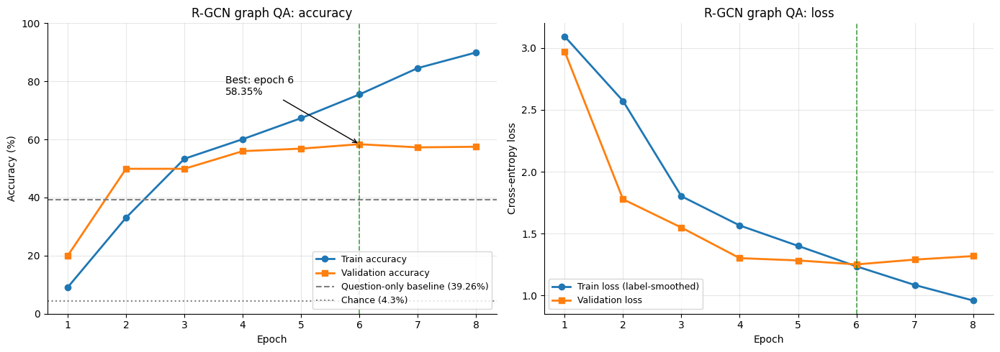

In [75]:
import matplotlib.pyplot as plt
import os

# Numbers copied from your training log (epochs 1-8)
epochs     = [1, 2, 3, 4, 5, 6, 7, 8]
train_loss = [3.0932, 2.5716, 1.8018, 1.5655, 1.4005, 1.2352, 1.0844, 0.9589]
val_loss   = [2.9719, 1.7773, 1.5486, 1.3013, 1.2829, 1.2507, 1.2897, 1.3180]
train_acc  = [9.08, 33.06, 53.34, 60.09, 67.32, 75.48, 84.56, 89.94]
val_acc    = [19.96, 49.89, 49.89, 55.97, 56.83, 58.35, 57.27, 57.48]

BEST_EPOCH = 6
CHANCE = 100 / 23          # 4.3%
QUESTION_ONLY = 39.26

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: accuracy
ax = axes[0]
ax.plot(epochs, train_acc, marker="o", linewidth=2, label="Train accuracy")
ax.plot(epochs, val_acc, marker="s", linewidth=2, label="Validation accuracy")
ax.axhline(QUESTION_ONLY, linestyle="--", linewidth=1.5, color="gray",
           label=f"Question-only baseline ({QUESTION_ONLY}%)")
ax.axhline(CHANCE, linestyle=":", linewidth=1.5, color="gray",
           label=f"Chance ({CHANCE:.1f}%)")
ax.axvline(BEST_EPOCH, linestyle="--", linewidth=1.2, color="green", alpha=0.7)
ax.annotate(f"Best: epoch {BEST_EPOCH}\n{val_acc[BEST_EPOCH-1]:.2f}%",
            xy=(BEST_EPOCH, val_acc[BEST_EPOCH-1]),
            xytext=(BEST_EPOCH - 2.3, val_acc[BEST_EPOCH-1] + 17),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set_title("R-GCN graph QA: accuracy")
ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)")
ax.set_xticks(epochs); ax.set_ylim(0, 100)
ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

# Panel 2: loss
ax = axes[1]
ax.plot(epochs, train_loss, marker="o", linewidth=2, label="Train loss (label-smoothed)")
ax.plot(epochs, val_loss, marker="s", linewidth=2, label="Validation loss")
ax.axvline(BEST_EPOCH, linestyle="--", linewidth=1.2, color="green", alpha=0.7)
ax.set_title("R-GCN graph QA: loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss")
ax.set_xticks(epochs)
ax.grid(alpha=0.3); ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)
plt.savefig(f"{PROJECT_DIR}/results/graph_qa_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [76]:
from sklearn.metrics import f1_score, classification_report

model.load_state_dict(best_model_state)
model.eval()

y_true, y_pred, top3_hits = [], [], 0
with torch.no_grad():
    for batch in val_loader:
        g = get_graph_tensors(batch["image_id"][0])
        q = batch["question_embedding"].squeeze(0).to(DEVICE)
        logits, _ = model(g, q)
        y = batch["answer_id"].item()
        y_true.append(y)
        y_pred.append(logits.argmax(-1).item())
        top3_hits += int(y in logits.topk(3).indices.tolist())

acc = np.mean(np.array(y_true) == np.array(y_pred))
print(f"Graph model accuracy:     {acc:.2%}")
print(f"Top-3 accuracy:           {top3_hits/len(y_true):.2%}")
print(f"Macro-F1:                 {f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}")
print(f"Question-only baseline:   {question_only_acc:.2%}   (Step D2)")
print(f"Chance:                   {1/num_answers:.2%}")

print(classification_report(y_true, y_pred, labels=list(range(num_answers)),
      target_names=[id_to_answer[i] for i in range(num_answers)], zero_division=0))

# Save the trained graph encoder separately for the VLM experiments
torch.save(model.graph_encoder.state_dict(),
           f"{PROJECT_DIR}/checkpoints/balanced_rgcn_encoder.pt")

Graph model accuracy:     58.35%
Top-3 accuracy:           84.16%
Macro-F1:                 0.554
Question-only baseline:   39.26%   (Step D2)
Chance:                   4.35%
              precision    recall  f1-score   support

         bed       0.85      0.77      0.81        22
       black       0.19      0.38      0.25        13
        blue       0.42      0.23      0.29        22
      bottom       0.43      0.59      0.50        17
         boy       0.91      0.81      0.86        26
       brown       0.44      0.57      0.50        21
         cat       0.96      1.00      0.98        22
       chair       0.70      0.76      0.73        25
         dog       0.89      0.80      0.84        20
        girl       0.80      0.91      0.85        22
        gray       0.44      0.26      0.33        27
       green       0.25      0.53      0.34        15
       horse       0.87      1.00      0.93        20
        left       0.43      0.95      0.59        22
         man  

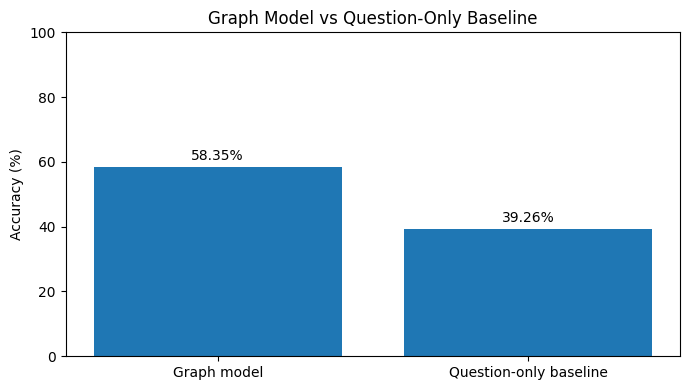

In [78]:
import matplotlib.pyplot as plt

labels = ["Graph model", "Question-only baseline"]
values = [acc * 100, question_only_acc * 100]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, values)
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylabel("Accuracy (%)")
plt.title("Graph Model vs Question-Only Baseline")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

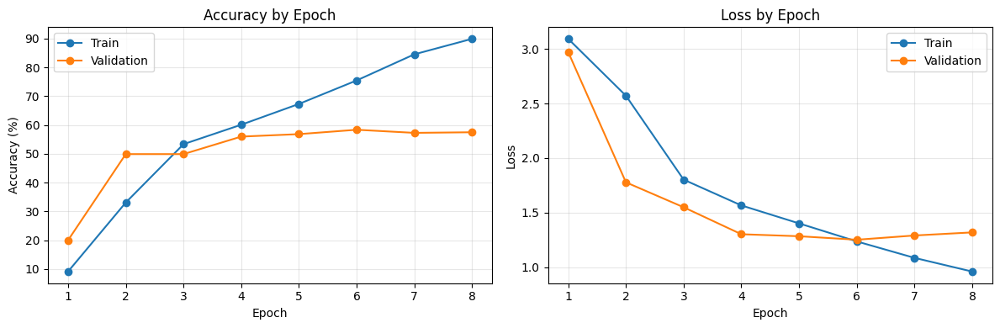

In [79]:
import matplotlib.pyplot as plt

epochs = list(range(1, 9))

train_acc = [9.08, 33.06, 53.34, 60.09, 67.32, 75.48, 84.56, 89.94]
val_acc   = [19.96, 49.89, 49.89, 55.97, 56.83, 58.35, 57.27, 57.48]

train_loss = [3.0932, 2.5716, 1.8018, 1.5655, 1.4005, 1.2352, 1.0844, 0.9589]
val_loss   = [2.9719, 1.7773, 1.5486, 1.3013, 1.2829, 1.2507, 1.2897, 1.3180]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, train_acc, marker="o", label="Train")
axes[0].plot(epochs, val_acc, marker="o", label="Validation")
axes[0].set(title="Accuracy by Epoch", xlabel="Epoch", ylabel="Accuracy (%)")
axes[0].set_xticks(epochs)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, train_loss, marker="o", label="Train")
axes[1].plot(epochs, val_loss, marker="o", label="Validation")
axes[1].set(title="Loss by Epoch", xlabel="Epoch", ylabel="Loss")
axes[1].set_xticks(epochs)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

Integrating VLM with the Graph based approach

In [80]:
ckpt = torch.load(f"{PROJECT_DIR}/checkpoints/balanced_graph_qa_best.pt", map_location=DEVICE)
assert ckpt["answer_vocab"] == answer_vocab, "answer_vocab differs from the checkpoint"
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
for p in model.parameters():
    p.requires_grad = False
print("Graph model restored from epoch", ckpt["epoch"], "| val acc", f"{ckpt['val_accuracy']:.2%}")

for n in ["train_graphs", "val_graphs", "object_vocab", "convert_gqa_to_kg", "kg_to_tensors",
          "get_graph_tensors", "tokenizer", "question_encoder", "balanced_train", "balanced_val",
          "train_question_embeddings", "val_question_embeddings", "normalize_answer", "id_to_answer"]:
    print(f"{n}: {'OK' if n in globals() else 'MISSING'}")

Graph model restored from epoch 6 | val acc 58.35%
train_graphs: OK
val_graphs: OK
object_vocab: OK
convert_gqa_to_kg: OK
kg_to_tensors: OK
get_graph_tensors: OK
tokenizer: OK
question_encoder: OK
balanced_train: OK
balanced_val: OK
train_question_embeddings: OK
val_question_embeddings: OK
normalize_answer: OK
id_to_answer: OK


load Qwen2-VL and define the answer helper

In [81]:
import importlib.util, transformers, re, time, copy, random, io, os, requests
from contextlib import nullcontext
import numpy as np, pandas as pd
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

if importlib.util.find_spec("peft") is None:
    !pip install -q peft accelerate
print("transformers", transformers.__version__)

from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

QWEN_ID = "Qwen/Qwen2-VL-2B-Instruct"
DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
AUTOCAST = dict(device_type="cuda", dtype=DTYPE, enabled=(DTYPE != torch.float32))
print("dtype:", DTYPE)

qwen = Qwen2VLForConditionalGeneration.from_pretrained(QWEN_ID, torch_dtype=DTYPE).to(DEVICE)
processor = AutoProcessor.from_pretrained(QWEN_ID, min_pixels=128*28*28, max_pixels=448*28*28)
qwen_tok = processor.tokenizer
for p in qwen.parameters():
    p.requires_grad = False
qwen.eval()

VLM = qwen                       # becomes the LoRA-wrapped model after training
EMBED = qwen.get_input_embeddings()
HIDDEN = EMBED.weight.shape[1]
EMB_STD = EMBED.weight.float().std().item()
IM_END_ID = qwen_tok.convert_tokens_to_ids("<|im_end|>")

def base_mode(m):                # zero-shot behaviour: switch LoRA off if it is attached
    return m.disable_adapter() if hasattr(m, "disable_adapter") else nullcontext()

@torch.no_grad()
def vlm_answer(prompt, image=None, max_new=8):
    content = ([{"type": "image"}] if image is not None else []) + [{"type": "text", "text": prompt}]
    text = processor.apply_chat_template([{"role": "user", "content": content}],
                                         tokenize=False, add_generation_prompt=True)
    inp = processor(text=[text], images=[image] if image is not None else None,
                    return_tensors="pt").to(DEVICE)
    if "pixel_values" in inp:
        inp["pixel_values"] = inp["pixel_values"].to(DTYPE)
    with base_mode(VLM):
        out = VLM.generate(**inp, max_new_tokens=max_new, do_sample=False)
    return processor.batch_decode(out[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

print("Smoke test:", vlm_answer("What is the capital of France? Answer with one word."))

transformers 5.22.0
dtype: torch.bfloat16


config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Smoke test: Paris


Cell 3: shared metrics (used by every experiment)

In [82]:
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)
ALL_DF, ALL_SUM = {}, {}

N1, N2, N2D = "Exp1: image, no memory", "Exp2: KG as text", "Exp2: KG as text (degraded KG)"
N3, N3G = "Exp3: KG tokens + LoRA", "Exp3 + gate"
N3D, N3DG = "Exp3 (degraded KG, no gate)", "Exp3 + gate (degraded KG)"
NCTRL = "Control: Exp3 with wrong graph"

def norm_pred(s):
    s = re.sub(r"[^a-z0-9 ]+", " ", str(s).lower().strip())
    s = re.sub(r"\b(the|a|an)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

VOCAB_NORM = {norm_pred(a) for a in answer_vocab}
sync = lambda: torch.cuda.synchronize() if torch.cuda.is_available() else None

def summarize(df):
    return {"n": len(df), "accuracy": 100 * df.correct.mean(), "in_vocab_rate": 100 * df.in_vocab.mean(),
            "latency_ms_mean": df.latency_ms.mean(), "latency_ms_median": df.latency_ms.median(),
            "latency_ms_p95": df.latency_ms.quantile(0.95), "image_passes_per_q": df.image_passes.mean(),
            "vlm_calls_per_q": df.vlm_calls.mean(), "fallback_rate": 100 * df.fallback.mean()}

def register(name, df):
    df = df.copy(); df["name"] = name
    ALL_DF[name], ALL_SUM[name] = df, summarize(df)
    s = ALL_SUM[name]
    print(f"{name}: acc {s['accuracy']:.2f}% | in-vocab {s['in_vocab_rate']:.1f}% | "
          f"{s['latency_ms_mean']:.0f} ms/q | image passes/q {s['image_passes_per_q']:.2f} | fallback {s['fallback_rate']:.1f}%")
    df.to_csv(f"{PROJECT_DIR}/results/{re.sub('[^A-Za-z0-9]+', '_', name)}.csv", index=False)
    return df

def run_eval(name, fn, items, warmup=2):
    for it in items[:warmup]:
        fn(it)
    rows = []
    for it in tqdm(items, desc=name, leave=False):
        sync(); t0 = time.perf_counter()
        out = fn(it)
        sync(); ms = 1000 * (time.perf_counter() - t0)
        pred, gold = norm_pred(out["pred"]), norm_pred(it["answer"])
        rows.append({"idx": it["idx"], "question": it["question"], "gold": gold, "pred": pred,
                     "correct": int(pred == gold), "in_vocab": int(pred in VOCAB_NORM), "latency_ms": ms,
                     "image_passes": out.get("image_passes", 0), "vlm_calls": out.get("vlm_calls", 1),
                     "fallback": int(out.get("fallback", False)), "conf": out.get("conf", np.nan),
                     "cov_missing": int(out.get("cov_missing", False))})
    return register(name, pd.DataFrame(rows))

def compose(front, img, fb, name):
    """Replace the front-end answer with the logged image answer wherever a fallback happens."""
    f = front.copy().reset_index(drop=True)
    r = img.set_index("idx").loc[f.idx.values].reset_index()
    fb = np.asarray(fb).astype(bool)
    f["fallback"] = fb.astype(int)
    for c in ["pred", "correct", "in_vocab"]:
        f.loc[fb, c] = r.loc[fb, c].values
    f.loc[fb, "latency_ms"] += r.loc[fb, "latency_ms"].values
    f.loc[fb, "image_passes"] = 1
    f.loc[fb, "vlm_calls"] += 1
    return register(name, f)

graph helpers, evaluation items, dev split, soft tokens

In [83]:
from sklearn.model_selection import GroupShuffleSplit

K_NODES = 8
to_dev = lambda t: {k: v.to(DEVICE) for k, v in t.items()}
scene_of = lambda image_id: train_graphs.get(str(image_id)) or val_graphs.get(str(image_id))

@torch.no_grad()
def embed_question(q):
    inp = tokenizer([q], padding=True, truncation=True, max_length=64, return_tensors="pt").to(DEVICE)
    out = question_encoder(**inp)
    m = inp["attention_mask"].unsqueeze(-1)
    return ((out.last_hidden_state * m).sum(1) / m.sum(1).clamp(min=1))[0]

@torch.no_grad()
def graph_soft(g, q_emb):
    nodes, _ = model.graph_encoder(g["object_ids"], g["attribute_ids"], g["edge_index"], g["edge_type"])
    attended, w = model.attention(nodes, q_emb)
    top = w.topk(min(K_NODES, nodes.size(0))).indices
    return torch.cat([attended.unsqueeze(0), nodes[top]], 0).float(), w

# --- which objects does a question mention, and does the graph contain them? ---
STOP_OBJ = {"image", "picture", "photo", "photograph", "scene", "side", "part", "view", "front",
            "back", "top", "bottom", "middle", "background", "foreground"}
OBJ_NAMES = set(object_vocab) - STOP_OBJ

def mentioned_objects(q):
    w = re.findall(r"[a-z]+", q.lower())
    c = set(w) | {w[i] + " " + w[i + 1] for i in range(len(w) - 1)}
    c |= {x[:-1] for x in list(c) if x.endswith("s")} | {x[:-2] for x in list(c) if x.endswith("es")}
    return c & OBJ_NAMES

def degrade_scene(scene, mentioned, drop_prob, rng):
    """Simulate an incomplete memory: with prob drop_prob, delete the objects the question asks about."""
    if drop_prob <= 0 or not mentioned or rng.random() >= drop_prob:
        return scene
    keep = {oid for oid, o in scene["objects"].items() if o["name"] not in mentioned}
    if not keep or len(keep) == len(scene["objects"]):
        return scene
    objs = {oid: {**o, "relations": [r for r in o.get("relations", []) if str(r["object"]) in keep]}
            for oid, o in scene["objects"].items() if oid in keep}
    return {**scene, "objects": objs}

def make_item(idx, image_id, question, answer=None):
    q = question.strip()
    suffix = f"\nQuestion: {q}\nAnswer with one word or phrase.<|im_end|>\n<|im_start|>assistant\n"
    it = {"idx": idx, "image_id": str(image_id), "question": q, "answer": answer,
          "suffix_ids": torch.tensor(qwen_tok(suffix, add_special_tokens=False).input_ids, device=DEVICE)}
    if answer is not None:
        it["answer_ids"] = torch.tensor(qwen_tok(answer + "<|im_end|>", add_special_tokens=False).input_ids, device=DEVICE)
    return it

def build_items(records, idxs):
    return [make_item(i, records[i]["imageId"], records[i]["question"], normalize_answer(records[i]["answer"]))
            for i in idxs]

# Dev split (by image) from TRAIN only; the 461 validation questions are scored once at the end
groups = [str(r["imageId"]) for r in balanced_train]
sub_idx, dev_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
                        .split(np.arange(len(balanced_train)), groups=groups))
train_items = build_items(balanced_train, sub_idx)
dev_items = build_items(balanced_train, dev_idx)
val_items = build_items(balanced_val, range(len(balanced_val)))

@torch.no_grad()
def attach_soft(items, q_embs):
    for it in tqdm(items, leave=False):
        soft, _ = graph_soft(get_graph_tensors(it["image_id"]), q_embs[it["idx"]].to(DEVICE))
        it["soft"] = soft.cpu()

attach_soft(train_items, train_question_embeddings)
attach_soft(dev_items, train_question_embeddings)
print("Train-sub:", len(train_items), "| Dev:", len(dev_items), "| Val (final test):", len(val_items))

  0%|          | 0/1657 [00:00<?, ?it/s]

  0%|          | 0/182 [00:00<?, ?it/s]

Train-sub: 1657 | Dev: 182 | Val (final test): 461


download the validation images and lock the evaluation set

In [84]:
from concurrent.futures import ThreadPoolExecutor

IMG_DIR = f"{PROJECT_DIR}/data/raw/gqa_images_for_eval"
os.makedirs(IMG_DIR, exist_ok=True)

def ensure_image(image_id):
    p = f"{IMG_DIR}/{image_id}.jpg"
    if not os.path.exists(p):
        r = requests.get(f"https://cs.stanford.edu/people/dorarad/gqa/images/{image_id}.jpg", timeout=30)
        r.raise_for_status()
        open(p, "wb").write(r.content)
    return p

def get_image(image_id):
    return Image.open(ensure_image(image_id)).convert("RGB")

def _try(i):
    try: ensure_image(i); return None
    except Exception as e: return (i, str(e)[:80])

ids = sorted({it["image_id"] for it in val_items})
with ThreadPoolExecutor(8) as ex:
    fails = [r for r in tqdm(ex.map(_try, ids), total=len(ids)) if r]
print("Unique images:", len(ids), "| failed:", len(fails), fails[:3])

if fails:
    bad = {i for i, _ in fails}
    val_items = [it for it in val_items if it["image_id"] not in bad]
print("Final evaluation set:", len(val_items), "questions")

  0%|          | 0/416 [00:00<?, ?it/s]

Unique images: 416 | failed: 416 [('1159301', '404 Client Error: Not Found for url: https://cs.stanford.edu/people/dorarad/gqa/'), ('1159853', '404 Client Error: Not Found for url: https://cs.stanford.edu/people/dorarad/gqa/'), ('1159867', '404 Client Error: Not Found for url: https://cs.stanford.edu/people/dorarad/gqa/')]
Final evaluation set: 0 questions


In [88]:
val_items = build_items(balanced_val, range(len(balanced_val)))

In [89]:
print(len(val_items))  # should be 461

461


projector, input assembly, smoke test

In [90]:
class GraphProjector(nn.Module):
    def __init__(self, in_dim=256, hidden=HIDDEN, p=0.2):
        super().__init__()
        self.drop = nn.Dropout(p)
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(p), nn.Linear(hidden, hidden))
        self.norm = nn.LayerNorm(hidden)
        with torch.no_grad():
            self.norm.weight.fill_(EMB_STD)       # match the scale of real token embeddings
    def forward(self, x):
        return self.norm(self.net(self.drop(x)))

PREFIX_G = torch.tensor(qwen_tok("<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n<|im_start|>user\nScene memory: ",
                                 add_special_tokens=False).input_ids, device=DEVICE)
PREFIX_NOG = torch.tensor(qwen_tok("<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n<|im_start|>user",
                                   add_special_tokens=False).input_ids, device=DEVICE)

def make_pos(B, L):
    return torch.arange(L, device=DEVICE).view(1, 1, -1).expand(3, B, -1)

def assemble(batch, projector, use_graph, with_answer=True):
    seqs, labs = [], []
    for it in batch:
        prefix = PREFIX_G if use_graph else PREFIX_NOG
        parts, lab = [EMBED(prefix)], [-100] * len(prefix)
        if use_graph:
            soft = projector(it["soft"].to(DEVICE)).to(DTYPE)
            parts.append(soft); lab += [-100] * soft.size(0)
        parts.append(EMBED(it["suffix_ids"])); lab += [-100] * len(it["suffix_ids"])
        if with_answer:
            parts.append(EMBED(it["answer_ids"])); lab += it["answer_ids"].tolist()
        seqs.append(torch.cat(parts, 0)); labs.append(lab)
    B, L = len(seqs), max(s.size(0) for s in seqs)
    emb = torch.zeros(B, L, HIDDEN, dtype=DTYPE, device=DEVICE)
    mask = torch.zeros(B, L, dtype=torch.long, device=DEVICE)
    labels = torch.full((B, L), -100, dtype=torch.long, device=DEVICE)
    for i, (s, l) in enumerate(zip(seqs, labs)):
        emb[i, :s.size(0)] = s; mask[i, :s.size(0)] = 1
        labels[i, :len(l)] = torch.tensor(l, device=DEVICE)
    return emb, mask, labels, make_pos(B, L)

# smoke test: one forward pass before we spend time training
_p = GraphProjector().to(DEVICE)
emb, mask, labels, pos = assemble(train_items[:2], _p, True)
with torch.no_grad(), torch.autocast(**AUTOCAST):
    out = qwen(inputs_embeds=emb, attention_mask=mask, position_ids=pos, labels=labels, use_cache=False)
print("Smoke-test loss (should be a finite number):", out.loss.item())
del _p

Smoke-test loss (should be a finite number): 2.4355387687683105


LoRA training function with overfitting controls

In [91]:
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict
from transformers import get_cosine_schedule_with_warmup

def run_experiment(use_graph, tag, epochs=5, micro_bs=8, accum=2, lr_lora=1e-4, lr_proj=5e-4,
                   wd=0.05, patience=2, rank=8):
    random.seed(42); torch.manual_seed(42)
    cfg = LoraConfig(r=rank, lora_alpha=2 * rank, lora_dropout=0.1,
                     target_modules=["q_proj", "v_proj"], bias="none", task_type="CAUSAL_LM")
    pm = get_peft_model(qwen, cfg)
    projector = GraphProjector().to(DEVICE) if use_graph else None

    lora_params = [p for p in pm.parameters() if p.requires_grad]
    groups_ = [{"params": lora_params, "lr": lr_lora}]
    if use_graph:
        groups_.append({"params": projector.parameters(), "lr": lr_proj})
    opt = torch.optim.AdamW(groups_, weight_decay=wd)
    all_params = lora_params + (list(projector.parameters()) if use_graph else [])

    steps_per_epoch = (len(train_items) + micro_bs * accum - 1) // (micro_bs * accum)
    sched = get_cosine_schedule_with_warmup(opt, int(0.1 * epochs * steps_per_epoch), epochs * steps_per_epoch)
    scaler = torch.cuda.amp.GradScaler(enabled=(DTYPE == torch.float16))
    print(f"[{tag}] trainable: LoRA {sum(p.numel() for p in lora_params):,}" +
          (f" + projector {sum(p.numel() for p in projector.parameters()):,}" if use_graph else ""))

    def set_mode(train):
        pm.train(train)
        if projector is not None: projector.train(train)

    def batch_loss(batch):
        emb, mask, labels, pos = assemble(batch, projector, use_graph)
        with torch.autocast(**AUTOCAST):
            return pm(inputs_embeds=emb, attention_mask=mask, position_ids=pos, labels=labels, use_cache=False).loss

    @torch.no_grad()
    def dev_loss():
        set_mode(False); tot, n = 0.0, 0
        for s in range(0, len(dev_items), 16):
            b = dev_items[s:s + 16]; tot += batch_loss(b).item() * len(b); n += len(b)
        return tot / n

    best_loss, best_state, bad = float("inf"), None, 0
    for epoch in range(epochs):
        t0 = time.time(); set_mode(True)
        order = list(range(len(train_items))); random.shuffle(order)
        run_loss, steps = 0.0, 0
        opt.zero_grad()
        for bi, s in enumerate(range(0, len(order), micro_bs)):
            loss = batch_loss([train_items[j] for j in order[s:s + micro_bs]])
            scaler.scale(loss / accum).backward()
            run_loss += loss.item(); steps += 1
            if (bi + 1) % accum == 0 or s + micro_bs >= len(order):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(all_params, 1.0)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad()
        tr, dv = run_loss / steps, dev_loss()
        print(f"[{tag}] epoch {epoch+1}/{epochs} | train {tr:.4f} | dev {dv:.4f} | {time.time()-t0:.0f}s")
        if dv < best_loss:
            best_loss, bad = dv, 0
            best_state = {"lora": {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(pm).items()},
                          "proj": copy.deepcopy(projector.state_dict()) if use_graph else None}
            torch.save(best_state, f"{PROJECT_DIR}/checkpoints/qwen_{tag}_best.pt")
        else:
            bad += 1
            if bad >= patience:
                print(f"[{tag}] early stop"); break

    set_peft_model_state_dict(pm, best_state["lora"])
    if use_graph: projector.load_state_dict(best_state["proj"])
    set_mode(False)
    print(f"[{tag}] best dev loss: {best_loss:.4f} (best epoch weights restored)")
    return pm, projector

In [95]:
pm_g, proj_g = run_experiment(use_graph=True, tag="graph")
VLM = pm_g

/tmp/ipykernel_9659/2209508978.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DTYPE == torch.float16))


[graph] trainable: LoRA 1,089,536 + projector 2,758,656
[graph] epoch 1/5 | train 0.5351 | dev 0.2727 | 32s
[graph] epoch 2/5 | train 0.1966 | dev 0.1977 | 31s
[graph] epoch 3/5 | train 0.1537 | dev 0.1704 | 31s
[graph] epoch 4/5 | train 0.1050 | dev 0.1768 | 31s
[graph] epoch 5/5 | train 0.0743 | dev 0.1809 | 31s
[graph] early stop
[graph] best dev loss: 0.1704 (best epoch weights restored)


In [93]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [94]:
from peft.import_utils import is_torchao_available
print("torchao available to PEFT:", is_torchao_available())

torchao available to PEFT: False


evaluate Exp 3 and the wrong-graph control
This is the first time the validation questions are scored. Latency includes DistilBERT, R-GCN, attention, projector and generation, so the memory path isn’t flattered.

In [96]:
@torch.no_grad()
def gen_graph(pm, projector, it, use_graph=True, max_new=6):
    cur, _, _, _ = assemble([it], projector, use_graph, with_answer=False)
    toks, lps = [], []
    for _ in range(max_new):
        L = cur.size(1)
        with torch.autocast(**AUTOCAST):
            logits = pm(inputs_embeds=cur, attention_mask=torch.ones(1, L, dtype=torch.long, device=DEVICE),
                        position_ids=make_pos(1, L), use_cache=False).logits[0, -1]
        lp = torch.log_softmax(logits.float(), -1)
        nxt = int(lp.argmax())
        if nxt == IM_END_ID: break
        toks.append(nxt); lps.append(lp[nxt].item())
        cur = torch.cat([cur, EMBED(torch.tensor([nxt], device=DEVICE)).unsqueeze(0)], 1)
    conf = float(np.exp(np.mean(lps))) if lps else 0.0     # geometric-mean token probability
    return qwen_tok.decode(toks).strip(), conf

@torch.no_grad()
def graph_stage(pm, projector, it, drop_prob=0.0, swap=None):
    img_id = it["image_id"] if swap is None else swap[it["idx"]]
    q_emb = embed_question(it["question"])
    scene = scene_of(img_id)
    ment = mentioned_objects(it["question"])
    scene2 = degrade_scene(scene, ment, drop_prob, random.Random(1000 + it["idx"]))
    g = get_graph_tensors(img_id) if scene2 is scene else to_dev(kg_to_tensors(convert_gqa_to_kg(img_id, scene2)))
    soft, attn = graph_soft(g, q_emb)
    pred, conf = gen_graph(pm, projector, {**it, "soft": soft})
    names = {o["name"] for o in scene2["objects"].values()}
    return {"pred": pred, "conf": conf, "cov_missing": bool(ment - names), "image_passes": 0,
            "vlm_calls": 1, "scene": scene2, "attn": attn.cpu().numpy()}

def exp3_front(pm, projector, drop_prob=0.0, swap=None):
    def fn(it):
        o = graph_stage(pm, projector, it, drop_prob, swap)
        return {k: o[k] for k in ("pred", "conf", "cov_missing", "image_passes", "vlm_calls")}
    return fn

df3 = run_eval(N3, exp3_front(pm_g, proj_g), val_items)

# Control: pair every question with a different image's graph
ids_ = [it["image_id"] for it in val_items]; swap = {}
for k, it in enumerate(val_items):
    j = (k + 37) % len(ids_)
    while ids_[j] == it["image_id"]: j = (j + 1) % len(ids_)
    swap[it["idx"]] = ids_[j]
_ = run_eval(NCTRL, exp3_front(pm_g, proj_g, swap=swap), val_items)

Exp3: KG tokens + LoRA:   0%|          | 0/461 [00:00<?, ?it/s]

Exp3: KG tokens + LoRA: acc 64.64% | in-vocab 99.8% | 334 ms/q | image passes/q 0.00 | fallback 0.0%


Control: Exp3 with wrong graph:   0%|          | 0/461 [00:00<?, ?it/s]

Control: Exp3 with wrong graph: acc 32.54% | in-vocab 99.6% | 334 ms/q | image passes/q 0.00 | fallback 0.0%


Experiment 1, image + question

You can run this any time after Cell 5. It works with or without LoRA attached.

Diagnosing experiment 1

In [103]:
from pathlib import Path

print("PROJECT_DIR:", PROJECT_DIR)
print("Image folder exists:",
      Path(PROJECT_DIR, "data/raw/gqa_images_for_eval").exists())
print("Images found:",
      len(list(Path(PROJECT_DIR, "data/raw/gqa_images_for_eval").glob("*"))))
print("Number of evaluation items:", len(val_items))
print("Example evaluation item:", val_items[0] if val_items else "EMPTY")

PROJECT_DIR: /content/drive/MyDrive/KG_VLM_Research
Image folder exists: True
Images found: 0
Number of evaluation items: 461
Example evaluation item: {'idx': 0, 'image_id': '2396129', 'question': 'Do you see both pillows and sheets?', 'answer': 'yes', 'suffix_ids': tensor([   198,  14582,     25,   3155,    498,   1490,   2176,  65926,    323,
         24140,   5267,  16141,    448,    825,   3409,    476,  17133,     13,
        151645,    198, 151644,  77091,    198], device='cuda:0'), 'answer_ids': tensor([  9693, 151645], device='cuda:0')}


In [104]:
from pathlib import Path

root = Path(PROJECT_DIR)

# Search likely project locations for the example image
matches = list(root.rglob("2396129.jpg"))
matches += list(root.rglob("2396129.png"))
matches += list(root.rglob("2396129.jpeg"))

print("Matches:", matches[:20])
print("Total matches:", len(matches))

Matches: []
Total matches: 0


In [105]:
from pathlib import Path
from urllib.request import Request, urlopen
from PIL import Image
from io import BytesIO
import time

image_dir = Path(PROJECT_DIR) / "data/raw/gqa_images_for_eval"
image_dir.mkdir(parents=True, exist_ok=True)

# Only unique image IDs used by the 461 evaluation questions
image_ids = sorted({str(item["image_id"]) for item in val_items})
print(f"Unique images needed: {len(image_ids)}")

# GQA's official image archive is the reliable source.
# This cell tests whether the individual-image endpoint is accessible.
base_url = "https://downloads.cs.stanford.edu/nlp/data/gqa/images"

downloaded, already_present, failed = [], [], []

for i, image_id in enumerate(image_ids, 1):
    dest = image_dir / f"{image_id}.jpg"

    if dest.exists():
        try:
            with Image.open(dest) as im:
                im.verify()
            already_present.append(image_id)
            continue
        except Exception:
            dest.unlink(missing_ok=True)

    try:
        req = Request(
            f"{base_url}/{image_id}.jpg",
            headers={"User-Agent": "Mozilla/5.0"}
        )
        with urlopen(req, timeout=30) as response:
            data = response.read()

        # Verify downloaded bytes are a readable image before saving
        with Image.open(BytesIO(data)) as im:
            im.verify()

        dest.write_bytes(data)
        downloaded.append(image_id)

    except Exception as e:
        failed.append((image_id, str(e)))

    if i % 25 == 0:
        print(f"Checked {i}/{len(image_ids)}")

print("\nDownload summary")
print("Newly downloaded:", len(downloaded))
print("Already present:", len(already_present))
print("Failed:", len(failed))
print("Example failures:", failed[:5])
print("Files in folder:", len(list(image_dir.glob("*.jpg"))))

Unique images needed: 416
Checked 25/416
Checked 50/416
Checked 75/416
Checked 100/416
Checked 125/416
Checked 150/416
Checked 175/416
Checked 200/416
Checked 225/416
Checked 250/416
Checked 275/416
Checked 300/416
Checked 325/416
Checked 350/416
Checked 375/416
Checked 400/416

Download summary
Newly downloaded: 0
Already present: 0
Failed: 416
Example failures: [('1159301', 'HTTP Error 404: Not Found'), ('1159853', 'HTTP Error 404: Not Found'), ('1159867', 'HTTP Error 404: Not Found'), ('1160008', 'HTTP Error 404: Not Found'), ('1179', 'HTTP Error 404: Not Found')]
Files in folder: 0


In [106]:
import requests

url = "https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip"

try:
    r = requests.get(
        url,
        headers={"Range": "bytes=0-1023"},
        stream=True,
        timeout=30
    )
    print("HTTP status:", r.status_code)
    print("Content-Range:", r.headers.get("Content-Range"))
    print("Content-Length:", r.headers.get("Content-Length"))
    print("Accept-Ranges:", r.headers.get("Accept-Ranges"))
    print("Response bytes available:", len(next(r.iter_content(1024), b"")))
    r.close()
except Exception as e:
    print(type(e).__name__, str(e))

HTTP status: 206
Content-Range: bytes 0-1023/21817965542
Content-Length: 1024
Accept-Ranges: None
Response bytes available: 1024


In [107]:
import requests

url = "https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip"
r = requests.get(url, headers={"Range": "bytes=0-1023"}, timeout=30)

print("Status:", r.status_code)
print("Content-Range:", r.headers.get("Content-Range"))
print("Bytes received:", len(r.content))
print("First bytes:", r.content[:16])

Status: 206
Content-Range: bytes 0-1023/21817965542
Bytes received: 1024
First bytes: b'PK\x03\x04\n\x00\x00\x00\x00\x00iO?N\x00\x00'


In [108]:
!pip -q install remotezip

from remotezip import RemoteZip

url = "https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip"

try:
    with RemoteZip(url) as z:
        names = z.namelist()
        target = "2396129.jpg"
        matches = [n for n in names if n.rsplit("/", 1)[-1] == target]

        print("Directory entries:", len(names))
        print("Image found:", matches[:3])

except Exception as e:
    print("ZIP directory read failed:", repr(e))

Directory entries: 148855
Image found: ['images/2396129.jpg']


In [109]:
from remotezip import RemoteZip
from pathlib import Path
from PIL import Image
from io import BytesIO

image_id = "2396129"
url = "https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip"

image_dir = Path(PROJECT_DIR) / "data/raw/gqa_images_for_eval"
image_dir.mkdir(parents=True, exist_ok=True)
output_path = image_dir / f"{image_id}.jpg"

with RemoteZip(url) as z:
    image_bytes = z.read(f"images/{image_id}.jpg")

with Image.open(BytesIO(image_bytes)) as img:
    img.verify()

output_path.write_bytes(image_bytes)

print("Saved:", output_path)
print("Size (KB):", round(output_path.stat().st_size / 1024, 2))
print("Valid image:", Image.open(output_path).format)

Saved: /content/drive/MyDrive/KG_VLM_Research/data/raw/gqa_images_for_eval/2396129.jpg
Size (KB): 115.17
Valid image: JPEG


for all images trying to download (validation images)

In [110]:
from remotezip import RemoteZip
from pathlib import Path
from PIL import Image
from io import BytesIO

image_dir = Path(PROJECT_DIR) / "data/raw/gqa_images_for_eval"
image_dir.mkdir(parents=True, exist_ok=True)

image_ids = sorted({str(item["image_id"]) for item in val_items})
print("Unique images needed:", len(image_ids))

downloaded, already_present, failed = [], [], []

with RemoteZip("https://downloads.cs.stanford.edu/nlp/data/gqa/images.zip") as z:
    archive_names = set(z.namelist())

    for i, image_id in enumerate(image_ids, 1):
        output_path = image_dir / f"{image_id}.jpg"

        # Skip only if an existing file is a valid image
        if output_path.exists():
            try:
                with Image.open(output_path) as img:
                    img.verify()
                already_present.append(image_id)
                continue
            except Exception:
                output_path.unlink(missing_ok=True)

        archive_path = f"images/{image_id}.jpg"

        try:
            if archive_path not in archive_names:
                raise FileNotFoundError(f"{archive_path} not in archive")

            image_bytes = z.read(archive_path)

            with Image.open(BytesIO(image_bytes)) as img:
                img.verify()

            output_path.write_bytes(image_bytes)
            downloaded.append(image_id)

        except Exception as e:
            failed.append((image_id, str(e)))

        if i % 25 == 0:
            print(f"Processed {i}/{len(image_ids)}")

print("\nDownload summary")
print("Newly downloaded:", len(downloaded))
print("Already present:", len(already_present))
print("Failed:", len(failed))
print("Example failures:", failed[:10])
print("Valid JPEG files in folder:",
      sum(1 for p in image_dir.glob("*.jpg")
          if Image.open(p).format == "JPEG"))

Unique images needed: 416
Processed 25/416
Processed 50/416
Processed 75/416
Processed 100/416
Processed 125/416
Processed 150/416
Processed 175/416
Processed 200/416
Processed 225/416
Processed 250/416
Processed 275/416
Processed 300/416
Processed 325/416
Processed 350/416
Processed 375/416
Processed 400/416

Download summary
Newly downloaded: 415
Already present: 1
Failed: 0
Example failures: []
Valid JPEG files in folder: 416


In [111]:
from pathlib import Path
from PIL import Image

IMAGE_DIR = Path(PROJECT_DIR) / "data/raw/gqa_images_for_eval"

def get_image(image_id):
    image_path = IMAGE_DIR / f"{image_id}.jpg"
    if not image_path.exists():
        raise FileNotFoundError(f"Missing evaluation image: {image_path}")
    return Image.open(image_path).convert("RGB")

def exp1_fn(it):
    img = get_image(it["image_id"])
    try:
        pred = vlm_answer(
            it["question"] + "\nAnswer the question using a single word or phrase.",
            image=img
        )
        return {"pred": pred, "image_passes": 1, "vlm_calls": 1}
    finally:
        img.close()

print(
    norm_pred(exp1_fn(val_items[0])["pred"]),
    "| gold:",
    val_items[0]["answer"]
)

df1 = run_eval(N1, exp1_fn, val_items)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


yes | gold: yes


Exp1: image, no memory:   0%|          | 0/461 [00:00<?, ?it/s]

Exp1: image, no memory: acc 75.92% | in-vocab 92.6% | 140 ms/q | image passes/q 1.00 | fallback 0.0%


In [98]:
from pathlib import Path

img_dir = Path(PROJECT_DIR) / "data/raw/gqa_images_for_eval"
print("Folder exists:", img_dir.exists())
print("Image files:", len(list(img_dir.glob("*.jpg"))) if img_dir.exists() else 0)

Folder exists: True
Image files: 0


Cell 11: Experiment 2, graph facts as text

If the question mentions an object the graph lacks, or Qwen says “unknown”, the case counts as a fallback and takes Exp 1’s image answer. A degraded-graph run is added so the fallback actually triggers.

In [112]:
DROP_PROB = 0.4     # in 40% of questions that mention an object, delete that object from the stored graph

def facts_text(scene, ment, max_facts=30):
    objs, lines = scene["objects"], []
    sel = [oid for oid, o in objs.items() if o["name"] in ment] if ment else list(objs)[:15]
    selset = set(sel)
    for oid in sel:
        o = objs[oid]; at = ", ".join(o.get("attributes", []))
        lines.append(f"- {o['name']}" + (f" ({at})" if at else ""))
        for r in o.get("relations", []):
            t = objs.get(str(r["object"]))
            if t:
                ta = ", ".join(t.get("attributes", []))
                lines.append(f"- {o['name']} {r['name']} {t['name']}" + (f" ({ta})" if ta else ""))
    if ment:
        for oid, o in objs.items():
            for r in o.get("relations", []):
                if str(r["object"]) in selset and oid not in selset:
                    lines.append(f"- {o['name']} {r['name']} {objs[str(r['object'])]['name']}")
    return "\n".join(list(dict.fromkeys(lines))[:max_facts])

def exp2_front(drop_prob=0.0):
    def fn(it):
        scene = scene_of(it["image_id"]); ment = mentioned_objects(it["question"])
        scene2 = degrade_scene(scene, ment, drop_prob, random.Random(1000 + it["idx"]))
        if ment - {o["name"] for o in scene2["objects"].values()}:
            return {"pred": "", "fallback": True, "cov_missing": True, "vlm_calls": 0}
        prompt = (f"Facts about an image:\n{facts_text(scene2, ment)}\n\nQuestion: {it['question']}\n"
                  "Answer with a single word or phrase. If the facts are not enough, answer 'unknown'.")
        pred = vlm_answer(prompt)
        return {"pred": pred, "fallback": norm_pred(pred) in ("unknown", ""), "vlm_calls": 1}
    return fn

f2 = run_eval("_front2", exp2_front(0.0), val_items)
compose(f2, ALL_DF[N1], f2.fallback, N2)
f2d = run_eval("_front2_deg", exp2_front(DROP_PROB), val_items)
compose(f2d, ALL_DF[N1], f2d.fallback, N2D)

_front2:   0%|          | 0/461 [00:00<?, ?it/s]

_front2: acc 42.08% | in-vocab 44.0% | 65 ms/q | image passes/q 0.00 | fallback 54.7%
Exp2: KG as text: acc 88.29% | in-vocab 96.7% | 142 ms/q | image passes/q 0.55 | fallback 54.7%


_front2_deg:   0%|          | 0/461 [00:00<?, ?it/s]

_front2_deg: acc 28.85% | in-vocab 29.9% | 41 ms/q | image passes/q 0.00 | fallback 69.2%
Exp2: KG as text (degraded KG): acc 85.25% | in-vocab 95.4% | 138 ms/q | image passes/q 0.69 | fallback 69.2%


,idx,question,gold,pred,correct,in_vocab,latency_ms,image_passes,vlm_calls,fallback,conf,cov_missing,name
0,0,Do you see both pillows and sheets?,yes,yes,1,1,158.323377,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
1,1,Are there any umbrellas or bags?,yes,yes,1,1,141.972079,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
2,2,Are there any books on the table?,yes,yes,1,1,91.280640,0,1,0,NaN,0,Exp2: KG as text (degraded KG)
3,3,Does the team wear shirts?,yes,yes,1,1,154.269722,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
4,4,Are there sheep or horses?,yes,yes,1,1,152.279552,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
456,456,What animal is standing in the field?,horse,horse,1,1,141.876362,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
457,457,Which kind of animal is white?,horse,horse,1,1,150.678788,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
458,458,What is the animal on the snow?,horse,horse,1,1,144.344059,1,1,1,NaN,1,Exp2: KG as text (degraded KG)
459,459,What animal is to the right of the truck?,horse,horse,1,1,140.468891,1,1,1,NaN,1,Exp2: KG as text (degraded KG)


In [100]:
print(ALL_DF.keys())
print("N1 =", N1)

dict_keys(['Exp3: KG tokens + LoRA', 'Control: Exp3 with wrong graph', '_front2'])
N1 = Exp1: image, no memory


In [101]:
f2d = run_eval("_front2_deg", exp2_front(DROP_PROB), val_items)

_front2_deg:   0%|          | 0/461 [00:00<?, ?it/s]

_front2_deg: acc 28.85% | in-vocab 29.9% | 42 ms/q | image passes/q 0.00 | fallback 69.2%


In [102]:
print(ALL_DF["_front2"])
print(ALL_DF["_front2_deg"])

     idx                                   question   gold pred  correct  \
0      0        Do you see both pillows and sheets?    yes             0   
1      1           Are there any umbrellas or bags?    yes             0   
2      2          Are there any books on the table?    yes  yes        1   
3      3                 Does the team wear shirts?    yes             0   
4      4                 Are there sheep or horses?    yes             0   
..   ...                                        ...    ...  ...      ...   
456  456      What animal is standing in the field?  horse             0   
457  457             Which kind of animal is white?  horse             0   
458  458            What is the animal on the snow?  horse             0   
459  459  What animal is to the right of the truck?  horse             0   
460  460    What is the animal in the grass called?  horse             0   

     in_vocab  latency_ms  image_passes  vlm_calls  fallback  conf  \
0           0    

The gate for Exp 3 (degraded graph + fallback)

The gate uses two signals. The coverage check looks for an object the question mentions but the graph lacks. The confidence check looks at Qwen’s own answer probability. The threshold is fixed at 0.5 in advance and not tuned on validation, and the curve below shows how sensitive it is.

Exp3 + gate: acc 70.93% | in-vocab 98.7% | 383 ms/q | image passes/q 0.34 | fallback 34.5%


Exp3 (degraded KG, no gate):   0%|          | 0/461 [00:00<?, ?it/s]

Exp3 (degraded KG, no gate): acc 63.99% | in-vocab 99.8% | 332 ms/q | image passes/q 0.00 | fallback 0.0%
Exp3 + gate (degraded KG): acc 75.27% | in-vocab 97.0% | 412 ms/q | image passes/q 0.58 | fallback 57.7%


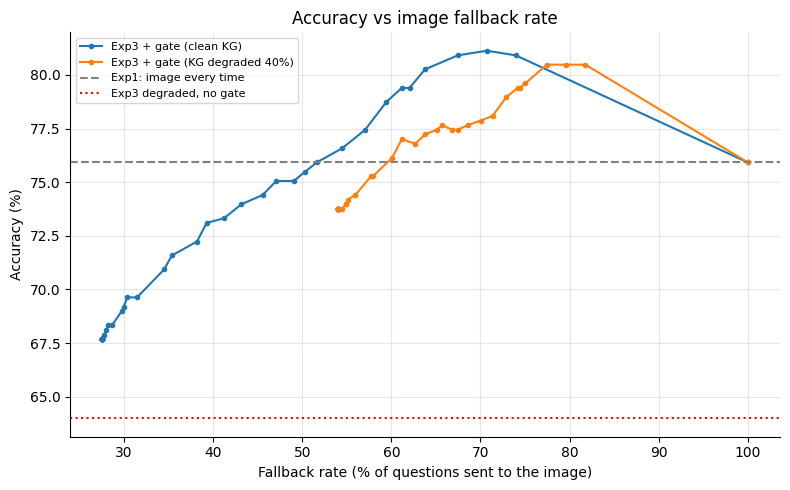

In [113]:
CONF_THR = 0.5
gate = lambda d, thr=CONF_THR: ((d.cov_missing == 1) | (d.conf < thr)).values

compose(ALL_DF[N3], ALL_DF[N1], gate(ALL_DF[N3]), N3G)                       # clean graph + gate
d3 = run_eval(N3D, exp3_front(pm_g, proj_g, DROP_PROB), val_items)            # degraded graph, no gate
compose(d3, ALL_DF[N1], gate(d3), N3DG)                                       # degraded graph + gate

def curve(front, img):
    f = front.set_index("idx"); i = img.set_index("idx").loc[f.index]
    rows = []
    for thr in np.linspace(0, 1, 41):
        fb = ((f.cov_missing == 1) | (f.conf < thr)).values
        rows.append((100 * fb.mean(), 100 * np.where(fb, i.correct.values, f.correct.values).mean()))
    return np.array(rows)

c_clean, c_deg = curve(ALL_DF[N3], ALL_DF[N1]), curve(d3, ALL_DF[N1])
plt.figure(figsize=(8, 5))
plt.plot(c_clean[:, 0], c_clean[:, 1], marker=".", label="Exp3 + gate (clean KG)")
plt.plot(c_deg[:, 0], c_deg[:, 1], marker=".", label=f"Exp3 + gate (KG degraded {int(DROP_PROB*100)}%)")
plt.axhline(ALL_SUM[N1]["accuracy"], ls="--", color="gray", label="Exp1: image every time")
plt.axhline(ALL_SUM[N3D]["accuracy"], ls=":", color="red", label="Exp3 degraded, no gate")
plt.xlabel("Fallback rate (% of questions sent to the image)"); plt.ylabel("Accuracy (%)")
plt.title("Accuracy vs image fallback rate"); plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{PROJECT_DIR}/results/gate_curve.png", dpi=300); plt.show()

one results table and the comparison plots

,method,accuracy
0,Chance,4.35
1,Question-only (logistic regression),39.26
2,Graph-only classifier (Step G),58.35


,n,accuracy,in_vocab_rate,latency_ms_mean,latency_ms_median,latency_ms_p95,image_passes_per_q,vlm_calls_per_q,fallback_rate
Exp3: KG tokens + LoRA,461.0,64.64,99.78,334.32,332.51,350.74,0.00,1.00,0.00
Control: Exp3 with wrong graph,461.0,32.54,99.57,334.32,333.68,346.17,0.00,1.00,0.00
"Exp1: image, no memory",461.0,75.92,92.62,140.32,137.60,158.02,1.00,1.00,0.00
Exp2: KG as text,461.0,88.29,96.75,141.92,135.15,232.11,0.55,1.27,54.66
Exp2: KG as text (degraded KG),461.0,85.25,95.44,138.10,136.66,227.80,0.69,1.15,69.20
Exp3 + gate,461.0,70.93,98.70,382.59,336.42,486.28,0.34,1.34,34.49
"Exp3 (degraded KG, no gate)",461.0,63.99,99.78,331.64,331.43,340.54,0.00,1.00,0.00
Exp3 + gate (degraded KG),461.0,75.27,96.96,412.19,463.21,483.88,0.58,1.58,57.70


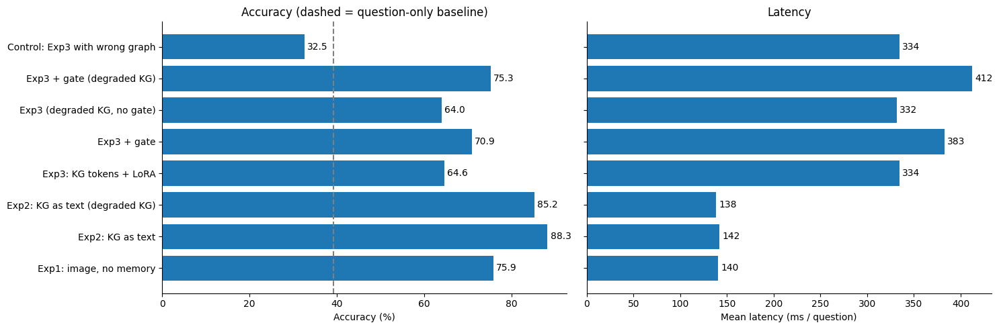

In [115]:
ref = pd.DataFrame([
    {"method": "Chance", "accuracy": 100 / num_answers},
    {"method": "Question-only (logistic regression)", "accuracy": 100 * question_only_acc},
    {"method": "Graph-only classifier (Step G)", "accuracy": 100 * float(globals().get("acc", np.nan))},
])

# Build a table with experiment names as rows
table = pd.DataFrame(ALL_SUM).T

# Remove internal entries such as _front2
table = table.loc[
    [name for name in table.index if not str(name).startswith("_")]
]

cols = [
    "n", "accuracy", "in_vocab_rate",
    "latency_ms_mean", "latency_ms_median", "latency_ms_p95",
    "image_passes_per_q", "vlm_calls_per_q", "fallback_rate"
]

display(ref.round(2))
display(table[cols].astype(float).round(2))

# Save summary
table[cols].to_csv(f"{PROJECT_DIR}/results/all_experiments_summary.csv")

# Plot experiments that are present in the summary table
main = [
    name for name in [N1, N2, N2D, N3, N3G, N3D, N3DG, NCTRL]
    if name in table.index
]

if main:
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))

    b = ax[0].barh(main, [table.loc[name, "accuracy"] for name in main])
    ax[0].bar_label(b, fmt="%.1f", padding=3)
    ax[0].axvline(100 * question_only_acc, ls="--", color="gray")
    ax[0].set_xlabel("Accuracy (%)")
    ax[0].set_title("Accuracy (dashed = question-only baseline)")

    b = ax[1].barh(main, [table.loc[name, "latency_ms_mean"] for name in main])
    ax[1].bar_label(b, fmt="%.0f", padding=3)
    ax[1].set_xlabel("Mean latency (ms / question)")
    ax[1].set_title("Latency")
    ax[1].set_yticklabels([])

    for a in ax:
        a.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{PROJECT_DIR}/results/comparison.png", dpi=300)
    plt.show()
else:
    print("No matching experiment names found in ALL_SUM.")

dedicated latency benchmark, same fixed questions for every method

This runs the real end-to-end pipelines, including actual fallbacks, on 100 questions, twice each, with GPU syncs and peak memory.

In [116]:
def with_fallback(front_fn, decide):
    def fn(it):
        out = front_fn(it)
        if decide(out):
            o1 = exp1_fn(it)
            return {**o1, "fallback": True, "vlm_calls": out.get("vlm_calls", 0) + 1, "conf": out.get("conf", np.nan)}
        return {**out, "fallback": False}
    return fn

gate_fn = lambda o: o.get("cov_missing", False) or o.get("conf", 1.0) < CONF_THR
bench_items = random.Random(0).sample(val_items, min(100, len(val_items)))
fns = {N1: exp1_fn,
       N2: with_fallback(exp2_front(0.0), lambda o: o["fallback"]),
       N3: exp3_front(pm_g, proj_g),
       N3G: with_fallback(exp3_front(pm_g, proj_g), gate_fn)}

def bench(fns, items, repeats=2):
    rows = []
    for name, fn in fns.items():
        for it in items[:3]: fn(it)
        torch.cuda.reset_peak_memory_stats(); lat = []
        for _ in range(repeats):
            for it in items:
                sync(); t = time.perf_counter(); fn(it); sync(); lat.append(1000 * (time.perf_counter() - t))
        rows.append({"method": name, "mean_ms": np.mean(lat), "median_ms": np.median(lat),
                     "p95_ms": np.percentile(lat, 95), "peak_gpu_GB": torch.cuda.max_memory_allocated() / 1e9})
    return pd.DataFrame(rows)

lat_df = bench(fns, bench_items); display(lat_df.round(1))
lat_df.to_csv(f"{PROJECT_DIR}/results/latency_benchmark.csv", index=False)

# Break-even: how many questions per image before storing a graph pays off?
l1 = lat_df.set_index("method").loc[N1, "mean_ms"]; l3 = lat_df.set_index("method").loc[N3, "mean_ms"]
for kappa in (1, 3):   # ASSUMPTION: building the graph costs kappa x one image-reading call
    print(f"If graph extraction costs {kappa}x an image pass: break-even after ~{kappa * l1 / max(l1 - l3, 1e-9):.1f} questions per image")

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


,method,mean_ms,median_ms,p95_ms,peak_gpu_GB
0,"Exp1: image, no memory",136.2,135.0,148.3,5.0
1,Exp2: KG as text,138.8,133.6,232.1,5.0
2,Exp3: KG tokens + LoRA,330.7,329.4,344.6,5.0
3,Exp3 + gate,383.2,336.4,489.8,5.0


If graph extraction costs 1x an image pass: break-even after ~136228026325.1 questions per image
If graph extraction costs 3x an image pass: break-even after ~408684078975.4 questions per image


In [117]:
from pathlib import Path
import json

# Validation image IDs from the evaluation set
val_ids = {str(item["image_id"]) for item in val_items}
print(f"Validation images: {len(val_ids)}")

# Find likely KG/scene-graph files in your project
root = Path(PROJECT_DIR)
candidates = [
    p for p in root.rglob("*")
    if p.is_file()
    and any(word in p.name.lower() for word in ("graph", "scene", "kg"))
    and p.suffix.lower() in {".json", ".jsonl", ".csv", ".tsv"}
]

print(f"Potential graph files found: {len(candidates)}")
for p in candidates[:30]:
    print(p.relative_to(root))

Validation images: 416
Potential graph files found: 11
results/Exp3_KG_tokens_LoRA.csv
results/Control_Exp3_with_wrong_graph.csv
results/Exp2_KG_as_text.csv
results/Exp2_KG_as_text_degraded_KG_.csv
results/Exp3_degraded_KG_no_gate_.csv
results/Exp3_gate_degraded_KG_.csv
configs/graph_vocab.json
data/raw/train_sceneGraphs.json
data/raw/val_sceneGraphs.json
data/processed/train_kg.jsonl
data/processed/val_kg.jsonl


In [118]:
# Search candidate files for validation image IDs
# (Reads files as text; does not change them.)

matches = []

for path in candidates:
    try:
        text = path.read_text(encoding="utf-8", errors="ignore")
        found = val_ids.intersection(
            image_id for image_id in val_ids if image_id in text
        )
        if found:
            matches.append((path, found))
    except Exception as e:
        print(f"Could not read {path.name}: {e}")

if matches:
    for path, found in matches:
        print(f"\n{path.relative_to(root)}")
        print(f"Validation IDs found: {len(found)} / {len(val_ids)}")
        print("Examples:", sorted(found)[:10])
else:
    print("No validation image IDs found in the candidate files.")


results/Exp3_KG_tokens_LoRA.csv
Validation IDs found: 9 / 416
Examples: ['1199', '1794', '2037', '2458', '392', '4086', '4347', '4363', '4450']

results/Control_Exp3_with_wrong_graph.csv
Validation IDs found: 7 / 416
Examples: ['1179', '1199', '2011', '2458', '392', '4086', '4347']

results/Exp2_KG_as_text.csv
Validation IDs found: 5 / 416
Examples: ['1199', '2037', '392', '4347', '4363']

results/Exp2_KG_as_text_degraded_KG_.csv
Validation IDs found: 3 / 416
Examples: ['1199', '392', '4363']

results/Exp3_degraded_KG_no_gate_.csv
Validation IDs found: 6 / 416
Examples: ['1179', '1199', '2388492', '392', '4347', '4356']

results/Exp3_gate_degraded_KG_.csv
Validation IDs found: 9 / 416
Examples: ['1179', '1199', '2037', '2388492', '3654', '3719', '392', '4347', '4356']

configs/graph_vocab.json
Validation IDs found: 3 / 416
Examples: ['1179', '1199', '392']

data/raw/train_sceneGraphs.json
Validation IDs found: 416 / 416
Examples: ['1159301', '1159853', '1159867', '1160008', '1179', '1

In [119]:
import json
from pathlib import Path

root = Path(PROJECT_DIR)
sample_ids = {"1179", "1199", "1794", "2037", "2458"}

def find_id_records(path, ids):
    """Return matching top-level graph records, checking common ID fields."""
    found = {}
    path = Path(path)

    if path.suffix == ".jsonl":
        with path.open(encoding="utf-8") as f:
            for line_no, line in enumerate(f, 1):
                try:
                    record = json.loads(line)
                except json.JSONDecodeError:
                    continue

                if not isinstance(record, dict):
                    continue

                record_ids = {
                    str(record.get(k, ""))
                    for k in ("image_id", "imageId", "id", "image")
                }
                hits = ids & record_ids
                for image_id in hits:
                    found[image_id] = {
                        "line": line_no,
                        "record_preview": str(record)[:500]
                    }

    else:
        with path.open(encoding="utf-8") as f:
            data = json.load(f)

        # Scene graph files are often dictionaries keyed by image ID.
        if isinstance(data, dict):
            for image_id in ids:
                if image_id in data:
                    found[image_id] = {
                        "record_preview": str(data[image_id])[:500]
                    }

        # Also check records in a list or nested structure.
        def walk(obj):
            if isinstance(obj, dict):
                record_ids = {
                    str(obj.get(k, ""))
                    for k in ("image_id", "imageId", "id", "image")
                }
                for image_id in ids & record_ids:
                    found.setdefault(image_id, {"record_preview": str(obj)[:500]})
                for value in obj.values():
                    walk(value)
            elif isinstance(obj, list):
                for value in obj:
                    walk(value)

        walk(data)

    return found


for relative_path in [
    "data/raw/train_sceneGraphs.json",
    "data/raw/val_sceneGraphs.json",
    "data/processed/train_kg.jsonl",
    "data/processed/val_kg.jsonl",
]:
    path = root / relative_path
    print(f"\n--- {relative_path} ---")
    if not path.exists():
        print("File not found")
        continue

    found = find_id_records(path, sample_ids)
    print(f"Matched records: {len(found)} / {len(sample_ids)}")
    for image_id, info in found.items():
        print(f"\nID {image_id}: {info}")


--- data/raw/train_sceneGraphs.json ---
Matched records: 5 / 5

ID 1179: {'record_preview': "{'width': 640, 'objects': {'3569206': {'name': 'walls', 'h': 320, 'relations': [], 'w': 620, 'attributes': ['light'], 'y': 2, 'x': 1}, '1627280': {'name': 'cabinet', 'h': 125, 'relations': [{'object': '1627301', 'name': 'to the right of'}, {'object': '1627261', 'name': 'to the left of'}, {'object': '1627260', 'name': 'to the left of'}, {'object': '1627262', 'name': 'to the left of'}, {'object': '1627276', 'name': 'to the left of'}, {'object': '1627259', 'name': 'to the left of'}, {'object': '162"}

ID 2458: {'record_preview': "{'width': 800, 'objects': {'3641773': {'name': 'desk', 'h': 202, 'relations': [{'object': '3641781', 'name': 'to the left of'}, {'object': '1549502', 'name': 'to the left of'}], 'w': 633, 'attributes': [], 'y': 320, 'x': 0}, '2234975': {'name': 'monitor', 'h': 155, 'relations': [{'object': '1549508', 'name': 'to the left of'}, {'object': '2217180', 'name': 'to the left o

In [122]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/KG_VLM_Research")
TRAIN_KG = ROOT / "data/processed/train_kg.jsonl"
VAL_KG   = ROOT / "data/processed/val_kg.jsonl"

def load_ids(path):
    ids = set()
    count = 0
    with path.open(encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            if not line.strip():
                continue
            count += 1
            record = json.loads(line)
            image_id = record.get("image_id")
            if image_id is not None:
                ids.add(str(image_id))
    return count, ids

for path in (TRAIN_KG, VAL_KG):
    print(f"{path}: {'FOUND' if path.exists() else 'MISSING'}")

if TRAIN_KG.exists() and VAL_KG.exists():
    n_train, train_ids = load_ids(TRAIN_KG)
    n_val, val_ids = load_ids(VAL_KG)
    overlap = train_ids & val_ids

    print(f"\nTrain KG: {n_train} records, {len(train_ids)} unique image IDs")
    print(f"Val KG:   {n_val} records, {len(val_ids)} unique image IDs")
    print(f"Overlap:  {len(overlap)} image IDs")
    print("Examples:", sorted(overlap)[:20])

    # Check the five sample validation IDs from your earlier output
    sample_ids = {"1179", "1199", "1794", "2037", "2458"}
    print("\nSample IDs in train KG:", sorted(sample_ids & train_ids))
    print("Sample IDs in val KG:  ", sorted(sample_ids & val_ids))
else:
    print("\nOne of the KG files is missing. Check the printed paths.")

/content/drive/MyDrive/KG_VLM_Research/data/processed/train_kg.jsonl: FOUND
/content/drive/MyDrive/KG_VLM_Research/data/processed/val_kg.jsonl: FOUND

Train KG: 74942 records, 74942 unique image IDs
Val KG:   10696 records, 10696 unique image IDs
Overlap:  0 image IDs
Examples: []

Sample IDs in train KG: ['1179', '1199', '1794', '2037', '2458']
Sample IDs in val KG:   []


demo, with the image, graph, output and accuracy

It runs the real pipeline: check memory, answer from the graph, fall back to the image if the graph is insufficient, and store what was learned. Calling it twice on the same question shows a memory hit.

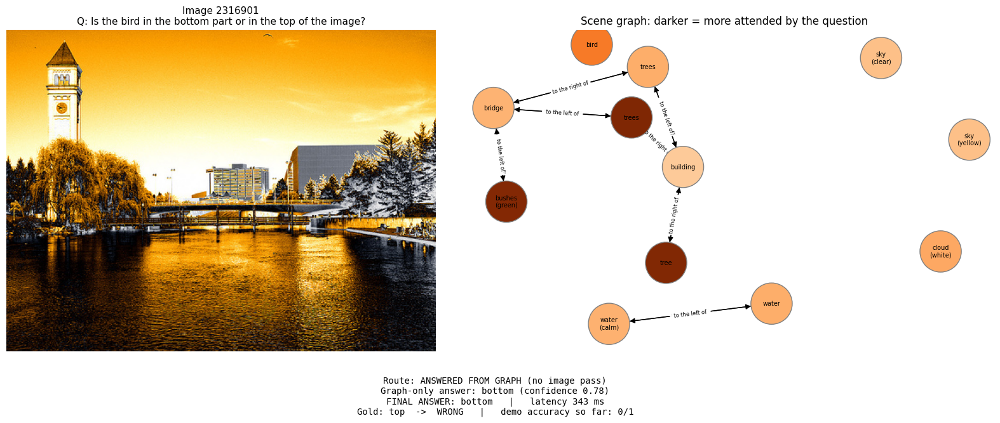

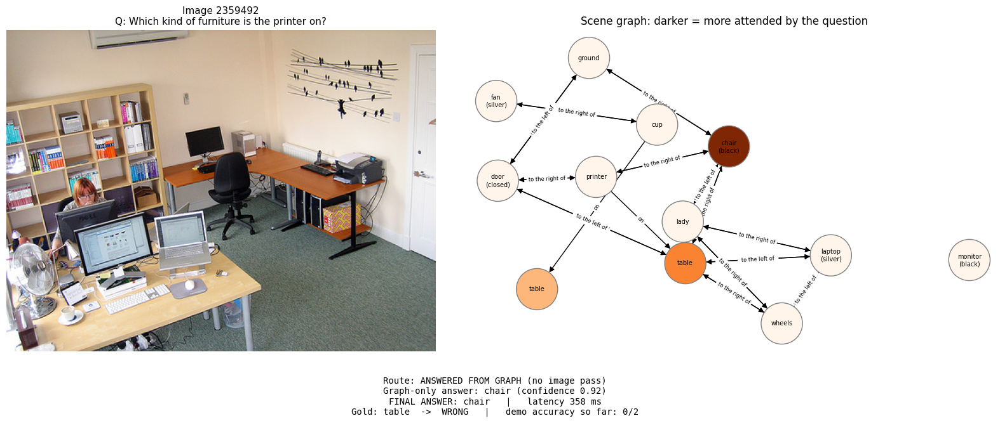

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


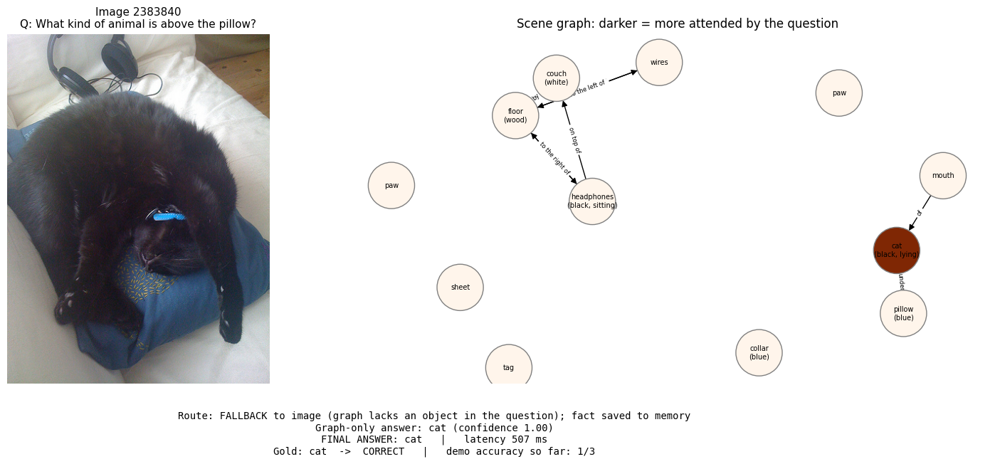

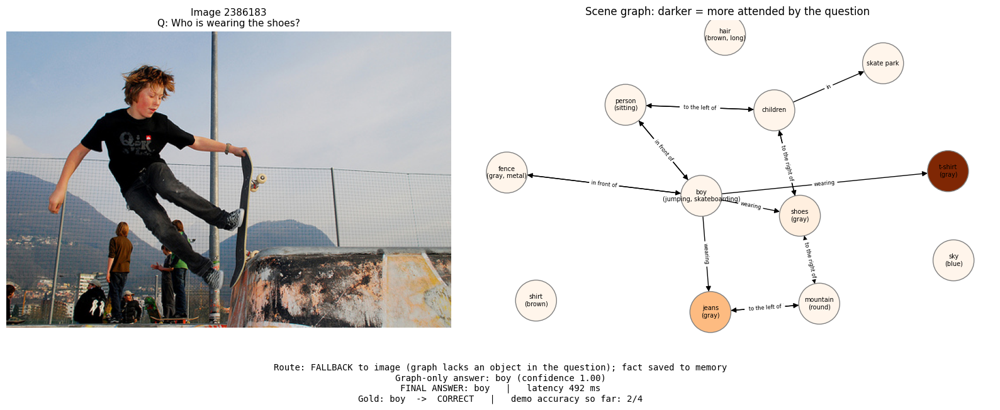

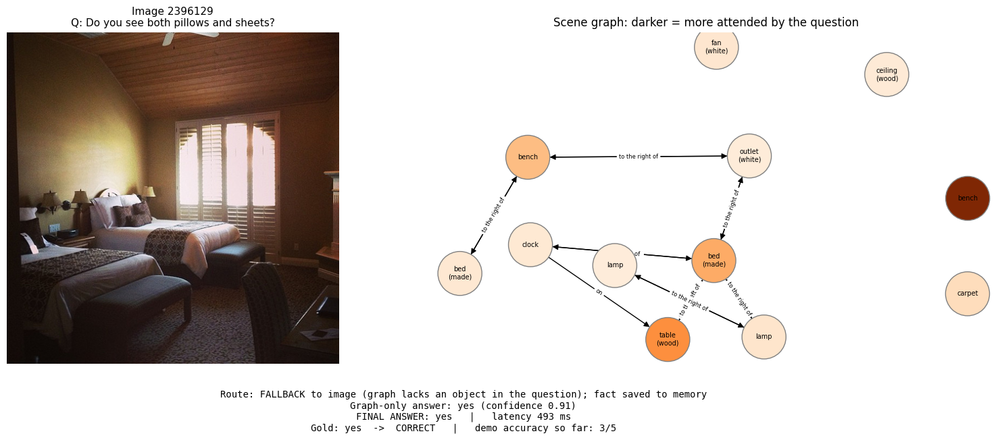

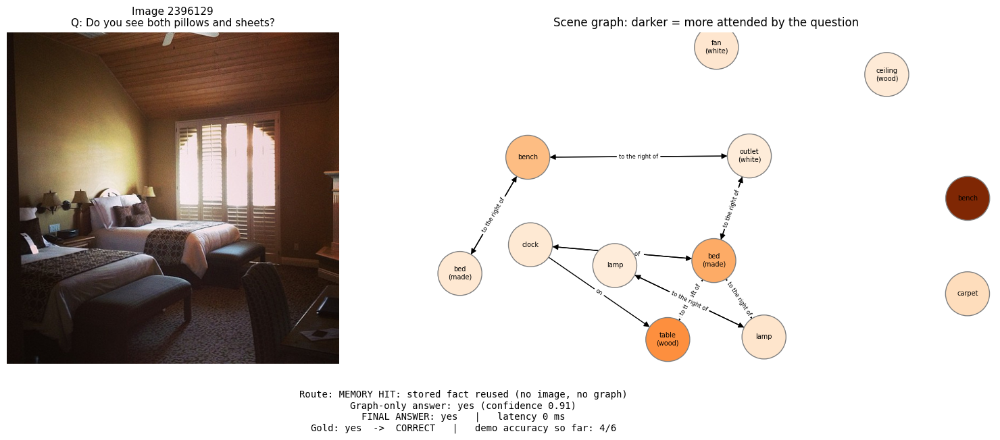

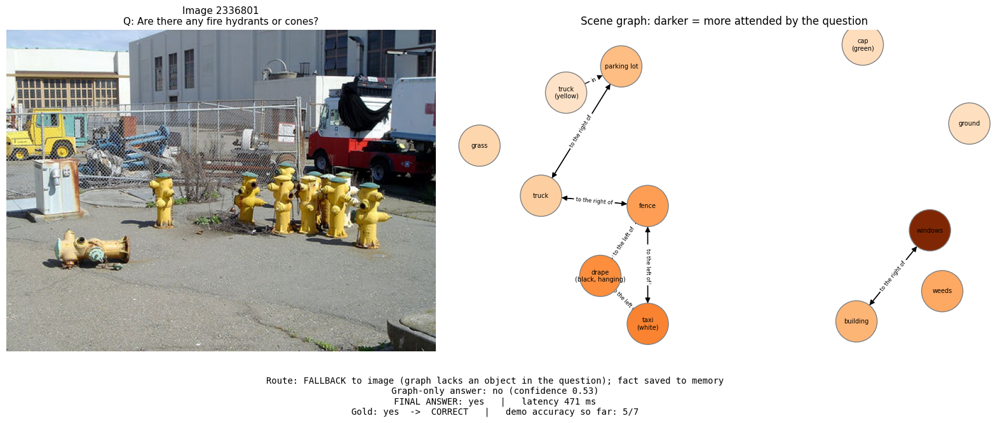


Full validation accuracy (n = 461):
  Exp1: image, no memory: 75.92%
  Exp2: KG as text: 88.29%
  Exp3: KG tokens + LoRA: 64.64%
  Exp3 + gate: 70.93%


In [123]:
import networkx as nx
FACT_MEMORY, DEMO_TALLY = {}, []

def draw_graph(ax, kg, attn, max_nodes=12):
    node_ix = {n["id"]: i for i, n in enumerate(kg["nodes"])}
    keep = list(np.argsort(-attn)[:max_nodes])
    G = nx.DiGraph(); a = attn / max(attn.max(), 1e-9)
    for i in keep:
        n = kg["nodes"][i]; at = ", ".join(n["attributes"][:2])
        G.add_node(i, label=n["name"] + (f"\n({at})" if at else ""))
    elabels = {}
    for e in kg["edges"]:
        s, t = node_ix[e["source"]], node_ix[e["target"]]
        if s in keep and t in keep and s != t:
            G.add_edge(s, t); elabels[(s, t)] = e["relation"]
    pos = nx.spring_layout(G, seed=0, k=1.3)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[a[i] for i in G.nodes], cmap=plt.cm.Oranges,
                           vmin=0, vmax=1, node_size=2200, edgecolors="gray")
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "label"), font_size=7, ax=ax)
    nx.draw_networkx_edges(G, pos, ax=ax, arrowsize=12, node_size=2200)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=elabels, font_size=6, ax=ax)
    ax.set_title("Scene graph: darker = more attended by the question"); ax.axis("off")

def demo(i=None, image_id=None, question=None, gold=None, drop_prob=0.0, thr=CONF_THR):
    if image_id is None:
        it = val_items[random.randrange(len(val_items)) if i is None else i]
    else:
        it = make_item(-1, image_id, question, norm_pred(gold) if gold else None)
    key = (it["image_id"], norm_pred(it["question"]))

    sync(); t0 = time.perf_counter()
    if key in FACT_MEMORY:
        stage, final, route = None, FACT_MEMORY[key], "MEMORY HIT: stored fact reused (no image, no graph)"
    else:
        stage = graph_stage(pm_g, proj_g, it, drop_prob)
        if stage["cov_missing"] or stage["conf"] < thr:
            why = "graph lacks an object in the question" if stage["cov_missing"] else f"low confidence ({stage['conf']:.2f} < {thr})"
            final = norm_pred(exp1_fn(it)["pred"]); FACT_MEMORY[key] = final
            route = f"FALLBACK to image ({why}); fact saved to memory"
        else:
            final, route = norm_pred(stage["pred"]), "ANSWERED FROM GRAPH (no image pass)"
    sync(); ms = 1000 * (time.perf_counter() - t0)
    if stage is None:
        stage = graph_stage(pm_g, proj_g, it, drop_prob)          # only needed to draw the graph

    g_ans = norm_pred(stage["pred"])
    kg = convert_gqa_to_kg(it["image_id"], stage["scene"])
    fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.2]})
    ax[0].imshow(get_image(it["image_id"])); ax[0].axis("off")
    ax[0].set_title(f"Image {it['image_id']}\nQ: {it['question']}", fontsize=11)
    draw_graph(ax[1], kg, stage["attn"])
    lines = [f"Route: {route}", f"Graph-only answer: {g_ans} (confidence {stage['conf']:.2f})", f"FINAL ANSWER: {final}   |   latency {ms:.0f} ms"]
    if it["answer"] is not None:
        ok = norm_pred(final) == norm_pred(it["answer"]); DEMO_TALLY.append(int(ok))
        lines.append(f"Gold: {norm_pred(it['answer'])}  ->  {'CORRECT' if ok else 'WRONG'}   |   demo accuracy so far: {sum(DEMO_TALLY)}/{len(DEMO_TALLY)}")
    fig.text(0.5, 0.01, "\n".join(lines), ha="center", fontsize=10, family="monospace")
    plt.tight_layout(rect=[0, 0.14, 1, 1]); plt.show()

for _ in range(4):
    demo()                          # random held-out questions
demo(i=0); demo(i=0)                # second call = memory hit
demo(i=5, drop_prob=1.0)            # object removed from the graph -> forces a fallback

print("\nFull validation accuracy (n = %d):" % len(val_items))
for n in [N1, N2, N3, N3G]:
    print(f"  {n}: {ALL_SUM[n]['accuracy']:.2f}%")

 (optional, run last): question-only LoRA ablation

This is the strongest answer to “does the graph help the VLM, or is the question enough?” It removes the graph LoRA, so run it only after everything above, including the demo. The graph-run weights are saved on Drive as qwen_graph_best.pt.

In [124]:
qwen = pm_g.unload(); VLM = qwen; torch.cuda.empty_cache()
pm_q, _ = run_experiment(use_graph=False, tag="question_only")
run_eval("Ablation: question-only + LoRA",
         lambda it: dict(zip(("pred", "conf"), gen_graph(pm_q, None, it, use_graph=False)), vlm_calls=1), val_items)

/tmp/ipykernel_9659/2209508978.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DTYPE == torch.float16))


[question_only] trainable: LoRA 1,089,536
[question_only] epoch 1/5 | train 1.2228 | dev 0.6052 | 29s
[question_only] epoch 2/5 | train 0.5611 | dev 0.5710 | 29s
[question_only] epoch 3/5 | train 0.5308 | dev 0.5702 | 30s
[question_only] epoch 4/5 | train 0.5007 | dev 0.5609 | 29s
[question_only] epoch 5/5 | train 0.4853 | dev 0.5604 | 29s
[question_only] best dev loss: 0.5604 (best epoch weights restored)


Ablation: question-only + LoRA:   0%|          | 0/461 [00:00<?, ?it/s]

Ablation: question-only + LoRA: acc 47.51% | in-vocab 99.6% | 98 ms/q | image passes/q 0.00 | fallback 0.0%


,idx,question,gold,pred,correct,in_vocab,latency_ms,image_passes,vlm_calls,fallback,conf,cov_missing,name
0,0,Do you see both pillows and sheets?,yes,yes,1,1,101.401775,0,1,0,0.650966,0,Ablation: question-only + LoRA
1,1,Are there any umbrellas or bags?,yes,no,0,1,97.744119,0,1,0,0.705735,0,Ablation: question-only + LoRA
2,2,Are there any books on the table?,yes,yes,1,1,95.667852,0,1,0,0.531052,0,Ablation: question-only + LoRA
3,3,Does the team wear shirts?,yes,yes,1,1,96.630101,0,1,0,0.932292,0,Ablation: question-only + LoRA
4,4,Are there sheep or horses?,yes,yes,1,1,93.866785,0,1,0,0.621702,0,Ablation: question-only + LoRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...
456,456,What animal is standing in the field?,horse,horse,1,1,99.104438,0,1,0,0.534100,0,Ablation: question-only + LoRA
457,457,Which kind of animal is white?,horse,dog,0,1,99.077231,0,1,0,0.358779,0,Ablation: question-only + LoRA
458,458,What is the animal on the snow?,horse,dog,0,1,97.566827,0,1,0,0.525488,0,Ablation: question-only + LoRA
459,459,What animal is to the right of the truck?,horse,horse,1,1,97.306169,0,1,0,0.695246,0,Ablation: question-only + LoRA


In [125]:
# Read-only audit of the image IDs used by Exp3

def ids_in(records):
    return {str(r["imageId"]) for r in records}

train_q_ids = ids_in(balanced_train)
val_q_ids   = ids_in(balanced_val)
train_g_ids = set(map(str, train_graphs.keys()))
val_g_ids   = set(map(str, val_graphs.keys()))

print("Question image IDs:")
print("  balanced_train:", len(train_q_ids))
print("  balanced_val:  ", len(val_q_ids))
print("  overlap:", len(train_q_ids & val_q_ids))

print("\nGraph coverage:")
print("  train question IDs with train graphs:", len(train_q_ids & train_g_ids))
print("  train question IDs only in val graphs:", len((train_q_ids & val_g_ids) - train_g_ids))
print("  val question IDs with val graphs:", len(val_q_ids & val_g_ids))
print("  val question IDs only in train graphs:", len((val_q_ids & train_g_ids) - val_g_ids))

print("\nExp3 train/dev IDs that would fall back to val_graphs:")
print(sorted((train_q_ids & val_g_ids) - train_g_ids)[:30])

Question image IDs:
  balanced_train: 1660
  balanced_val:   416
  overlap: 0

Graph coverage:
  train question IDs with train graphs: 1660
  train question IDs only in val graphs: 0
  val question IDs with val graphs: 0
  val question IDs only in train graphs: 416

Exp3 train/dev IDs that would fall back to val_graphs:
[]


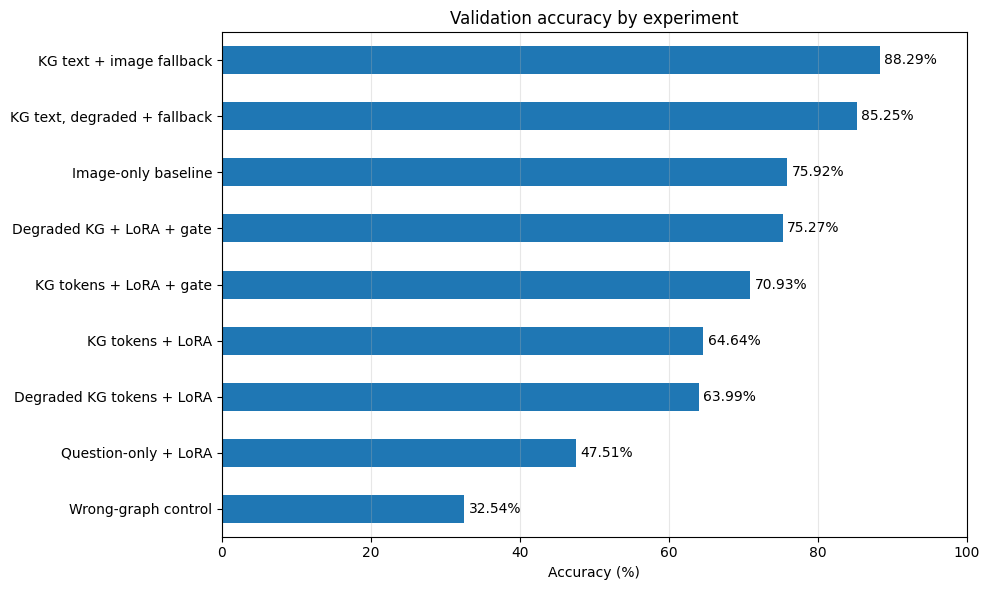

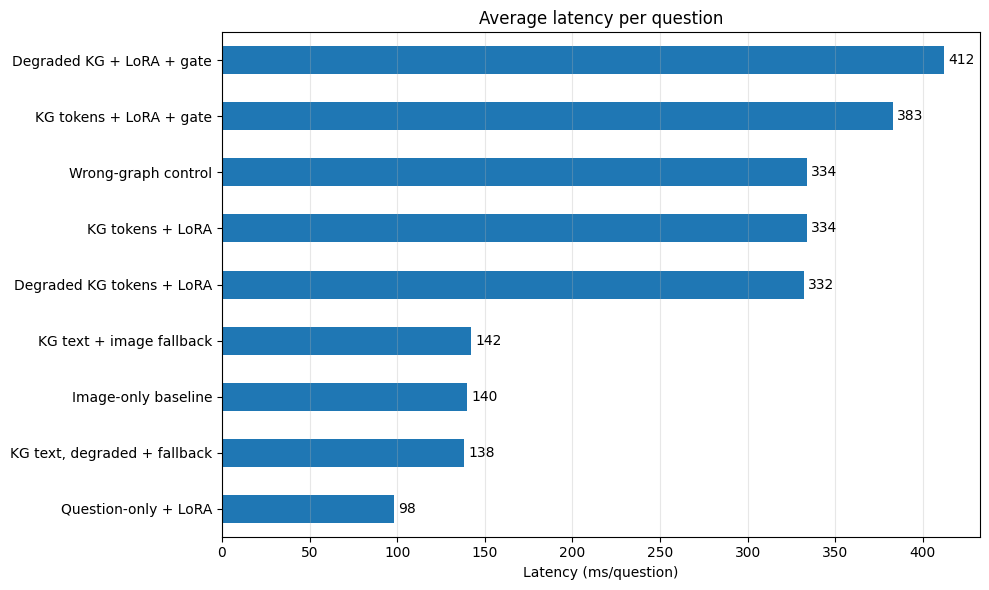

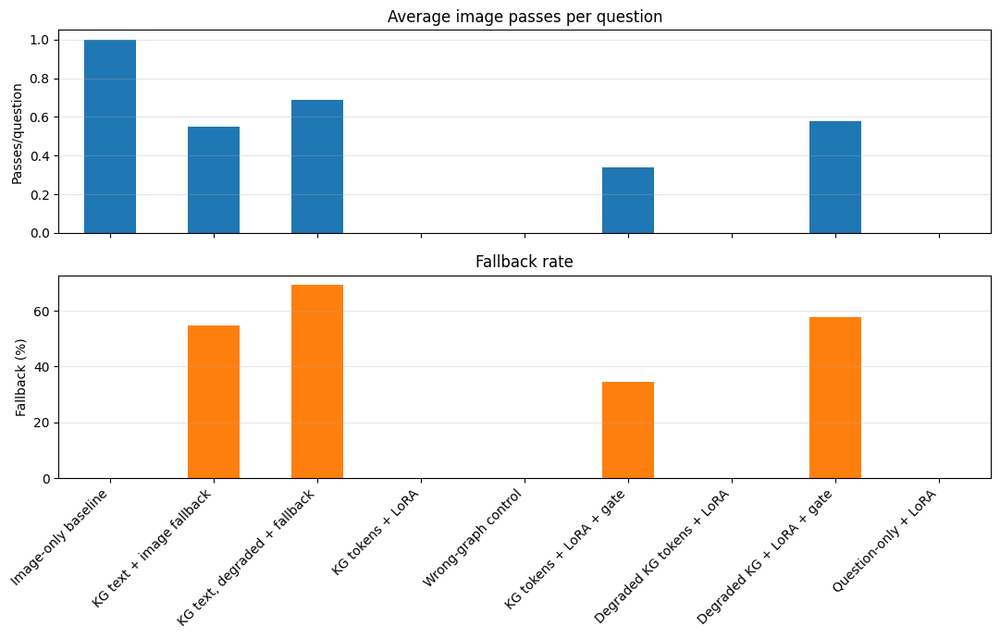

,Accuracy,Latency (ms/q),Image passes/q,Fallback (%)
Experiment,,,,
Image-only baseline,75.92,140,1.00,0.0
KG text + image fallback,88.29,142,0.55,54.7
"KG text, degraded + fallback",85.25,138,0.69,69.2
KG tokens + LoRA,64.64,334,0.00,0.0
Wrong-graph control,32.54,334,0.00,0.0
KG tokens + LoRA + gate,70.93,383,0.34,34.5
Degraded KG tokens + LoRA,63.99,332,0.00,0.0
Degraded KG + LoRA + gate,75.27,412,0.58,57.7
Question-only + LoRA,47.51,98,0.00,0.0


In [126]:
import pandas as pd
import matplotlib.pyplot as plt

# Results shared in our conversation
results = [
    {"Experiment": "Image-only baseline", "Accuracy": 75.92, "Latency (ms/q)": 140,
     "Image passes/q": 1.00, "Fallback (%)": 0.0},
    {"Experiment": "KG text + image fallback", "Accuracy": 88.29, "Latency (ms/q)": 142,
     "Image passes/q": 0.55, "Fallback (%)": 54.7},
    {"Experiment": "KG text, degraded + fallback", "Accuracy": 85.25, "Latency (ms/q)": 138,
     "Image passes/q": 0.69, "Fallback (%)": 69.2},
    {"Experiment": "KG tokens + LoRA", "Accuracy": 64.64, "Latency (ms/q)": 334,
     "Image passes/q": 0.00, "Fallback (%)": 0.0},
    {"Experiment": "Wrong-graph control", "Accuracy": 32.54, "Latency (ms/q)": 334,
     "Image passes/q": 0.00, "Fallback (%)": 0.0},
    {"Experiment": "KG tokens + LoRA + gate", "Accuracy": 70.93, "Latency (ms/q)": 383,
     "Image passes/q": 0.34, "Fallback (%)": 34.5},
    {"Experiment": "Degraded KG tokens + LoRA", "Accuracy": 63.99, "Latency (ms/q)": 332,
     "Image passes/q": 0.00, "Fallback (%)": 0.0},
    {"Experiment": "Degraded KG + LoRA + gate", "Accuracy": 75.27, "Latency (ms/q)": 412,
     "Image passes/q": 0.58, "Fallback (%)": 57.7},
    {"Experiment": "Question-only + LoRA", "Accuracy": 47.51, "Latency (ms/q)": 98,
     "Image passes/q": 0.00, "Fallback (%)": 0.0},
]

df = pd.DataFrame(results).set_index("Experiment")

# Accuracy
ax = df["Accuracy"].sort_values().plot(kind="barh", figsize=(10, 6))
ax.set_title("Validation accuracy by experiment")
ax.set_xlabel("Accuracy (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()

# Latency
ax = df["Latency (ms/q)"].sort_values().plot(kind="barh", figsize=(10, 6))
ax.set_title("Average latency per question")
ax.set_xlabel("Latency (ms/question)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

# Image passes and fallback rate
ax = df[["Image passes/q", "Fallback (%)"]].plot(
    kind="bar", subplots=True, figsize=(11, 7), layout=(2, 1),
    legend=False, sharex=True
)
ax[0, 0].set_title("Average image passes per question")
ax[0, 0].set_ylabel("Passes/question")
ax[1, 0].set_title("Fallback rate")
ax[1, 0].set_ylabel("Fallback (%)")
ax[1, 0].set_xlabel("")
for a in [ax[0, 0], ax[1, 0]]:
    a.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(df)